## IMPORT DES BIBLIOTHÈQUES

Importation de toutes les bibliothèques nécessaires pour :
- Manipulation de données (pandas, numpy)
- Clustering (scikit-learn, scipy)
- Visualisation (matplotlib, seaborn)
- Métriques d'évaluation
- Explicabilité (SHAP, XGBoost)
- Réduction de dimension pour visualisation


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
    confusion_matrix, classification_report, accuracy_score
)
from sklearn.model_selection import train_test_split
import xgboost as xgb
import shap
import warnings
warnings.filterwarnings('ignore')

# Style des graphiques
# Configuration matplotlib
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['savefig.dpi'] = 600
matplotlib.rcParams['figure.figsize'] = (14, 8)


print("Bibliothèques importées avec succès")


Bibliothèques importées avec succès


## CLASSE K-MEDOIDS PERSONNALISÉE
Implémentation from-scratch de K-Medoids (Partitioning Around Medoids - PAM)
car scikit-learn ne fournit pas K-Medoids dans sa version standard.
Algorithme PAM avec optimisation greedy pour la sélection des medoids.

    Paramètres:
    n_clusters : int, default=8
        Nombre de clusters à former.
    max_iter : int, default=300
        Nombre maximum d'itérations.
    random_state : int, default=None
        Seed pour la reproductibilité.
    metric : str, default='euclidean'
        Métrique de distance ('euclidean', 'manhattan', etc.).



In [7]:
class KMedoids:
    def __init__(self, n_clusters=8, max_iter=300, random_state=None, metric='euclidean'):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.metric = metric
        self.medoids_indices_ = None
        self.medoids_ = None
        self.labels_ = None
        self.inertia_ = None  # Somme des distances aux medoids
        
    def _compute_distances(self, X, medoids):
        """Calcule les distances entre tous les points et les medoids."""
        return cdist(X, medoids, metric=self.metric)
    
    def _assign_clusters(self, distances):
        """Assigne chaque point au medoid le plus proche."""
        return np.argmin(distances, axis=1)
    
    def _compute_cost(self, X, labels, medoids_indices):
        """Calcule le coût total (somme des distances aux medoids)."""
        total_cost = 0
        for k in range(self.n_clusters):
            cluster_points = X[labels == k]
            if len(cluster_points) > 0:
                medoid = X[medoids_indices[k]]
                total_cost += np.sum(cdist(cluster_points, medoid.reshape(1, -1), metric=self.metric))
        return total_cost
    
    def fit(self, X):
        """
        Entraîne le modèle K-Medoids sur les données X.
        
        Paramètres:
        -----------
        X : array-like, shape (n_samples, n_features)
            Données d'entrée.
        """
        np.random.seed(self.random_state)
        n_samples = X.shape[0]
        
        # Initialisation aléatoire des medoids
        self.medoids_indices_ = np.random.choice(n_samples, self.n_clusters, replace=False)
        self.medoids_ = X[self.medoids_indices_].copy()
        
        # Calcul initial des distances et assignation
        distances = self._compute_distances(X, self.medoids_)
        self.labels_ = self._assign_clusters(distances)
        old_cost = self._compute_cost(X, self.labels_, self.medoids_indices_)
        
        # Phase d'optimisation (PAM)
        for iteration in range(self.max_iter):
            improved = False
            
            for k in range(self.n_clusters):
                current_medoid_idx = self.medoids_indices_[k]
                cluster_members = np.where(self.labels_ == k)[0]
                
                if len(cluster_members) == 0:
                    continue
                
                # Tester chaque point du cluster comme nouveau medoid
                for candidate_idx in cluster_members:
                    if candidate_idx == current_medoid_idx:
                        continue
                    
                    # Créer une copie temporaire des indices de medoids
                    temp_medoids_indices = self.medoids_indices_.copy()
                    temp_medoids_indices[k] = candidate_idx
                    
                    # Recalculer les assignations avec le nouveau medoid
                    temp_medoids = X[temp_medoids_indices]
                    temp_distances = self._compute_distances(X, temp_medoids)
                    temp_labels = self._assign_clusters(temp_distances)
                    
                    # Calculer le nouveau coût
                    new_cost = self._compute_cost(X, temp_labels, temp_medoids_indices)
                    
                    # Si amélioration, conserver le changement
                    if new_cost < old_cost:
                        self.medoids_indices_ = temp_medoids_indices
                        self.medoids_ = X[self.medoids_indices_].copy()
                        self.labels_ = temp_labels
                        old_cost = new_cost
                        improved = True
                        break
                
                if improved:
                    break
            
            if not improved:
                break
        
        # Recalcul final
        distances = self._compute_distances(X, self.medoids_)
        self.labels_ = self._assign_clusters(distances)
        self.inertia_ = old_cost
        
        return self
    
    def predict(self, X):
        """
        Prédit les labels de cluster pour de nouveaux points.
        
        Paramètres:
        -----------
        X : array-like, shape (n_samples, n_features)
            Nouveaux points à classifier.
            
        Retourne:
        ---------
        labels : ndarray, shape (n_samples,)
            Index du cluster le plus proche pour chaque point.
        """
        distances = self._compute_distances(X, self.medoids_)
        return self._assign_clusters(distances)
    
    def fit_predict(self, X):
        """Fit et predict en une seule étape."""
        self.fit(X)
        return self.labels_


# Test rapide de la classe
print("Classe KMedoids définie avec succès")
print("Méthodes disponibles: fit(), predict(), fit_predict()")

Classe KMedoids définie avec succès
Méthodes disponibles: fit(), predict(), fit_predict()


## CHARGEMENT DES DONNÉES PRÉ-TRAITÉES

Chargement du fichier de features déjà standardisées (7 features finales).
Ce fichier a été généré lors de la phase précedente de feature engineering.

In [8]:
# Chemin vers la racine du projet
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
DATA_DIR = os.path.join(BASE_DIR, "data", "processed")
FEATURES_PATH = os.path.join(DATA_DIR, "uci_features_scaled.csv")

FEATURES_FINAL = [
    'mean_load',      # Consommation moyenne
    'load_cv',        # Coefficient de variation (volatilité)
    'load_factor',    # Facteur de charge
    'day_night_ratio', # Ratio jour/nuit
    'max_load',       # Charge maximale
    'num_peaks',      # Nombre de pics
    'is_weekend'      # Indicateur weekend
]
IMAGES_DIR = os.path.join(BASE_DIR, "results", "images")
# Dossier de sortie pour les figures
os.makedirs(IMAGES_DIR, exist_ok=True)

# Chargement des données
df_scaled = pd.read_csv(FEATURES_PATH)

# Vérification que toutes les features sont présentes
missing_features = [f for f in FEATURES_FINAL if f not in df_scaled.columns]
if missing_features:
    raise ValueError(f"Features manquantes: {missing_features}")

# Extraction de la matrice X (déjà standardisée)
X = df_scaled[FEATURES_FINAL].values

print("DONNÉES CHARGÉES : ")

print(f"Chemin: {FEATURES_PATH}")
print(f"la forme du dataset: {df_scaled.shape}")
print(f"Nombre des Features utilisées ({len(FEATURES_FINAL)}):")
for i, feat in enumerate(FEATURES_FINAL, 1):
    print(f"  {i}. {feat}")
print(f"\nLa forme de la matrice X (matrice features): {X.shape}")
print(f"\nAperçu des 5 premières lignes:")
print(df_scaled[FEATURES_FINAL].head())

DONNÉES CHARGÉES : 
Chemin: d:\projet\Projet clustering\Projet household clustering\data\processed\uci_features_scaled.csv
la forme du dataset: (1431, 7)
Nombre des Features utilisées (7):
  1. mean_load
  2. load_cv
  3. load_factor
  4. day_night_ratio
  5. max_load
  6. num_peaks
  7. is_weekend

La forme de la matrice X (matrice features): (1431, 7)

Aperçu des 5 premières lignes:
   mean_load   load_cv  load_factor  day_night_ratio  max_load  num_peaks  \
0   3.028354 -2.169601     2.339396        -0.736732  1.001042   0.215897   
1   1.053846 -1.287724     0.783119         0.565918  0.463081  -0.601428   
2   0.159249  1.230284    -1.069827         1.324604  1.461812   0.215897   
3   1.090323 -0.080724     0.959308        -0.267681  0.362139  -0.601428   
4   0.247135 -0.217598    -0.035701        -0.080725  0.282573   0.215897   

   is_weekend  
0    1.586181  
1   -0.630445  
2   -0.630445  
3   -0.630445  
4   -0.630445  


# EXPLORATION RAPIDE DES DONNÉES
Visualisation des distributions et corrélations des 7 features finales
pour comprendre la structure des données avant clustering.


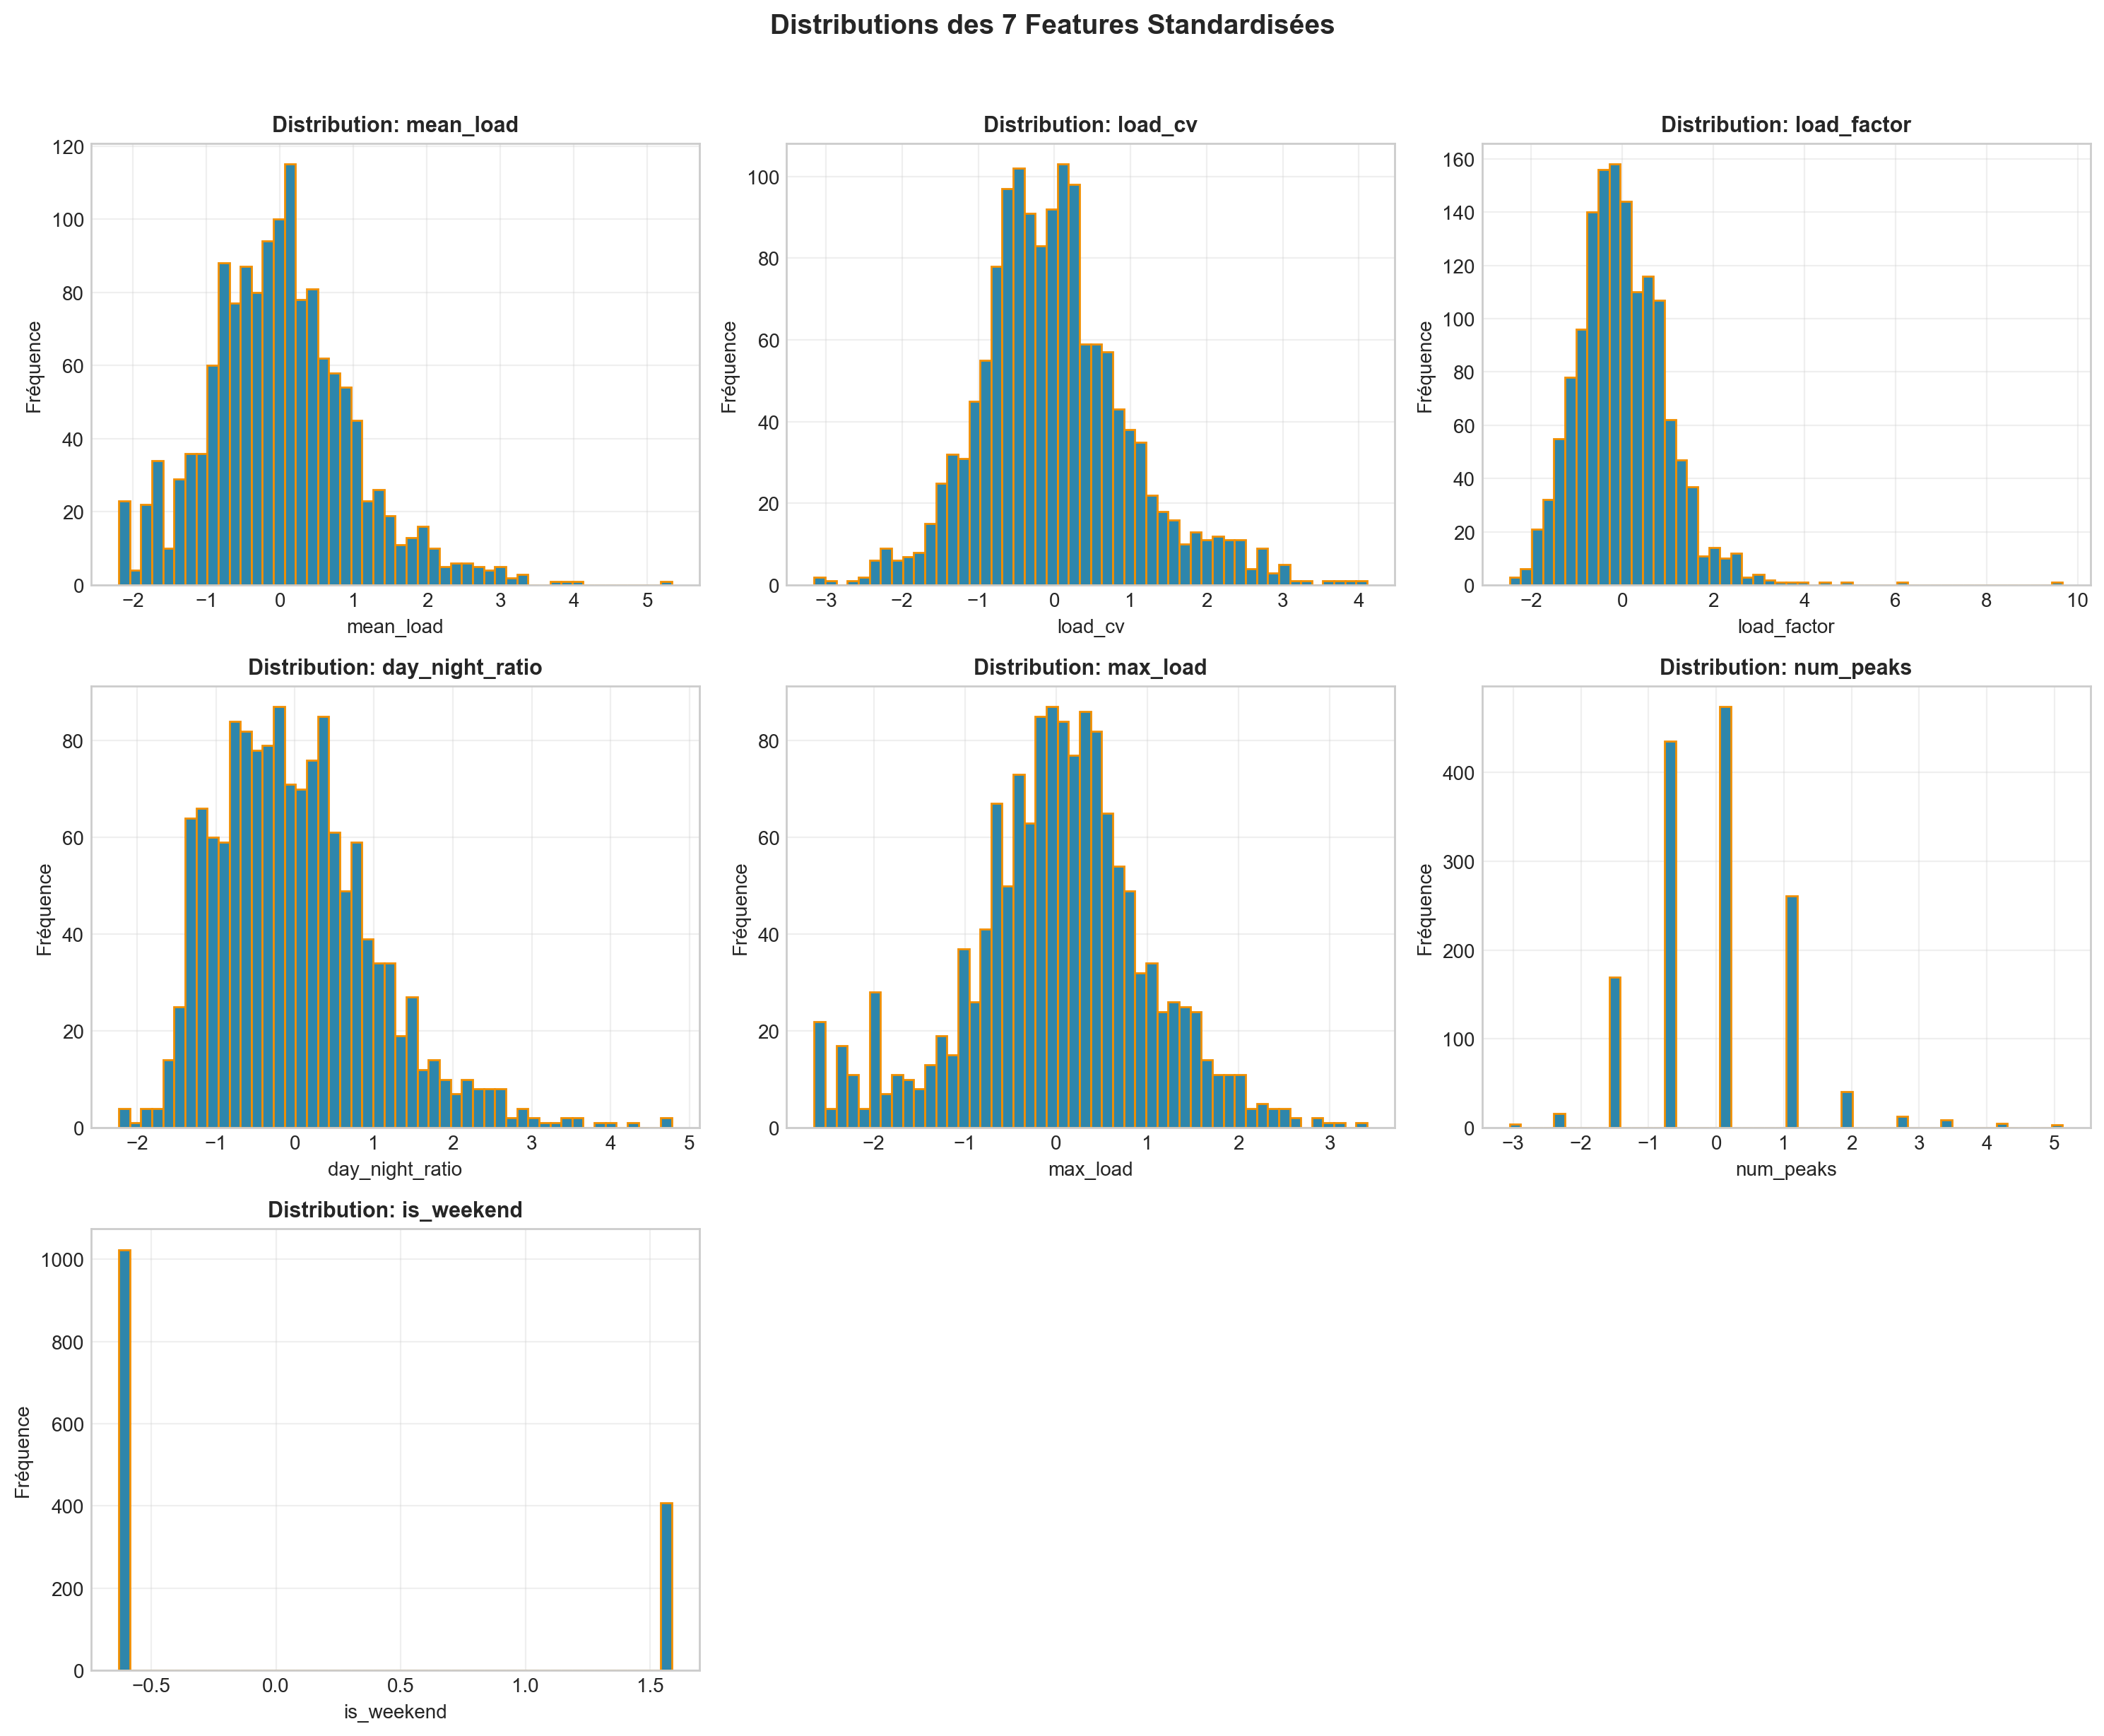

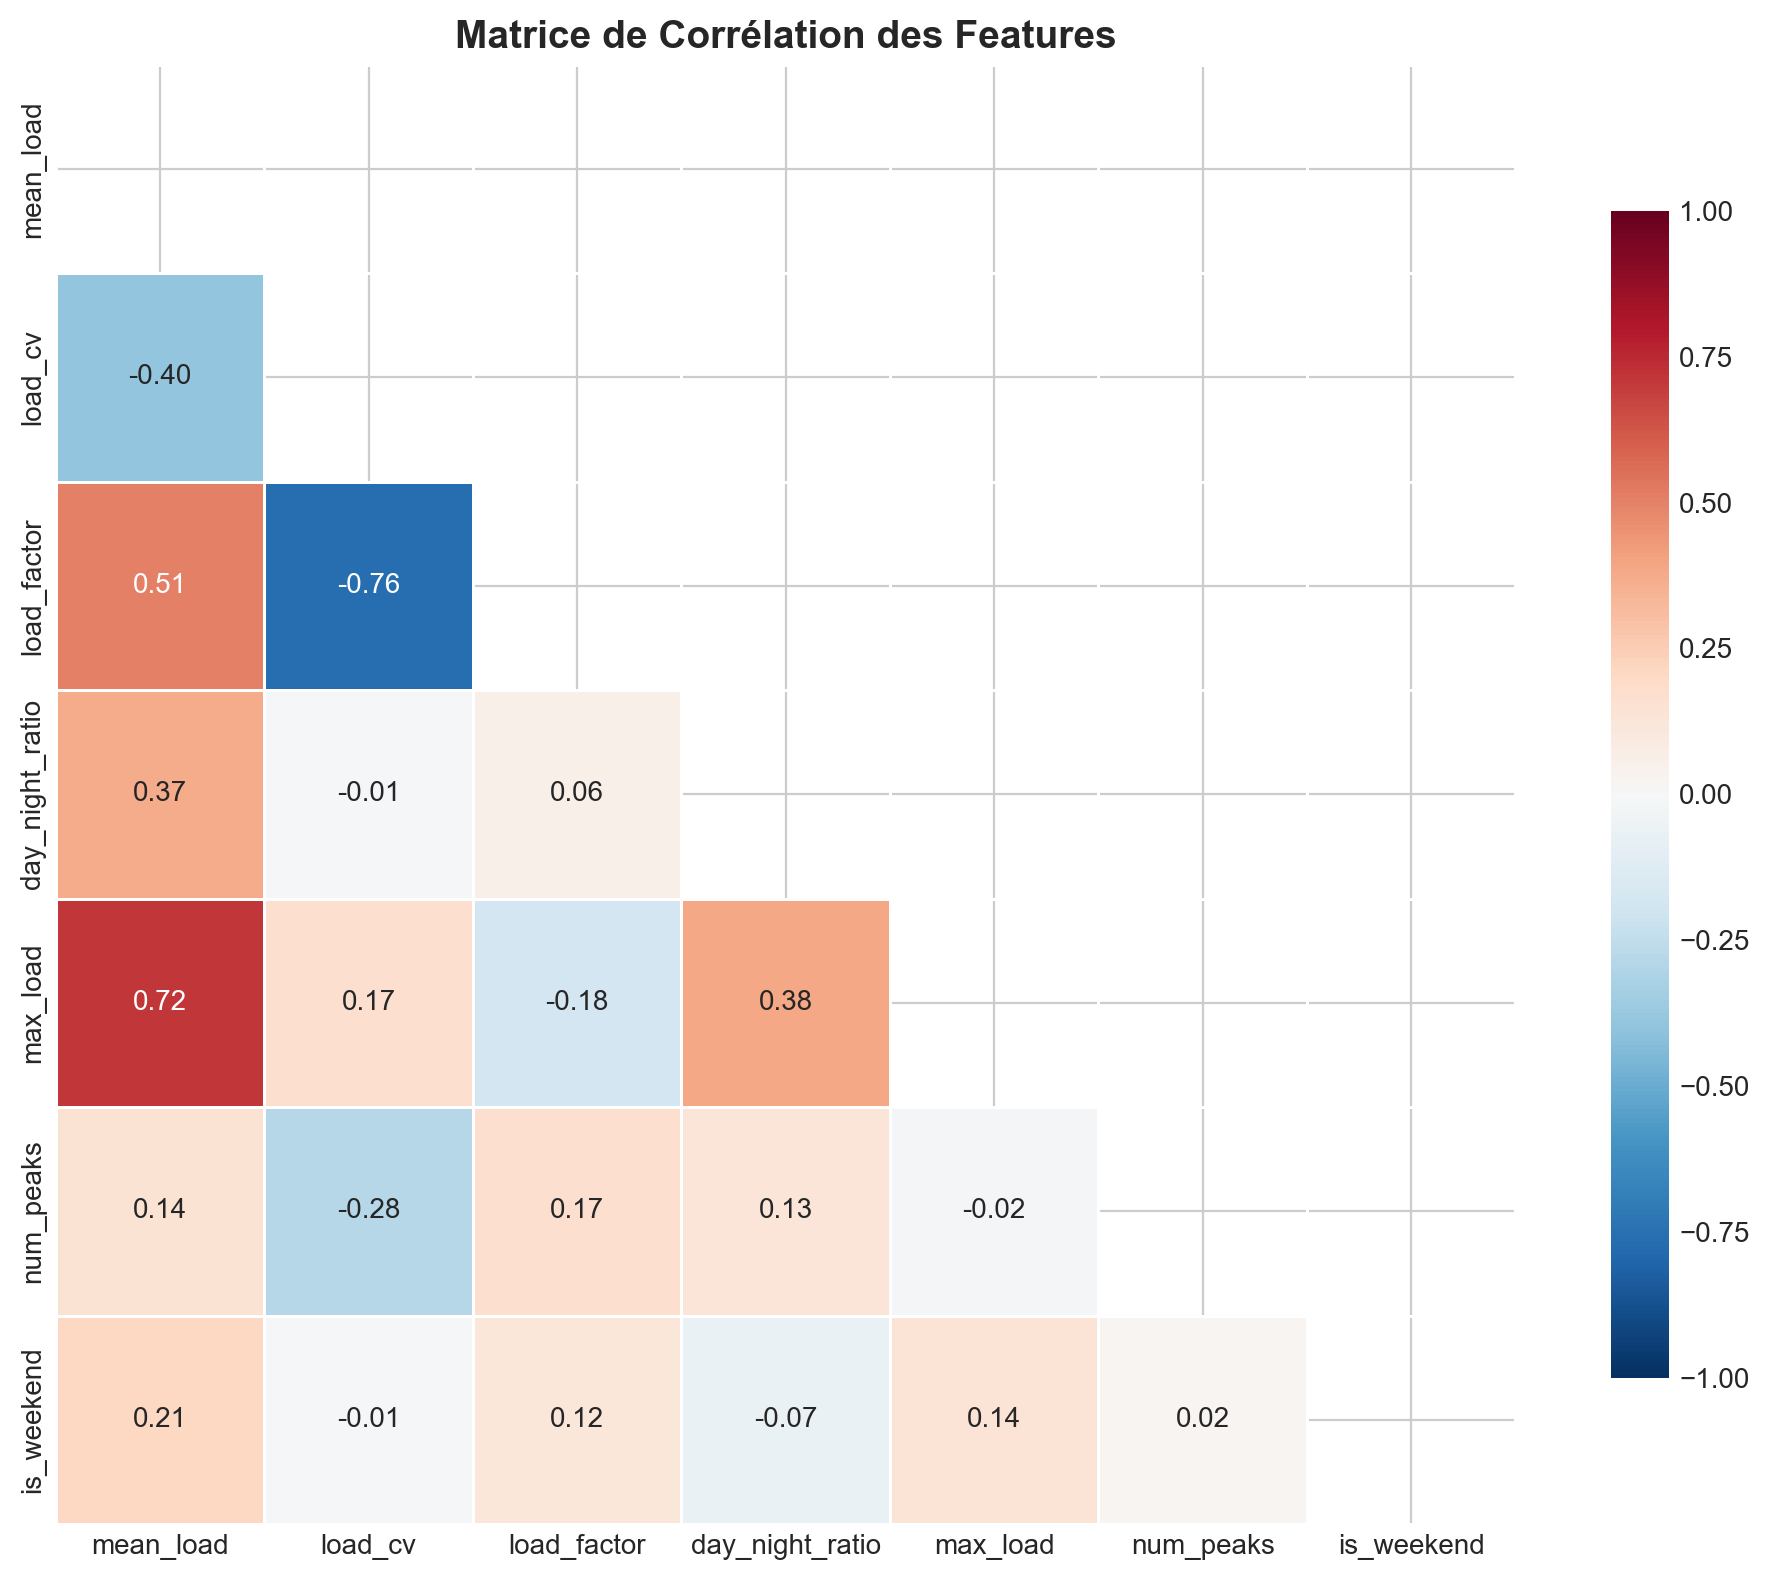

=== EXPLORATION TERMINÉE ===
Corrélation max (hors diagonale): 0.761


In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for idx, col in enumerate(FEATURES_FINAL):
    ax = axes[idx]
    ax.hist(df_scaled[col], bins=50, color='#2E86AB', edgecolor='#F18F01', alpha=1)
    ax.set_title(f'Distribution: {col}', fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Fréquence')
    ax.grid(True, alpha=0.3)

# Supprimer les axes vides
for idx in range(len(FEATURES_FINAL), len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle('Distributions des 7 Features Standardisées', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '10_Distributions_des_Features.png'), dpi=150, bbox_inches='tight')
plt.show()

# Matrice de corrélation
plt.figure(figsize=(10, 8))
corr_matrix = df_scaled[FEATURES_FINAL].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            fmt='.2f', vmin=-1, vmax=1)
plt.title('Matrice de Corrélation des Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '11_Matrice_de_Corrélation_des_Features.png'), dpi=150, bbox_inches='tight')
plt.show()

print("=== EXPLORATION TERMINÉE ===")
print(f"Corrélation max (hors diagonale): {corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool)).abs().max().max():.3f}")


## FONCTIONS D'ÉVALUATION MULTI-CRITÈRES
Définition des métriques de validation pour comparer les algorithmes de clustering de manière rigoureuse et reproductible.

    Évalue un clustering avec plusieurs métriques complémentaires.
    
    Paramètres:
    -----------
    X : array-like
        Données d'entrée
    labels : array-like
        Labels de cluster
    model_name : str
        Nom du modèle pour l'affichage
        
    Retourne:
    ---------
    dict : Dictionnaire des scores


In [10]:
def evaluate_clustering(X, labels, model_name=""):
    n_clusters = len(np.unique(labels[labels >= 0]))  # Exclure le bruit (-1)
    
    if n_clusters < 2:
        return {
            'silhouette': np.nan,
            'davies_bouldin': np.nan,
            'calinski_harabasz': np.nan,
            'n_clusters': n_clusters
        }
    
    # Silhouette Score : [-1, 1], plus proche de 1 = meilleure séparation
    sil_score = silhouette_score(X, labels)
    
    # Davies-Bouldin Index : [0, +∞], plus proche de 0 = meilleur
    db_score = davies_bouldin_score(X, labels)
    
    # Calinski-Harabasz Index : [0, +∞], plus élevé = meilleur
    ch_score = calinski_harabasz_score(X, labels)
    
    results = {
        'silhouette': sil_score,
        'davies_bouldin': db_score,
        'calinski_harabasz': ch_score,
        'n_clusters': n_clusters
    }
    
    if model_name:
        print(f"\n{'='*50}")
        print(f"Évaluation: {model_name}")
        print(f"{'='*50}")
        print(f"  Silhouette Score:      {sil_score:.4f}")
        print(f"  Davies-Bouldin Index:  {db_score:.4f}")
        print(f"  Calinski-Harabasz:     {ch_score:.2f}")
        print(f"  Nombre de clusters:    {n_clusters}")
    
    return results


def plot_silhouette_analysis(X, labels, model_name, ax=None):
    """
    Affiche le graphique de silhouette pour un clustering donné.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))
    
    n_clusters = len(np.unique(labels[labels >= 0]))
    if n_clusters < 2:
        ax.text(0.5, 0.5, 'Pas assez de clusters\npour silhouette', 
                ha='center', va='center', transform=ax.transAxes)
        return ax
    
    silhouette_avg = silhouette_score(X, labels)
    sample_silhouette_values = silhouette_samples(X, labels)
    
    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[labels == i]
        ith_cluster_silhouette_values.sort()
        
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i
        
        color = plt.cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(np.arange(y_lower, y_upper),
                         0, ith_cluster_silhouette_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        y_lower = y_upper + 10
    
    ax.axvline(x=silhouette_avg, color="red", linestyle="--", 
               label=f'Moyenne: {silhouette_avg:.3f}')
    ax.set_title(f'Silhouette: {model_name}\nScore moyen: {silhouette_avg:.3f}')
    ax.set_xlabel("Coefficient de silhouette")
    ax.set_ylabel("Cluster")
    ax.set_yticks([])
    ax.legend(loc='upper right')
    
    return ax


print("Fonctions d'évaluation définies")
print("Métriques: Silhouette, Davies-Bouldin, Calinski-Harabasz")

Fonctions d'évaluation définies
Métriques: Silhouette, Davies-Bouldin, Calinski-Harabasz



## CYCLE 1 - K-MEANS
Premier algorithme du cycle 1: K-Means avec recherche du nombre optimal de clusters via la méthode du coude (Elbow) et les métriques de validation.

=== CYCLE 1 - ALGORITHME 1: K-MEANS ===

Évaluation: K-Means (k=2)
  Silhouette Score:      0.2023
  Davies-Bouldin Index:  1.7456
  Calinski-Harabasz:     397.51
  Nombre de clusters:    2

Évaluation: K-Means (k=3)
  Silhouette Score:      0.1890
  Davies-Bouldin Index:  1.5630
  Calinski-Harabasz:     346.92
  Nombre de clusters:    3

Évaluation: K-Means (k=4)
  Silhouette Score:      0.2114
  Davies-Bouldin Index:  1.4995
  Calinski-Harabasz:     336.43
  Nombre de clusters:    4

Évaluation: K-Means (k=5)
  Silhouette Score:      0.2137
  Davies-Bouldin Index:  1.3739
  Calinski-Harabasz:     311.29
  Nombre de clusters:    5

Évaluation: K-Means (k=6)
  Silhouette Score:      0.2276
  Davies-Bouldin Index:  1.2355
  Calinski-Harabasz:     294.99
  Nombre de clusters:    6

Évaluation: K-Means (k=7)
  Silhouette Score:      0.2118
  Davies-Bouldin Index:  1.2785
  Calinski-Harabasz:     288.71
  Nombre de clusters:    7

Évaluation: K-Means (k=8)
  Silhouette Score:      0.2026
 

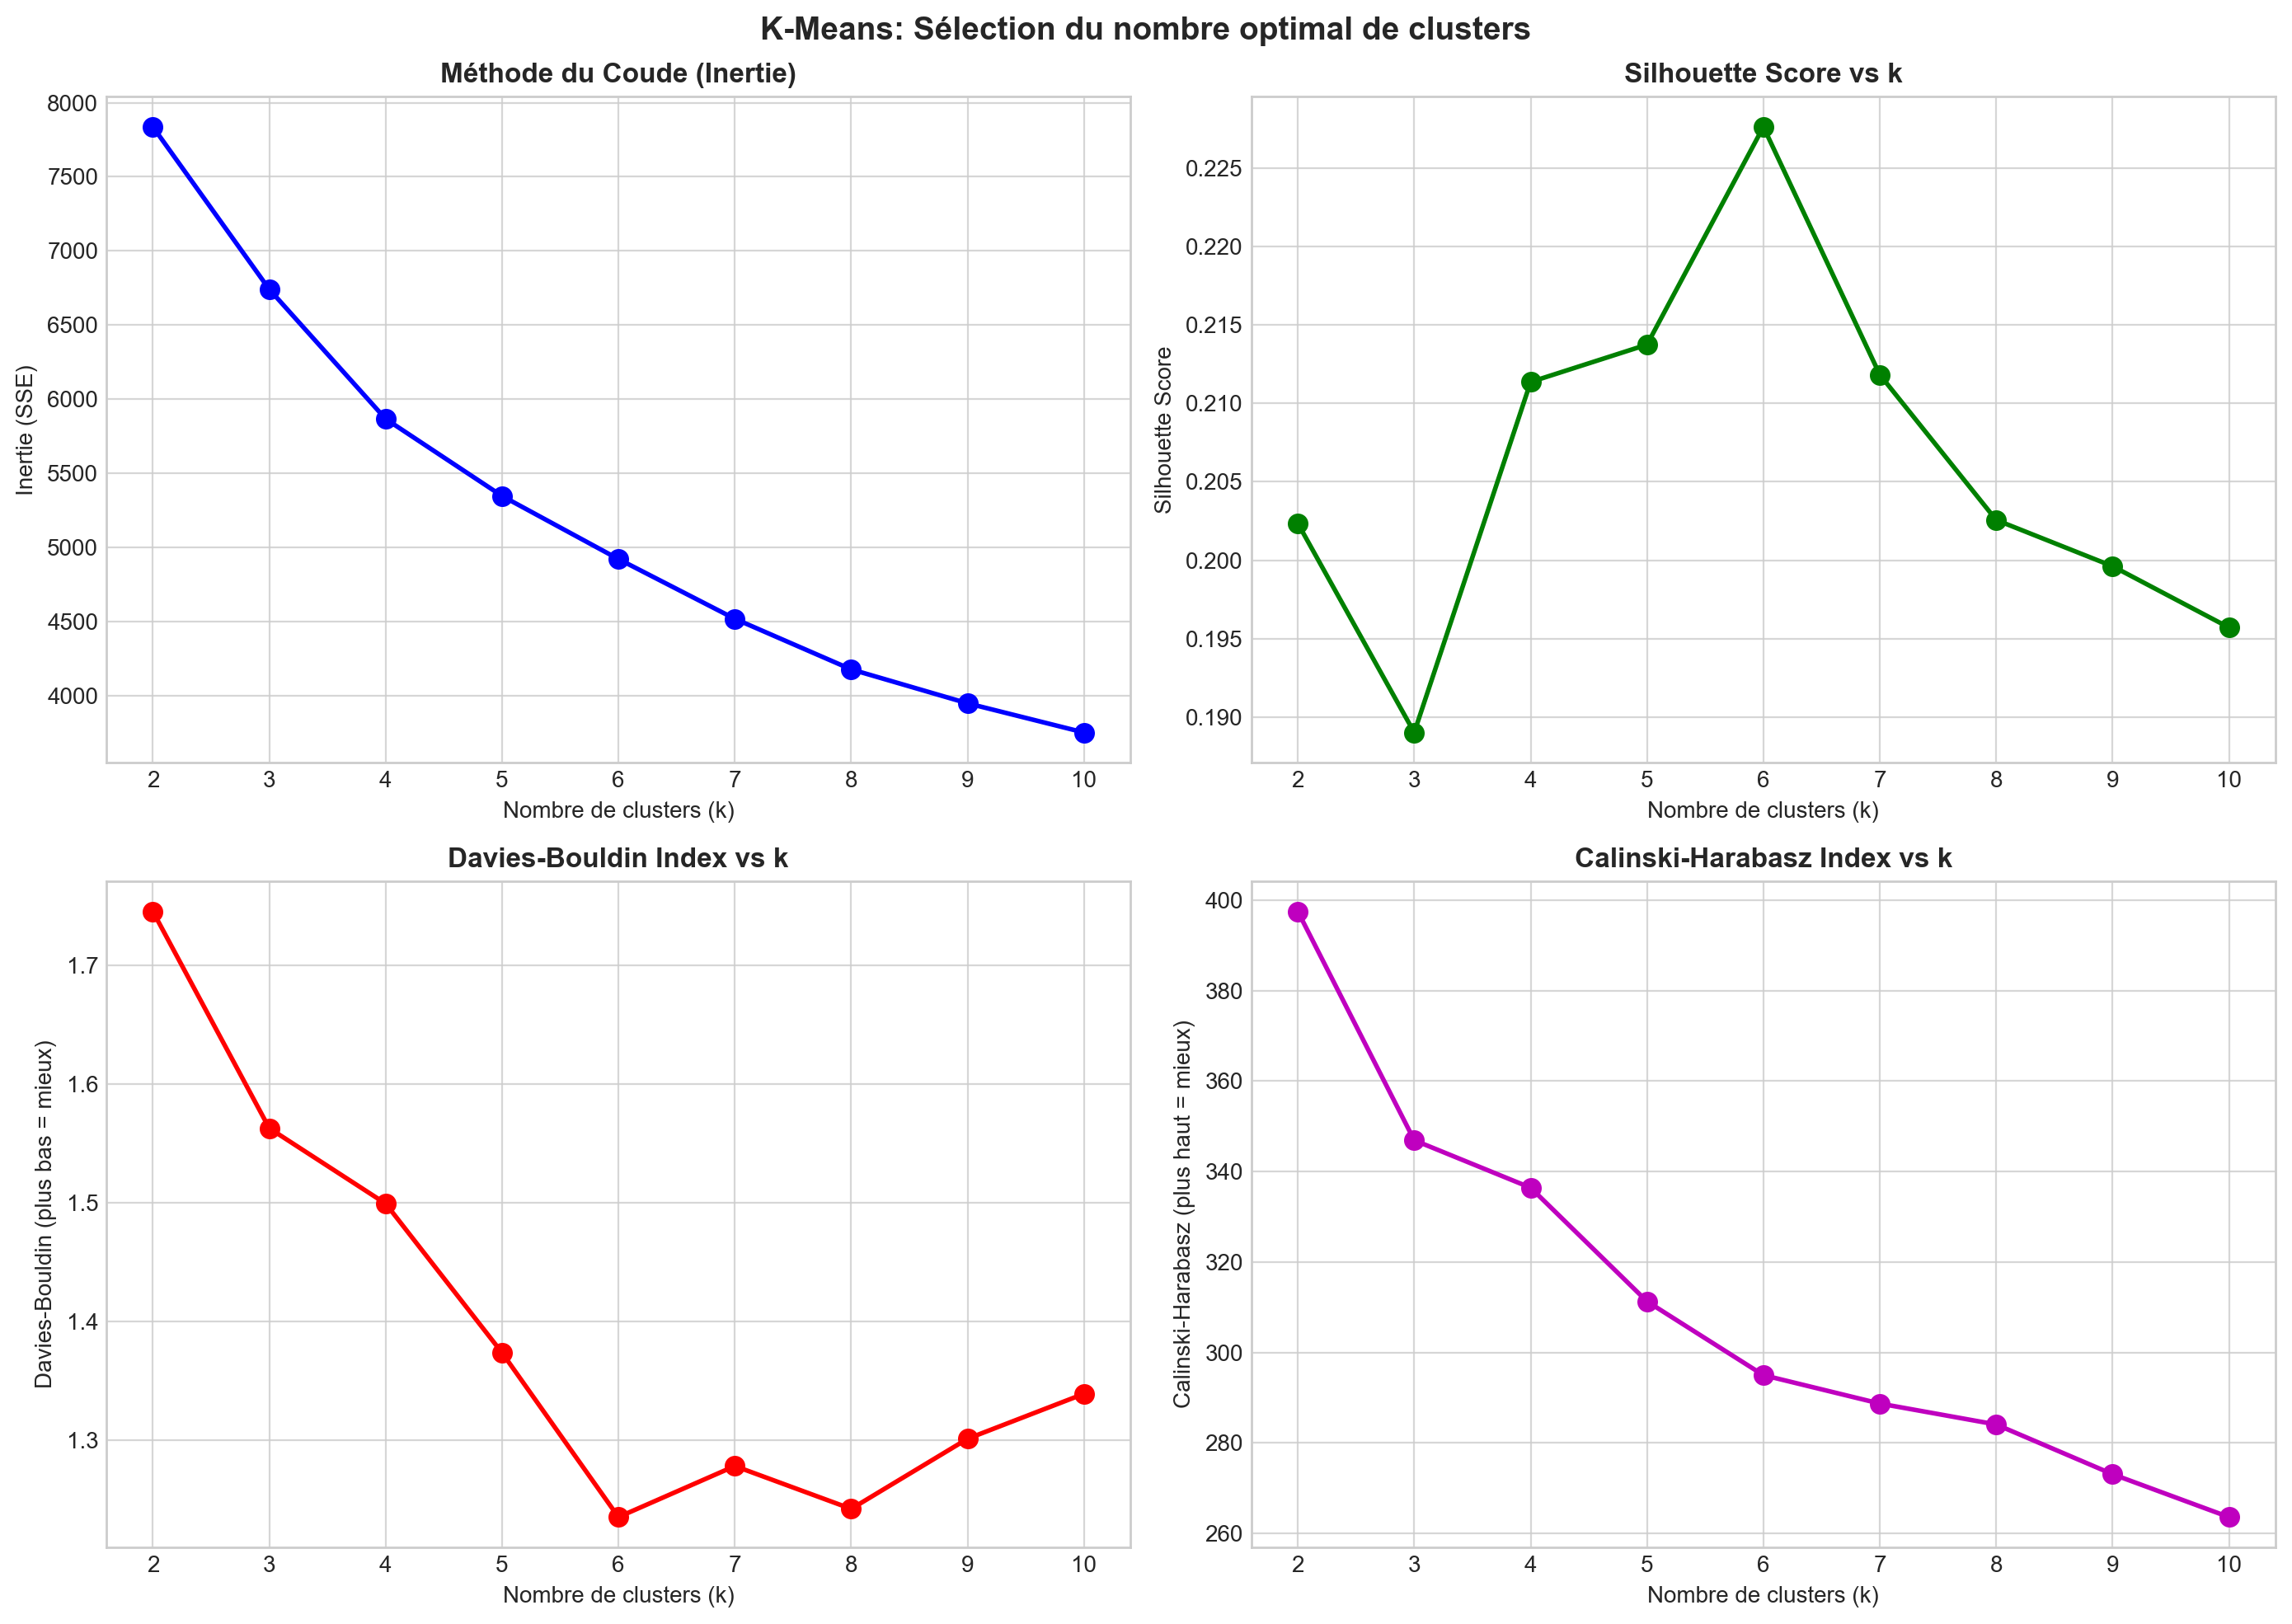


MEILLEUR K POUR K-MEANS: 6
Score global combiné: 0.7448

K-Means final entraîné avec k=6
Taille des clusters: [500 128 252 326  23 202]


In [11]:
print("=== CYCLE 1 - ALGORITHME 1: K-MEANS ===")

# Recherche du nombre optimal de clusters (méthode du coude + métriques)
k_range = range(2, 11)
kmeans_results = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(X)
    
    results = evaluate_clustering(X, labels, model_name=f"K-Means (k={k})")
    results['k'] = k
    results['inertia'] = kmeans.inertia_
    kmeans_results.append(results)

# Conversion en DataFrame pour analyse
kmeans_df = pd.DataFrame(kmeans_results)

# Visualisation: Méthode du coude + métriques
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Méthode du coude (Inertie)
axes[0, 0].plot(kmeans_df['k'], kmeans_df['inertia'], 'bo-', linewidth=2, markersize=8)
axes[0, 0].set_title('Méthode du Coude (Inertie)', fontweight='bold')
axes[0, 0].set_xlabel('Nombre de clusters (k)')
axes[0, 0].set_ylabel('Inertie (SSE)')
axes[0, 0].grid(True, alpha=0.8)

# Silhouette Score
axes[0, 1].plot(kmeans_df['k'], kmeans_df['silhouette'], 'go-', linewidth=2, markersize=8)
axes[0, 1].set_title('Silhouette Score vs k', fontweight='bold')
axes[0, 1].set_xlabel('Nombre de clusters (k)')
axes[0, 1].set_ylabel('Silhouette Score')
axes[0, 1].grid(True, alpha=0.8)

# Davies-Bouldin Index
axes[1, 0].plot(kmeans_df['k'], kmeans_df['davies_bouldin'], 'ro-', linewidth=2, markersize=8)
axes[1, 0].set_title('Davies-Bouldin Index vs k', fontweight='bold')
axes[1, 0].set_xlabel('Nombre de clusters (k)')
axes[1, 0].set_ylabel('Davies-Bouldin (plus bas = mieux)')
axes[1, 0].grid(True, alpha=0.8)

# Calinski-Harabasz Index
axes[1, 1].plot(kmeans_df['k'], kmeans_df['calinski_harabasz'], 'mo-', linewidth=2, markersize=8)
axes[1, 1].set_title('Calinski-Harabasz Index vs k', fontweight='bold')
axes[1, 1].set_xlabel('Nombre de clusters (k)')
axes[1, 1].set_ylabel('Calinski-Harabasz (plus haut = mieux)')
axes[1, 1].grid(True, alpha=0.8)

plt.suptitle('K-Means: Sélection du nombre optimal de clusters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '12_K-Means_nbre_clausters.png'), dpi=150, bbox_inches='tight')
plt.show()

# Sélection du meilleur k (combinaison des métriques)
# Normalisation des métriques pour comparaison
kmeans_df['sil_norm'] = (kmeans_df['silhouette'] - kmeans_df['silhouette'].min()) / (kmeans_df['silhouette'].max() - kmeans_df['silhouette'].min())
kmeans_df['db_norm'] = 1 - (kmeans_df['davies_bouldin'] - kmeans_df['davies_bouldin'].min()) / (kmeans_df['davies_bouldin'].max() - kmeans_df['davies_bouldin'].min())
kmeans_df['ch_norm'] = (kmeans_df['calinski_harabasz'] - kmeans_df['calinski_harabasz'].min()) / (kmeans_df['calinski_harabasz'].max() - kmeans_df['calinski_harabasz'].min())
kmeans_df['score_global'] = (kmeans_df['sil_norm'] + kmeans_df['db_norm'] + kmeans_df['ch_norm']) / 3

best_k_kmeans = kmeans_df.loc[kmeans_df['score_global'].idxmax(), 'k']
print(f"\n{'='*60}")
print(f"MEILLEUR K POUR K-MEANS: {int(best_k_kmeans)}")
print(f"Score global combiné: {kmeans_df['score_global'].max():.4f}")
print(f"{'='*60}")

# Entraînement final avec le meilleur k
kmeans_final = KMeans(n_clusters=int(best_k_kmeans), random_state=42, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X)
kmeans_centers = kmeans_final.cluster_centers_

print(f"\nK-Means final entraîné avec k={int(best_k_kmeans)}")
print(f"Taille des clusters: {np.bincount(kmeans_labels)}")

=== CYCLE 1 - ALGORITHME 2: K-MEDOIDS (PAM) ===

Test K-Medoids avec k=2...

Évaluation: K-Medoids (k=2)
  Silhouette Score:      0.2027
  Davies-Bouldin Index:  1.7522
  Calinski-Harabasz:     388.40
  Nombre de clusters:    2

Test K-Medoids avec k=3...

Évaluation: K-Medoids (k=3)
  Silhouette Score:      0.2052
  Davies-Bouldin Index:  1.6290
  Calinski-Harabasz:     331.91
  Nombre de clusters:    3

Test K-Medoids avec k=4...

Évaluation: K-Medoids (k=4)
  Silhouette Score:      0.1830
  Davies-Bouldin Index:  1.5666
  Calinski-Harabasz:     302.62
  Nombre de clusters:    4

Test K-Medoids avec k=5...

Évaluation: K-Medoids (k=5)
  Silhouette Score:      0.1576
  Davies-Bouldin Index:  1.5682
  Calinski-Harabasz:     292.08
  Nombre de clusters:    5

Test K-Medoids avec k=6...

Évaluation: K-Medoids (k=6)
  Silhouette Score:      0.1733
  Davies-Bouldin Index:  1.5382
  Calinski-Harabasz:     274.19
  Nombre de clusters:    6

Test K-Medoids avec k=7...

Évaluation: K-Medoids (

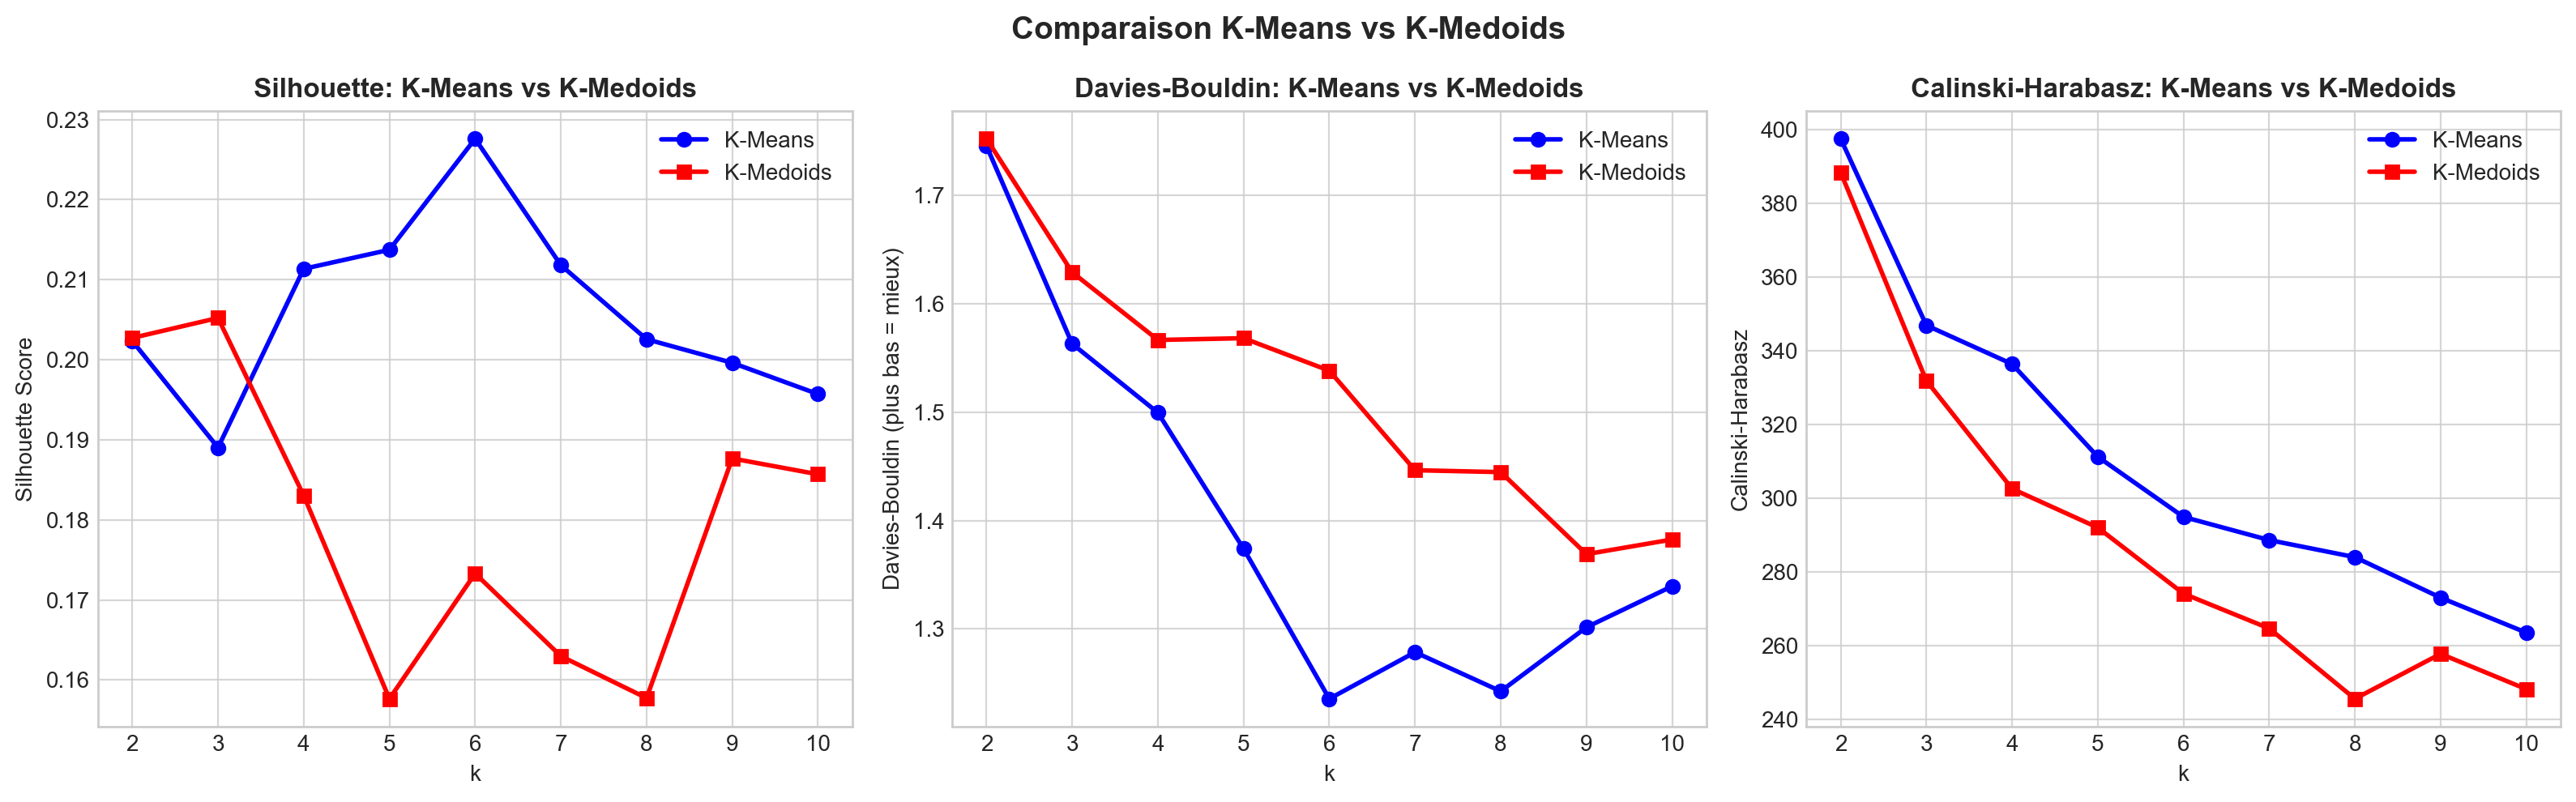


MEILLEUR K POUR K-MEDOIDS: 2
Score global combiné: 0.6492

K-Medoids final entraîné avec k=2
Taille des clusters: [617 814]


In [12]:
print("=== CYCLE 1 - ALGORITHME 2: K-MEDOIDS (PAM) ===")

# Test avec le même range de k que K-Means
kmedoids_results = []

for k in k_range:
    print(f"\nTest K-Medoids avec k={k}...")
    kmedoids = KMedoids(n_clusters=k, random_state=42, max_iter=100, metric='euclidean')
    labels = kmedoids.fit_predict(X)
    
    results = evaluate_clustering(X, labels, model_name=f"K-Medoids (k={k})")
    results['k'] = k
    results['inertia'] = kmedoids.inertia_
    kmedoids_results.append(results)

# Conversion en DataFrame
kmedoids_df = pd.DataFrame(kmedoids_results)

# Visualisation comparative K-Means vs K-Medoids
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Silhouette comparison
axes[0].plot(kmeans_df['k'], kmeans_df['silhouette'], 'b-o', label='K-Means', linewidth=2)
axes[0].plot(kmedoids_df['k'], kmedoids_df['silhouette'], 'r-s', label='K-Medoids', linewidth=2)
axes[0].set_title('Silhouette: K-Means vs K-Medoids', fontweight='bold')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Silhouette Score')
axes[0].legend()
axes[0].grid(True, alpha=0.8)

# Davies-Bouldin comparison
axes[1].plot(kmeans_df['k'], kmeans_df['davies_bouldin'], 'b-o', label='K-Means', linewidth=2)
axes[1].plot(kmedoids_df['k'], kmedoids_df['davies_bouldin'], 'r-s', label='K-Medoids', linewidth=2)
axes[1].set_title('Davies-Bouldin: K-Means vs K-Medoids', fontweight='bold')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Davies-Bouldin (plus bas = mieux)')
axes[1].legend()
axes[1].grid(True, alpha=0.8)

# Calinski-Harabasz comparison
axes[2].plot(kmeans_df['k'], kmeans_df['calinski_harabasz'], 'b-o', label='K-Means', linewidth=2)
axes[2].plot(kmedoids_df['k'], kmedoids_df['calinski_harabasz'], 'r-s', label='K-Medoids', linewidth=2)
axes[2].set_title('Calinski-Harabasz: K-Means vs K-Medoids', fontweight='bold')
axes[2].set_xlabel('k')
axes[2].set_ylabel('Calinski-Harabasz')
axes[2].legend()
axes[2].grid(True, alpha=0.8)

plt.suptitle('Comparaison K-Means vs K-Medoids', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '13_Comparaison_K-Means_vs_K-Medoids.png'), dpi=150, bbox_inches='tight')
plt.show()

# Sélection du meilleur k pour K-Medoids
kmedoids_df['sil_norm'] = (kmedoids_df['silhouette'] - kmedoids_df['silhouette'].min()) / (kmedoids_df['silhouette'].max() - kmedoids_df['silhouette'].min())
kmedoids_df['db_norm'] = 1 - (kmedoids_df['davies_bouldin'] - kmedoids_df['davies_bouldin'].min()) / (kmedoids_df['davies_bouldin'].max() - kmedoids_df['davies_bouldin'].min())
kmedoids_df['ch_norm'] = (kmedoids_df['calinski_harabasz'] - kmedoids_df['calinski_harabasz'].min()) / (kmedoids_df['calinski_harabasz'].max() - kmedoids_df['calinski_harabasz'].min())
kmedoids_df['score_global'] = (kmedoids_df['sil_norm'] + kmedoids_df['db_norm'] + kmedoids_df['ch_norm']) / 3

best_k_kmedoids = kmedoids_df.loc[kmedoids_df['score_global'].idxmax(), 'k']
print(f"\n{'='*60}")
print(f"MEILLEUR K POUR K-MEDOIDS: {int(best_k_kmedoids)}")
print(f"Score global combiné: {kmedoids_df['score_global'].max():.4f}")
print(f"{'='*60}")

# Entraînement final
kmedoids_final = KMedoids(n_clusters=int(best_k_kmedoids), random_state=42, max_iter=100)
kmedoids_labels = kmedoids_final.fit_predict(X)
kmedoids_medoids = kmedoids_final.medoids_

print(f"\nK-Medoids final entraîné avec k={int(best_k_kmedoids)}")
print(f"Taille des clusters: {np.bincount(kmedoids_labels)}")

## CYCLE 1 - ALGORITHME 3: HIERARCHICAL CLUSTERING
Troisième algorithme du cycle 1: Clustering Hiérarchique Agglomératif (HAC).
Permet de visualiser la structure hiérarchique des données via un dendrogramme.


=== CYCLE 1 - ALGORITHME 3: HIERARCHICAL CLUSTERING ===

Calcul du dendrogramme sur un échantillon de 500 points...


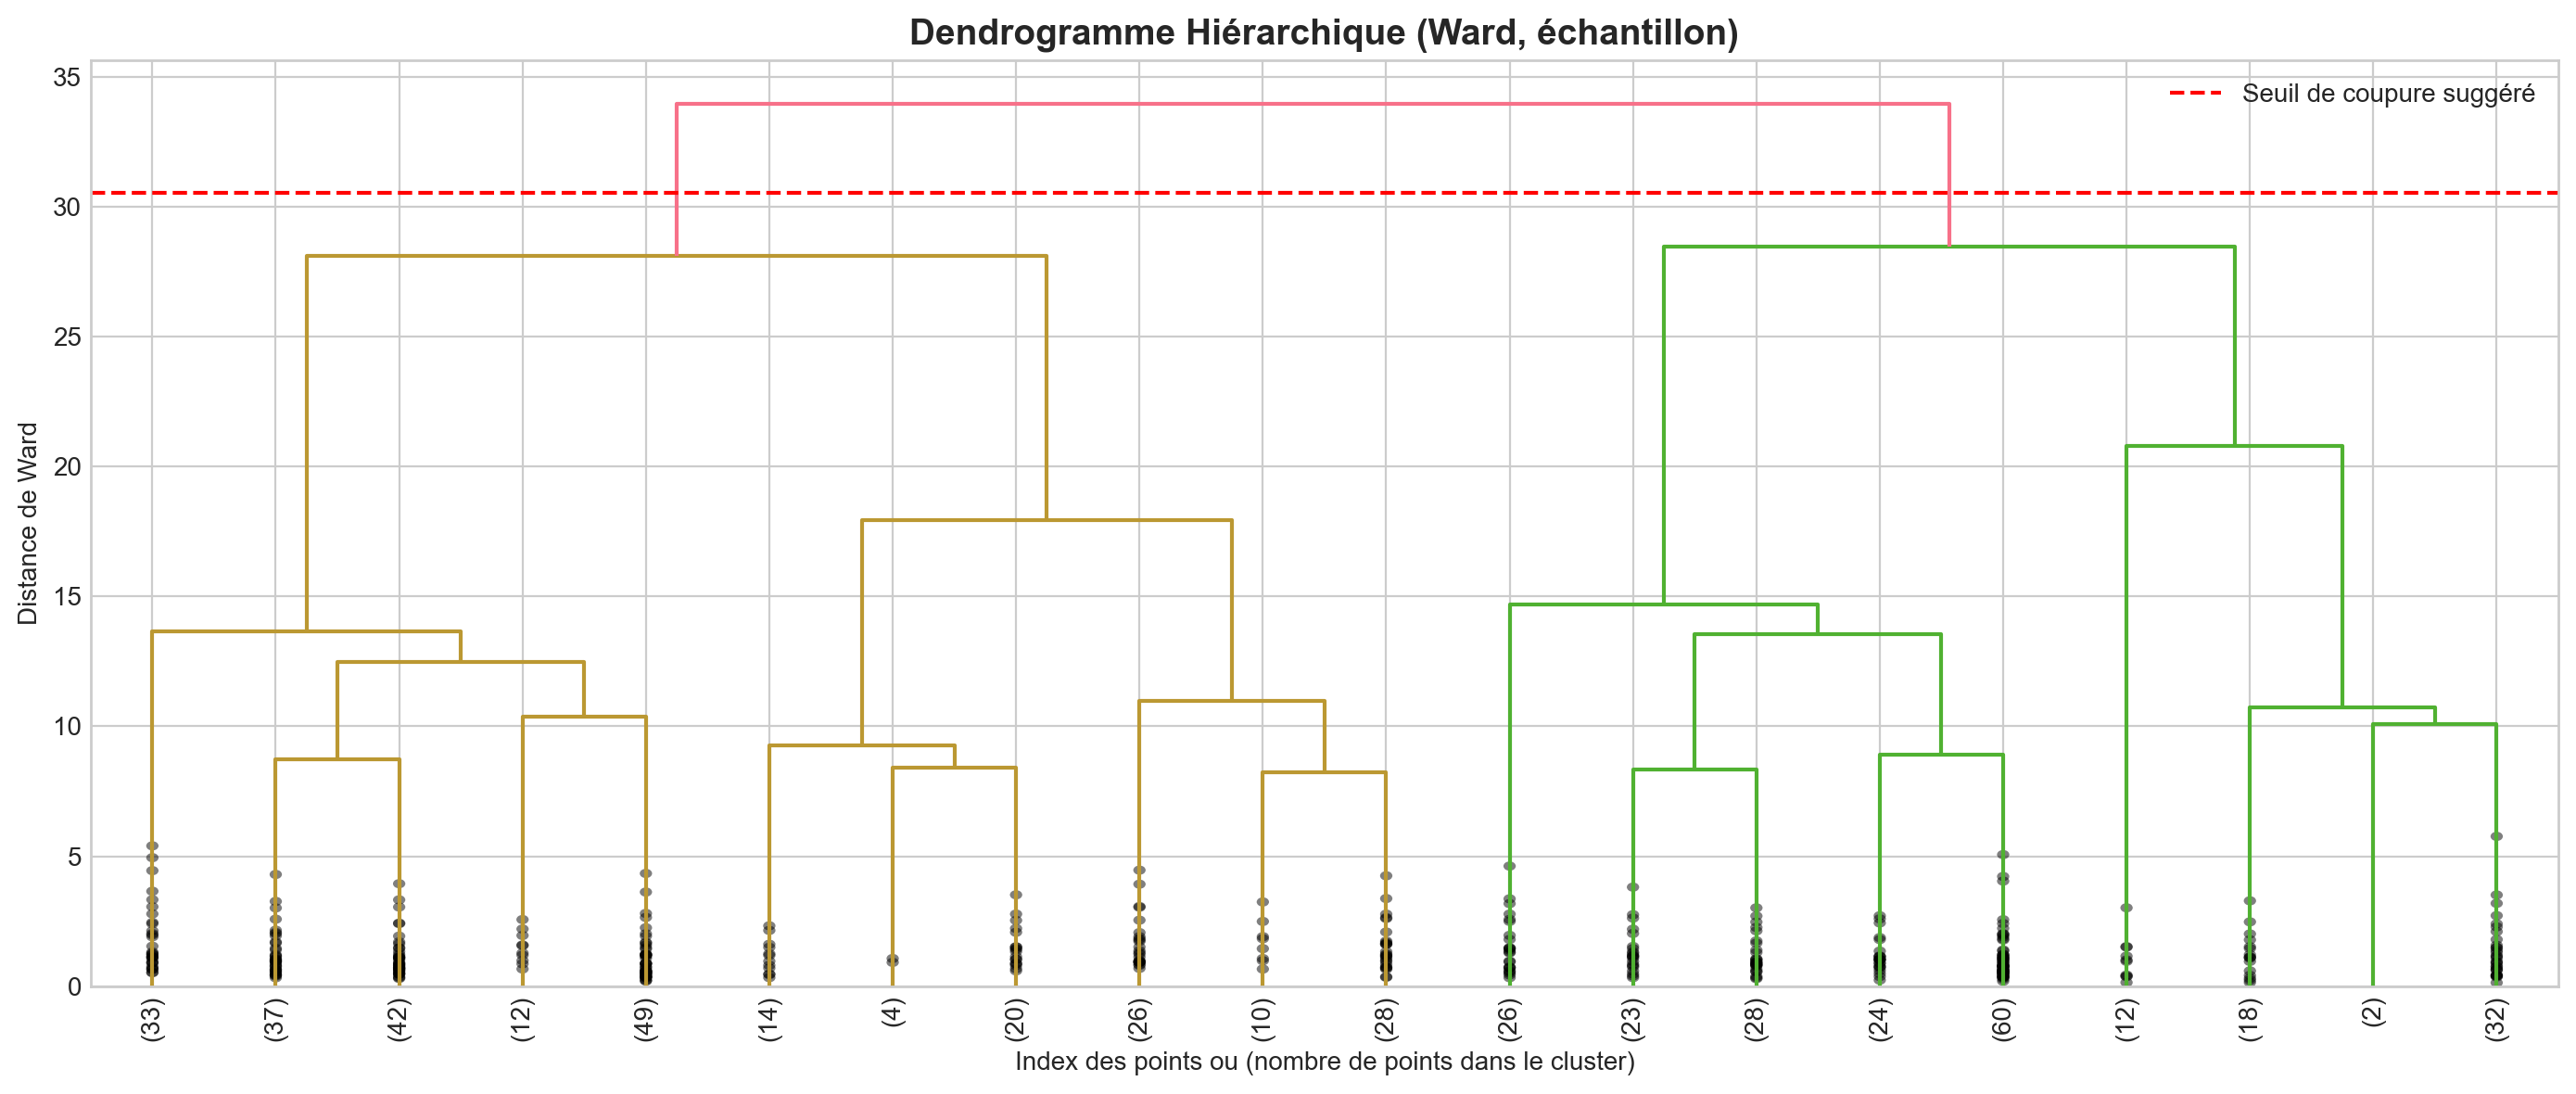


Évaluation: HAC-Ward (k=2)
  Silhouette Score:      0.1740
  Davies-Bouldin Index:  1.8564
  Calinski-Harabasz:     331.67
  Nombre de clusters:    2

Évaluation: HAC-Ward (k=3)
  Silhouette Score:      0.1729
  Davies-Bouldin Index:  1.7692
  Calinski-Harabasz:     292.95
  Nombre de clusters:    3

Évaluation: HAC-Ward (k=4)
  Silhouette Score:      0.1682
  Davies-Bouldin Index:  1.7362
  Calinski-Harabasz:     262.48
  Nombre de clusters:    4

Évaluation: HAC-Ward (k=5)
  Silhouette Score:      0.1735
  Davies-Bouldin Index:  1.6504
  Calinski-Harabasz:     245.67
  Nombre de clusters:    5

Évaluation: HAC-Ward (k=6)
  Silhouette Score:      0.1852
  Davies-Bouldin Index:  1.4339
  Calinski-Harabasz:     237.75
  Nombre de clusters:    6

Évaluation: HAC-Ward (k=7)
  Silhouette Score:      0.1760
  Davies-Bouldin Index:  1.4540
  Calinski-Harabasz:     236.29
  Nombre de clusters:    7

Évaluation: HAC-Ward (k=8)
  Silhouette Score:      0.1583
  Davies-Bouldin Index:  1.4326
  

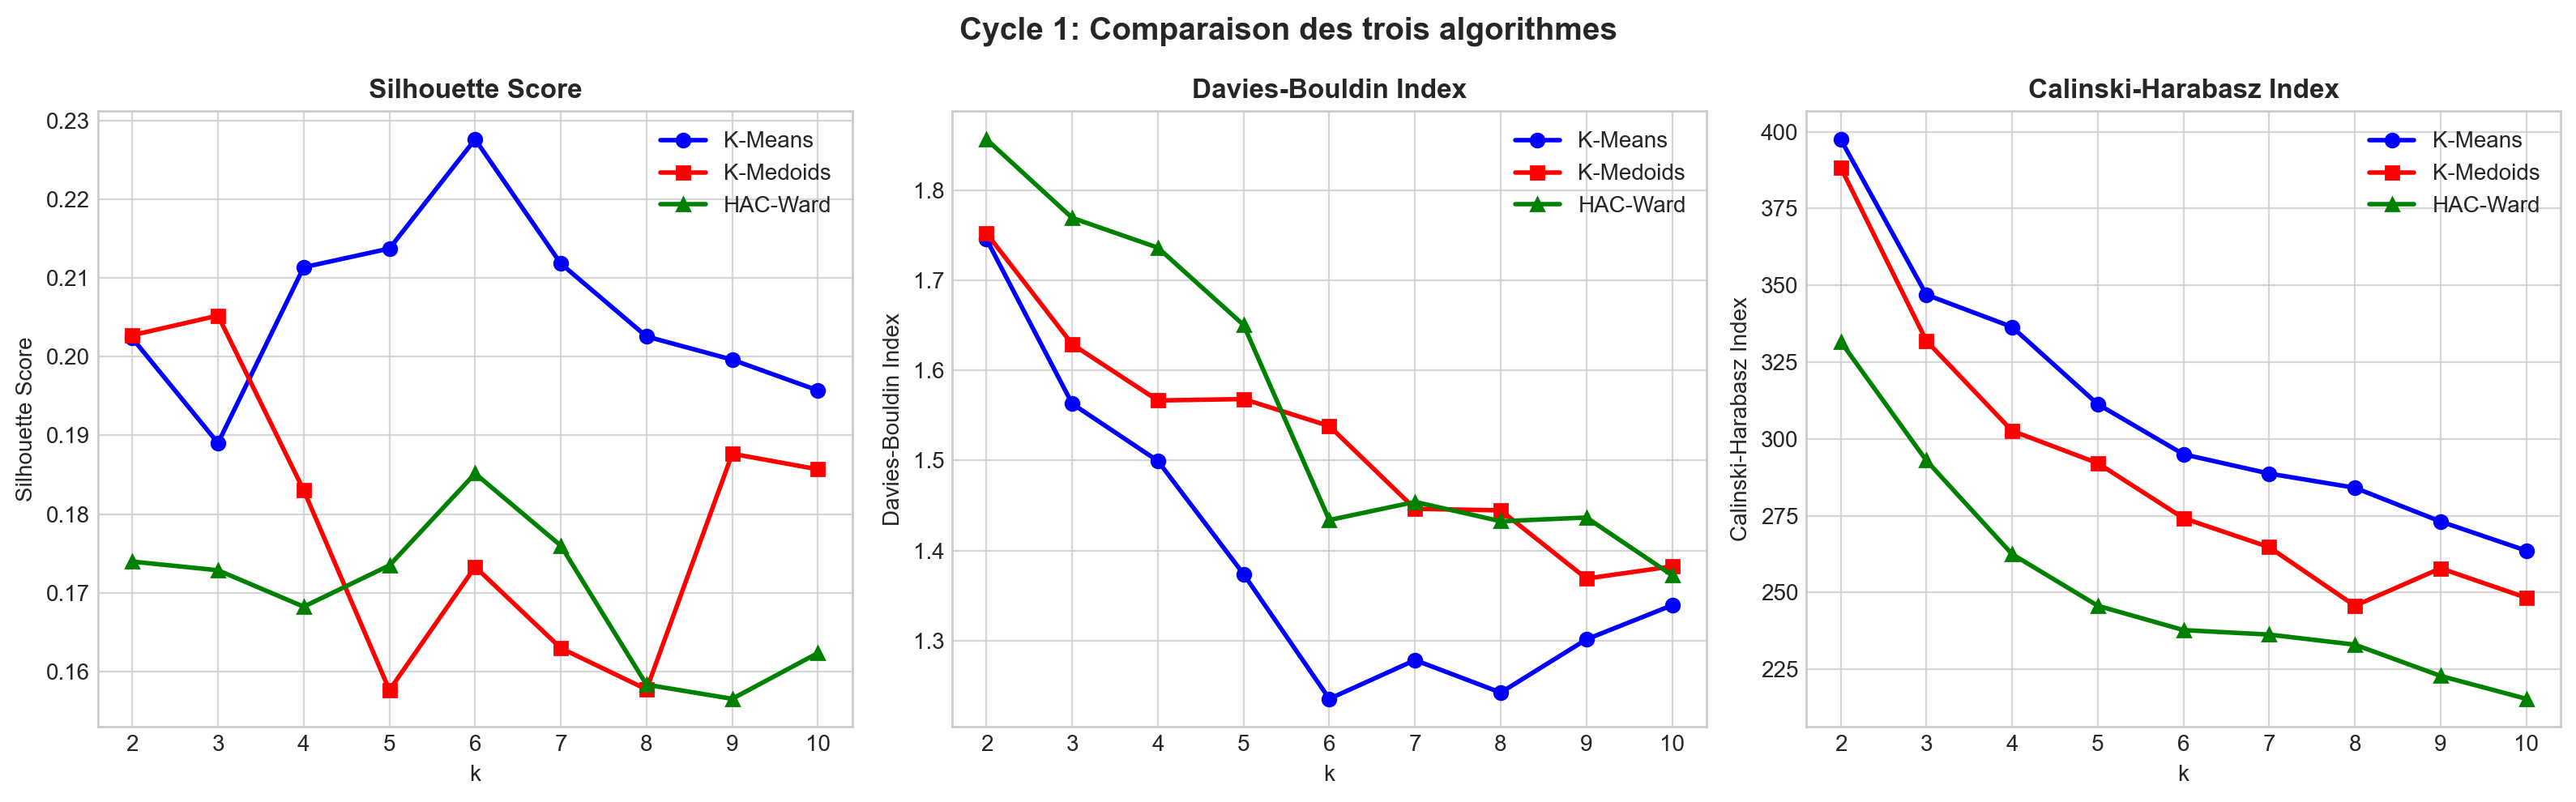


MEILLEUR K POUR HAC-WARD: 6
Score global combiné: 0.6885

HAC-Ward final entraîné avec k=6
Taille des clusters: [496 434 130 172 177  22]


In [13]:
print("=== CYCLE 1 - ALGORITHME 3: HIERARCHICAL CLUSTERING ===")

# Dendrogramme pour visualiser la structure hiérarchique
# On utilise un échantillon pour la visualisation (sinon trop lent)
sample_size = min(500, X.shape[0])
np.random.seed(42)
sample_idx = np.random.choice(X.shape[0], sample_size, replace=False)
X_sample = X[sample_idx]

print(f"\nCalcul du dendrogramme sur un échantillon de {sample_size} points...")

# Calcul de la matrice de linkage
linkage_matrix = linkage(X_sample, method='ward', metric='euclidean')

# Affichage du dendrogramme
plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, truncate_mode='lastp', p=20, 
           leaf_rotation=90, leaf_font_size=10,
           show_contracted=True,  # Affiche les points contractés
           color_threshold=0.9 * max(linkage_matrix[:, 2]))
plt.title('Dendrogramme Hiérarchique (Ward, échantillon)', fontsize=14, fontweight='bold')
plt.xlabel('Index des points ou (nombre de points dans le cluster)')
plt.ylabel('Distance de Ward')
plt.axhline(y=0.9    * max(linkage_matrix[:, 2]), color='r', linestyle='--', 
            label='Seuil de coupure suggéré')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '13_Dendrogramme_Hiérarchique.png'), dpi=150, bbox_inches='tight')
plt.show()

# Test HAC avec différents k
hac_results = []

for k in k_range:
    hac = AgglomerativeClustering(n_clusters=k, linkage='ward', metric='euclidean')
    labels = hac.fit_predict(X)
    
    results = evaluate_clustering(X, labels, model_name=f"HAC-Ward (k={k})")
    results['k'] = k
    hac_results.append(results)

hac_df = pd.DataFrame(hac_results)

# Visualisation des trois algorithmes du Cycle 1
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['silhouette', 'davies_bouldin', 'calinski_harabasz']
titles = ['Silhouette Score', 'Davies-Bouldin Index', 'Calinski-Harabasz Index']
colors = ['b', 'r', 'g']
markers = ['o', 's', '^']

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    axes[idx].plot(kmeans_df['k'], kmeans_df[metric], 'b-o', label='K-Means', linewidth=2)
    axes[idx].plot(kmedoids_df['k'], kmedoids_df[metric], 'r-s', label='K-Medoids', linewidth=2)
    axes[idx].plot(hac_df['k'], hac_df[metric], 'g-^', label='HAC-Ward', linewidth=2)
    axes[idx].set_title(title, fontweight='bold')
    axes[idx].set_xlabel('k')
    axes[idx].set_ylabel(title)
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.8)

plt.suptitle('Cycle 1: Comparaison des trois algorithmes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '14_Comparaison_des_trois_algorithmes.png'), dpi=150, bbox_inches='tight')
plt.show()

# Sélection du meilleur k pour HAC
hac_df['sil_norm'] = (hac_df['silhouette'] - hac_df['silhouette'].min()) / (hac_df['silhouette'].max() - hac_df['silhouette'].min())
hac_df['db_norm'] = 1 - (hac_df['davies_bouldin'] - hac_df['davies_bouldin'].min()) / (hac_df['davies_bouldin'].max() - hac_df['davies_bouldin'].min())
hac_df['ch_norm'] = (hac_df['calinski_harabasz'] - hac_df['calinski_harabasz'].min()) / (hac_df['calinski_harabasz'].max() - hac_df['calinski_harabasz'].min())
hac_df['score_global'] = (hac_df['sil_norm'] + hac_df['db_norm'] + hac_df['ch_norm']) / 3

best_k_hac = hac_df.loc[hac_df['score_global'].idxmax(), 'k']
print(f"\n{'='*60}")
print(f"MEILLEUR K POUR HAC-WARD: {int(best_k_hac)}")
print(f"Score global combiné: {hac_df['score_global'].max():.4f}")
print(f"{'='*60}")

# Entraînement final
hac_final = AgglomerativeClustering(n_clusters=int(best_k_hac), linkage='ward')
hac_labels = hac_final.fit_predict(X)

print(f"\nHAC-Ward final entraîné avec k={int(best_k_hac)}")
print(f"Taille des clusters: {np.bincount(hac_labels)}")

## ÉVALUATION ET SÉLECTION PRÉLIMINAIRE - CYCLE 1
Comparaison finale des trois algorithmes du cycle 1 et sélection des
meilleurs candidats pour le cycle 2.


In [14]:
print("=== RÉSULTATS DU CYCLE 1 - TABLEAU RÉCAPITULATIF ===")

# Création du tableau comparatif
cycle1_summary = pd.DataFrame({
    'Algorithme': ['K-Means', 'K-Medoids', 'HAC-Ward'],
    'Meilleur_k': [best_k_kmeans, best_k_kmedoids, best_k_hac],
    'Silhouette': [
        kmeans_df[kmeans_df['k'] == best_k_kmeans]['silhouette'].values[0],
        kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['silhouette'].values[0],
        hac_df[hac_df['k'] == best_k_hac]['silhouette'].values[0]
    ],
    'Davies_Bouldin': [
        kmeans_df[kmeans_df['k'] == best_k_kmeans]['davies_bouldin'].values[0],
        kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['davies_bouldin'].values[0],
        hac_df[hac_df['k'] == best_k_hac]['davies_bouldin'].values[0]
    ],
    'Calinski_Harabasz': [
        kmeans_df[kmeans_df['k'] == best_k_kmeans]['calinski_harabasz'].values[0],
        kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['calinski_harabasz'].values[0],
        hac_df[hac_df['k'] == best_k_hac]['calinski_harabasz'].values[0]
    ],
    'Score_Global': [
        kmeans_df[kmeans_df['k'] == best_k_kmeans]['score_global'].values[0],
        kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['score_global'].values[0],
        hac_df[hac_df['k'] == best_k_hac]['score_global'].values[0]
    ]
})

print(cycle1_summary.to_string(index=False, float_format='%.4f'))

# Classement
cycle1_summary_sorted = cycle1_summary.sort_values('Score_Global', ascending=False)
print(f"\n{'='*60}")
print("CLASSEMENT DU CYCLE 1 (par score global combiné):")
print(f"{'='*60}")
for i, row in cycle1_summary_sorted.iterrows():
    print(f"  {i+1}. {row['Algorithme']} (k={int(row['Meilleur_k'])}) - Score: {row['Score_Global']:.4f}")

# Analyse de stabilité: comparaison des labels entre algorithmes
print(f"\n{'='*60}")
print("ANALYSE DE STABILITÉ ENTRE ALGORITHMES (ARI)")
print(f"{'='*60}")

from sklearn.metrics import adjusted_rand_score

ari_kmeans_kmedoids = adjusted_rand_score(kmeans_labels, kmedoids_labels)
ari_kmeans_hac = adjusted_rand_score(kmeans_labels, hac_labels)
ari_kmedoids_hac = adjusted_rand_score(kmedoids_labels, hac_labels)

print(f"  ARI(K-Means, K-Medoids):  {ari_kmeans_kmedoids:.4f}")
print(f"  ARI(K-Means, HAC):        {ari_kmeans_hac:.4f}")
print(f"  ARI(K-Medoids, HAC):      {ari_kmedoids_hac:.4f}")
print(f"\n(ARI proche de 1 = forte similarité, proche de 0 = indépendance)")

# Sélection du meilleur modèle du cycle 1 pour comparaison avec cycle 2
best_cycle1_model = cycle1_summary_sorted.iloc[0]['Algorithme']
best_cycle1_k = int(cycle1_summary_sorted.iloc[0]['Meilleur_k'])

if best_cycle1_model == 'K-Means':
    best_cycle1_labels = kmeans_labels
elif best_cycle1_model == 'K-Medoids':
    best_cycle1_labels = kmedoids_labels
else:
    best_cycle1_labels = hac_labels

print(f"\n{'='*60}")
print(f"MEILLEUR MODÈLE CYCLE 1: {best_cycle1_model} (k={best_cycle1_k})")
print(f"{'='*60}")

=== RÉSULTATS DU CYCLE 1 - TABLEAU RÉCAPITULATIF ===
Algorithme  Meilleur_k  Silhouette  Davies_Bouldin  Calinski_Harabasz  Score_Global
   K-Means           6      0.2276          1.2355           294.9861        0.7448
 K-Medoids           2      0.2027          1.7522           388.3963        0.6492
  HAC-Ward           6      0.1852          1.4339           237.7510        0.6885

CLASSEMENT DU CYCLE 1 (par score global combiné):
  1. K-Means (k=6) - Score: 0.7448
  3. HAC-Ward (k=6) - Score: 0.6885
  2. K-Medoids (k=2) - Score: 0.6492

ANALYSE DE STABILITÉ ENTRE ALGORITHMES (ARI)
  ARI(K-Means, K-Medoids):  0.2915
  ARI(K-Means, HAC):        0.5083
  ARI(K-Medoids, HAC):      0.3056

(ARI proche de 1 = forte similarité, proche de 0 = indépendance)

MEILLEUR MODÈLE CYCLE 1: K-Means (k=6)


## CYCLE 2 - ALGORITHME 1: GAUSSIAN MIXTURE MODEL (GMM)

Premier algorithme du cycle 2: GMM (modèle probabiliste).
Avantage: fournit des probabilités d'appartenance aux clusters (soft clustering).


=== CYCLE 2 - ALGORITHME 1: GAUSSIAN MIXTURE MODEL (GMM) ===

Évaluation: GMM (k=2, cov=full)
  Silhouette Score:      0.1681
  Davies-Bouldin Index:  2.6647
  Calinski-Harabasz:     164.65
  Nombre de clusters:    2

Évaluation: GMM (k=2, cov=tied)
  Silhouette Score:      0.1976
  Davies-Bouldin Index:  1.7671
  Calinski-Harabasz:     319.62
  Nombre de clusters:    2

Évaluation: GMM (k=2, cov=diag)
  Silhouette Score:      0.2004
  Davies-Bouldin Index:  1.7515
  Calinski-Harabasz:     390.18
  Nombre de clusters:    2

Évaluation: GMM (k=2, cov=spherical)
  Silhouette Score:      0.2007
  Davies-Bouldin Index:  1.7517
  Calinski-Harabasz:     393.77
  Nombre de clusters:    2

Évaluation: GMM (k=3, cov=full)
  Silhouette Score:      0.2422
  Davies-Bouldin Index:  1.4836
  Calinski-Harabasz:     192.43
  Nombre de clusters:    3

Évaluation: GMM (k=3, cov=tied)
  Silhouette Score:      0.1747
  Davies-Bouldin Index:  1.6584
  Calinski-Harabasz:     210.28
  Nombre de clusters:    

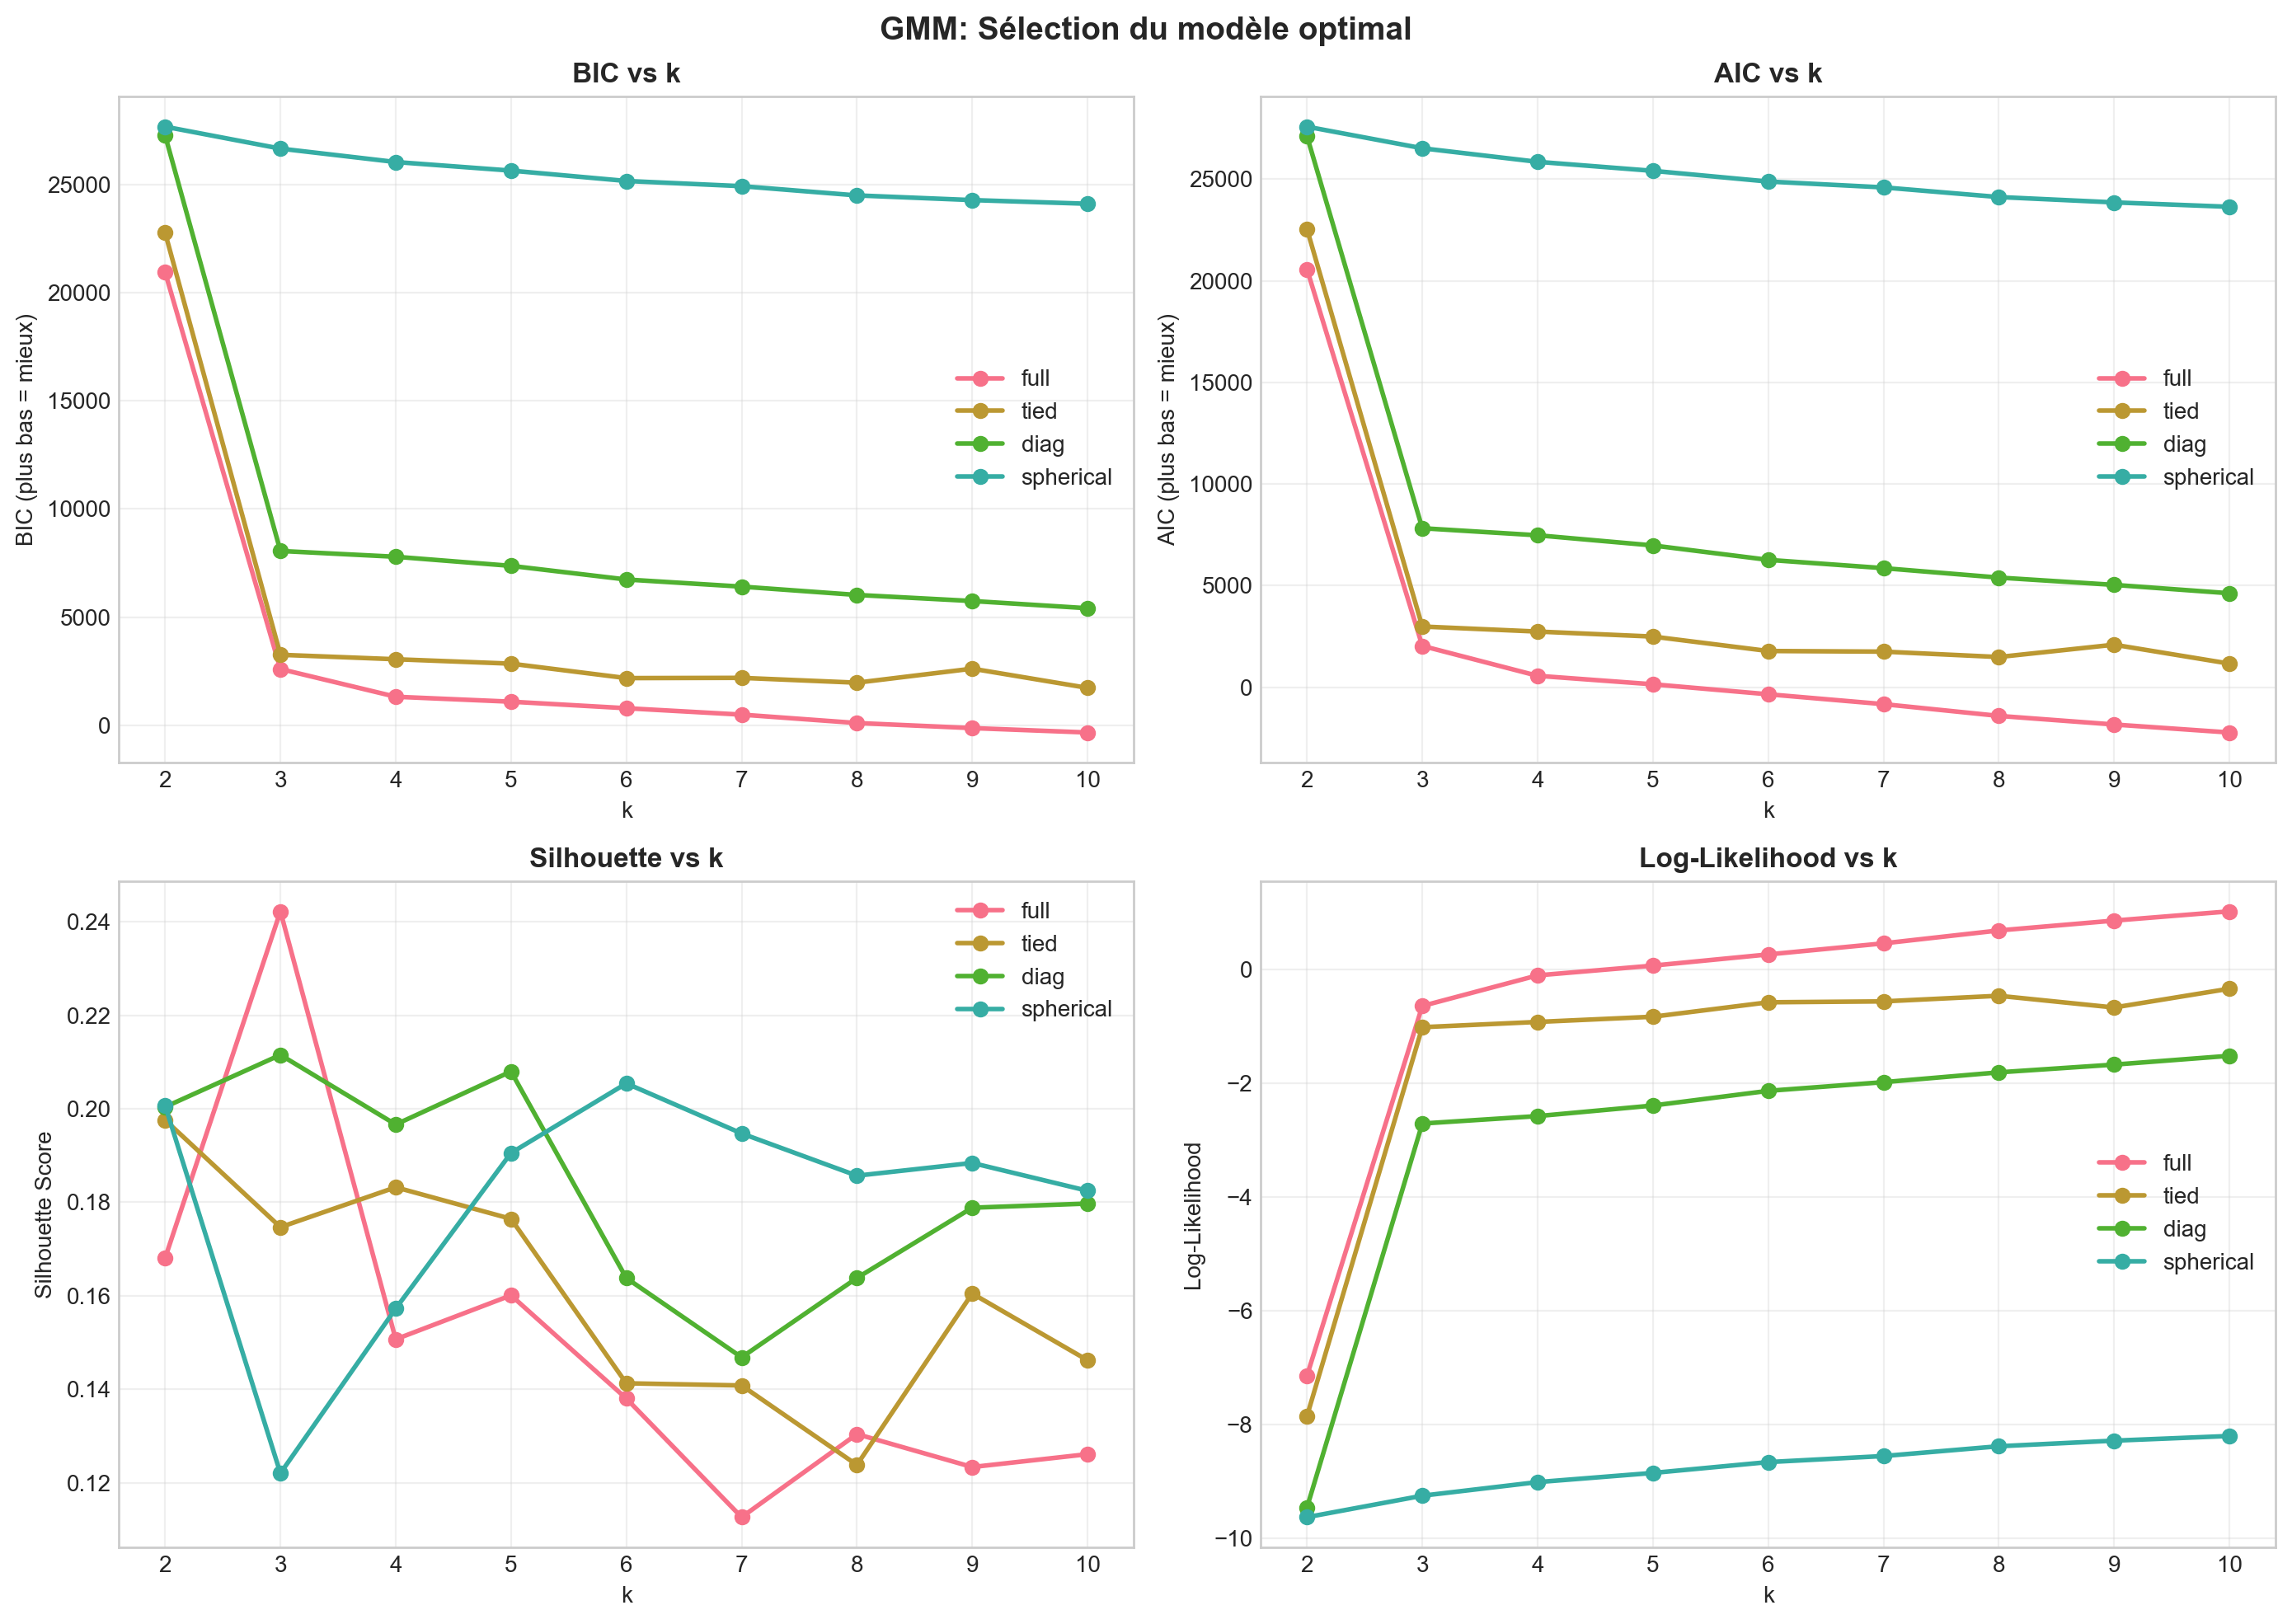


MEILLEUR GMM: k=3, covariance='full'
Score global combiné: 0.9476

GMM final entraîné
Taille des clusters: [  22  402 1007]
Probabilité moyenne d'appartenance: 1.0000


In [15]:
print("=== CYCLE 2 - ALGORITHME 1: GAUSSIAN MIXTURE MODEL (GMM) ===")

# Test GMM avec différents k et types de covariance
covariance_types = ['full', 'tied', 'diag', 'spherical']
gmm_results = []

for k in k_range:
    for cov_type in covariance_types:
        gmm = GaussianMixture(n_components=k, covariance_type=cov_type, 
                              random_state=42, max_iter=200, n_init=5)
        gmm.fit(X)
        labels = gmm.predict(X)
        
        # Calcul du BIC et AIC
        bic = gmm.bic(X)
        aic = gmm.aic(X)
        
        results = evaluate_clustering(X, labels, 
                                      model_name=f"GMM (k={k}, cov={cov_type})")
        results['k'] = k
        results['covariance_type'] = cov_type
        results['bic'] = bic
        results['aic'] = aic
        results['log_likelihood'] = gmm.lower_bound_
        gmm_results.append(results)

gmm_df = pd.DataFrame(gmm_results)

# Visualisation BIC/AIC pour sélection du modèle
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# BIC
for cov_type in covariance_types:
    subset = gmm_df[gmm_df['covariance_type'] == cov_type]
    axes[0, 0].plot(subset['k'], subset['bic'], '-o', label=cov_type, linewidth=2)
axes[0, 0].set_title('BIC vs k', fontweight='bold')
axes[0, 0].set_xlabel('k')
axes[0, 0].set_ylabel('BIC (plus bas = mieux)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# AIC
for cov_type in covariance_types:
    subset = gmm_df[gmm_df['covariance_type'] == cov_type]
    axes[0, 1].plot(subset['k'], subset['aic'], '-o', label=cov_type, linewidth=2)
axes[0, 1].set_title('AIC vs k', fontweight='bold')
axes[0, 1].set_xlabel('k')
axes[0, 1].set_ylabel('AIC (plus bas = mieux)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Silhouette
for cov_type in covariance_types:
    subset = gmm_df[gmm_df['covariance_type'] == cov_type]
    axes[1, 0].plot(subset['k'], subset['silhouette'], '-o', label=cov_type, linewidth=2)
axes[1, 0].set_title('Silhouette vs k', fontweight='bold')
axes[1, 0].set_xlabel('k')
axes[1, 0].set_ylabel('Silhouette Score')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Log-likelihood
for cov_type in covariance_types:
    subset = gmm_df[gmm_df['covariance_type'] == cov_type]
    axes[1, 1].plot(subset['k'], subset['log_likelihood'], '-o', label=cov_type, linewidth=2)
axes[1, 1].set_title('Log-Likelihood vs k', fontweight='bold')
axes[1, 1].set_xlabel('k')
axes[1, 1].set_ylabel('Log-Likelihood')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('GMM: Sélection du modèle optimal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '15_GMM_Sélection_du_modèle_optimal.png'), dpi=300, bbox_inches='tight')
plt.show()

# Sélection du meilleur GMM (combinaison BIC + Silhouette)
gmm_df['bic_norm'] = 1 - (gmm_df['bic'] - gmm_df['bic'].min()) / (gmm_df['bic'].max() - gmm_df['bic'].min())
gmm_df['sil_norm'] = (gmm_df['silhouette'] - gmm_df['silhouette'].min()) / (gmm_df['silhouette'].max() - gmm_df['silhouette'].min())
gmm_df['score_global'] = (gmm_df['bic_norm'] + gmm_df['sil_norm']) / 2

best_gmm_idx = gmm_df['score_global'].idxmax()
best_gmm_k = int(gmm_df.loc[best_gmm_idx, 'k'])
best_gmm_cov = gmm_df.loc[best_gmm_idx, 'covariance_type']

print(f"\n{'='*60}")
print(f"MEILLEUR GMM: k={best_gmm_k}, covariance='{best_gmm_cov}'")
print(f"Score global combiné: {gmm_df.loc[best_gmm_idx, 'score_global']:.4f}")
print(f"{'='*60}")

# Entraînement final
gmm_final = GaussianMixture(n_components=best_gmm_k, covariance_type=best_gmm_cov,
                            random_state=42, max_iter=200, n_init=10)
gmm_final.fit(X)
gmm_labels = gmm_final.predict(X)
gmm_probs = gmm_final.predict_proba(X)

print(f"\nGMM final entraîné")
print(f"Taille des clusters: {np.bincount(gmm_labels)}")
print(f"Probabilité moyenne d'appartenance: {np.mean(np.max(gmm_probs, axis=1)):.4f}")


## CYCLE 2 - ALGORITHME 2: DBSCAN

Deuxième algorithme du cycle 2: DBSCAN (Density-Based Spatial Clustering).
Avantage: découvre automatiquement le nombre de clusters et identifie le bruit.
HDBSCAN n'est pas installé par défaut, on utilise DBSCAN avec recherche d'eps.

=== CYCLE 2 - ALGORITHME 2: DBSCAN ===


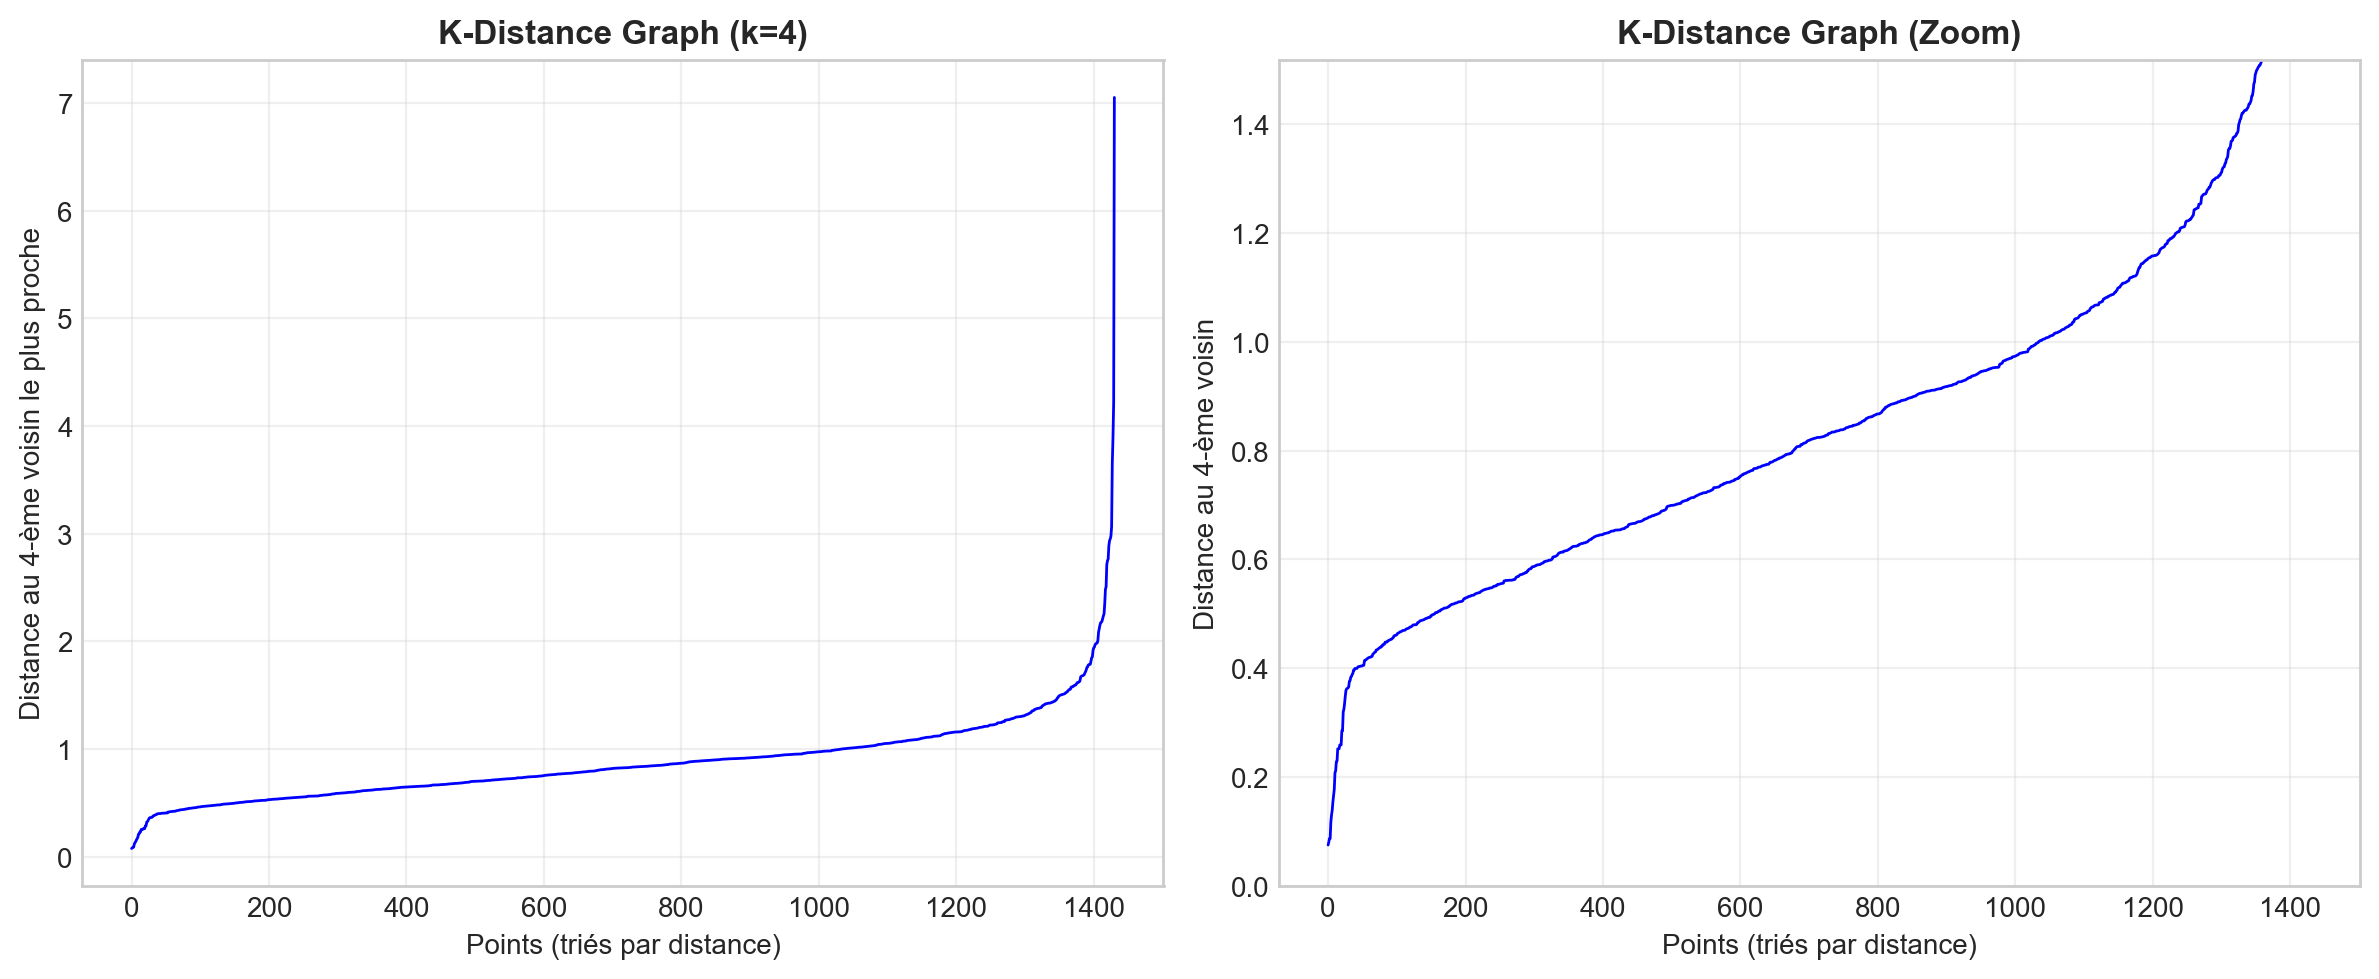


Évaluation: DBSCAN (eps=0.66, min_samples=3)
  Silhouette Score:      -0.0081
  Davies-Bouldin Index:  1.0291
  Calinski-Harabasz:     39.20
  Nombre de clusters:    48

Évaluation: DBSCAN (eps=0.79, min_samples=3)
  Silhouette Score:      0.0063
  Davies-Bouldin Index:  1.2445
  Calinski-Harabasz:     39.92
  Nombre de clusters:    33

Évaluation: DBSCAN (eps=0.79, min_samples=5)
  Silhouette Score:      -0.0413
  Davies-Bouldin Index:  1.6289
  Calinski-Harabasz:     59.72
  Nombre de clusters:    16

Évaluation: DBSCAN (eps=0.79, min_samples=7)
  Silhouette Score:      0.1053
  Davies-Bouldin Index:  1.6071
  Calinski-Harabasz:     91.68
  Nombre de clusters:    11

Évaluation: DBSCAN (eps=0.91, min_samples=3)
  Silhouette Score:      -0.0516
  Davies-Bouldin Index:  0.8630
  Calinski-Harabasz:     38.50
  Nombre de clusters:    18

Évaluation: DBSCAN (eps=0.91, min_samples=5)
  Silhouette Score:      0.1189
  Davies-Bouldin Index:  1.0299
  Calinski-Harabasz:     66.88
  Nombre de

In [ ]:
print("=== CYCLE 2 - ALGORITHME 2: DBSCAN ===")

# Recherche du meilleur eps via la méthode du k-distance graph
from sklearn.neighbors import NearestNeighbors

# Calcul des k-distances (k = min_samples - 1)
min_samples = 5
k = min_samples - 1

neigh = NearestNeighbors(n_neighbors=min_samples)
neigh.fit(X)
distances, indices = neigh.kneighbors(X)

# Trier les distances au k-voisin le plus proche
k_distances = np.sort(distances[:, k])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(len(k_distances)), k_distances, 'b-', linewidth=1)
plt.title(f'K-Distance Graph (k={k})', fontweight='bold')
plt.xlabel('Points (triés par distance)')
plt.ylabel(f'Distance au {k}-ème voisin le plus proche')
plt.grid(True, alpha=0.3)

# Zoom sur le coude
plt.subplot(1, 2, 2)
plt.plot(range(len(k_distances)), k_distances, 'b-', linewidth=1)
plt.title('K-Distance Graph (Zoom)', fontweight='bold')
plt.xlabel('Points (triés par distance)')
plt.ylabel(f'Distance au {k}-ème voisin')
plt.ylim([0, np.percentile(k_distances, 95)])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '16_K-Distance_Graph.png'), dpi=300, bbox_inches='tight')
plt.show()

# Recherche grid sur eps et min_samples
eps_range = np.linspace(0.3, 2.0, 15)
min_samples_range = [3, 5, 7, 10]

dbscan_results = []

for eps in eps_range:
    for min_samp in min_samples_range:
        dbscan = DBSCAN(eps=eps, min_samples=min_samp, metric='euclidean')
        labels = dbscan.fit_predict(X)
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        noise_ratio = n_noise / len(labels)
        
        if n_clusters >= 2 and noise_ratio < 0.5:  # Au moins 2 clusters et moins de 50% de bruit
            results = evaluate_clustering(X[labels != -1], labels[labels != -1], 
                                          model_name=f"DBSCAN (eps={eps:.2f}, min_samples={min_samp})")
            results['eps'] = eps
            results['min_samples'] = min_samp
            results['n_clusters'] = n_clusters
            results['n_noise'] = n_noise
            results['noise_ratio'] = noise_ratio
            dbscan_results.append(results)

dbscan_df = pd.DataFrame(dbscan_results)

if len(dbscan_df) > 0:
    # Sélection du meilleur DBSCAN
    dbscan_df['sil_norm'] = (dbscan_df['silhouette'] - dbscan_df['silhouette'].min()) / (dbscan_df['silhouette'].max() - dbscan_df['silhouette'].min())
    dbscan_df['db_norm'] = 1 - (dbscan_df['davies_bouldin'] - dbscan_df['davies_bouldin'].min()) / (dbscan_df['davies_bouldin'].max() - dbscan_df['davies_bouldin'].min())
    dbscan_df['ch_norm'] = (dbscan_df['calinski_harabasz'] - dbscan_df['calinski_harabasz'].min()) / (dbscan_df['calinski_harabasz'].max() - dbscan_df['calinski_harabasz'].min())
    dbscan_df['score_global'] = (dbscan_df['sil_norm'] + dbscan_df['db_norm'] + dbscan_df['ch_norm']) / 3
    
    best_dbscan_idx = dbscan_df['score_global'].idxmax()
    best_eps = dbscan_df.loc[best_dbscan_idx, 'eps']
    best_min_samples = int(dbscan_df.loc[best_dbscan_idx, 'min_samples'])
    
    print(f"\n{'='*60}")
    print(f"MEILLEUR DBSCAN: eps={best_eps:.2f}, min_samples={best_min_samples}")
    print(f"Score global: {dbscan_df.loc[best_dbscan_idx, 'score_global']:.4f}")
    print(f"{'='*60}")
    
    # Entraînement final
    dbscan_final = DBSCAN(eps=best_eps, min_samples=best_min_samples)
    dbscan_labels = dbscan_final.fit_predict(X)
    
    n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    n_noise_dbscan = list(dbscan_labels).count(-1)
    
    print(f"\nDBSCAN final entraîné")
    print(f"Nombre de clusters trouvés: {n_clusters_dbscan}")
    print(f"Points de bruit: {n_noise_dbscan} ({n_noise_dbscan/len(dbscan_labels)*100:.1f}%)")
    
    # Tailles des clusters (excluant le bruit)
    unique, counts = np.unique(dbscan_labels[dbscan_labels != -1], return_counts=True)
    print(f"Taille des clusters: {dict(zip(unique, counts))}")
else:
    print("\nAucune configuration DBSCAN valide trouvée avec les critères actuels.")
    print("DBSCAN sera exclu de la comparaison finale.")
    dbscan_labels = None


## COMPARAISON FINALE ET SÉLECTION DU MEILLEUR MODÈLE

Comparaison de tous les algorithmes (Cycle 1 + Cycle 2) et sélection du modèle final qui servira pour l'explicabilité.

=== COMPARAISON FINALE: TOUS LES ALGORITHMES ===

TABLEAU COMPARATIF FINAL:
 Cycle Algorithme  k  Silhouette  Davies_Bouldin  Calinski_Harabasz  Score_Global
     2 GMM (full)  3      0.2422          1.4836           192.4267        0.9476
     2     DBSCAN  4      0.2453          0.9654           127.3381        0.8099
     1    K-Means  6      0.2276          1.2355           294.9861        0.7448
     1   HAC-Ward  6      0.1852          1.4339           237.7510        0.6885
     1  K-Medoids  2      0.2027          1.7522           388.3963        0.6492


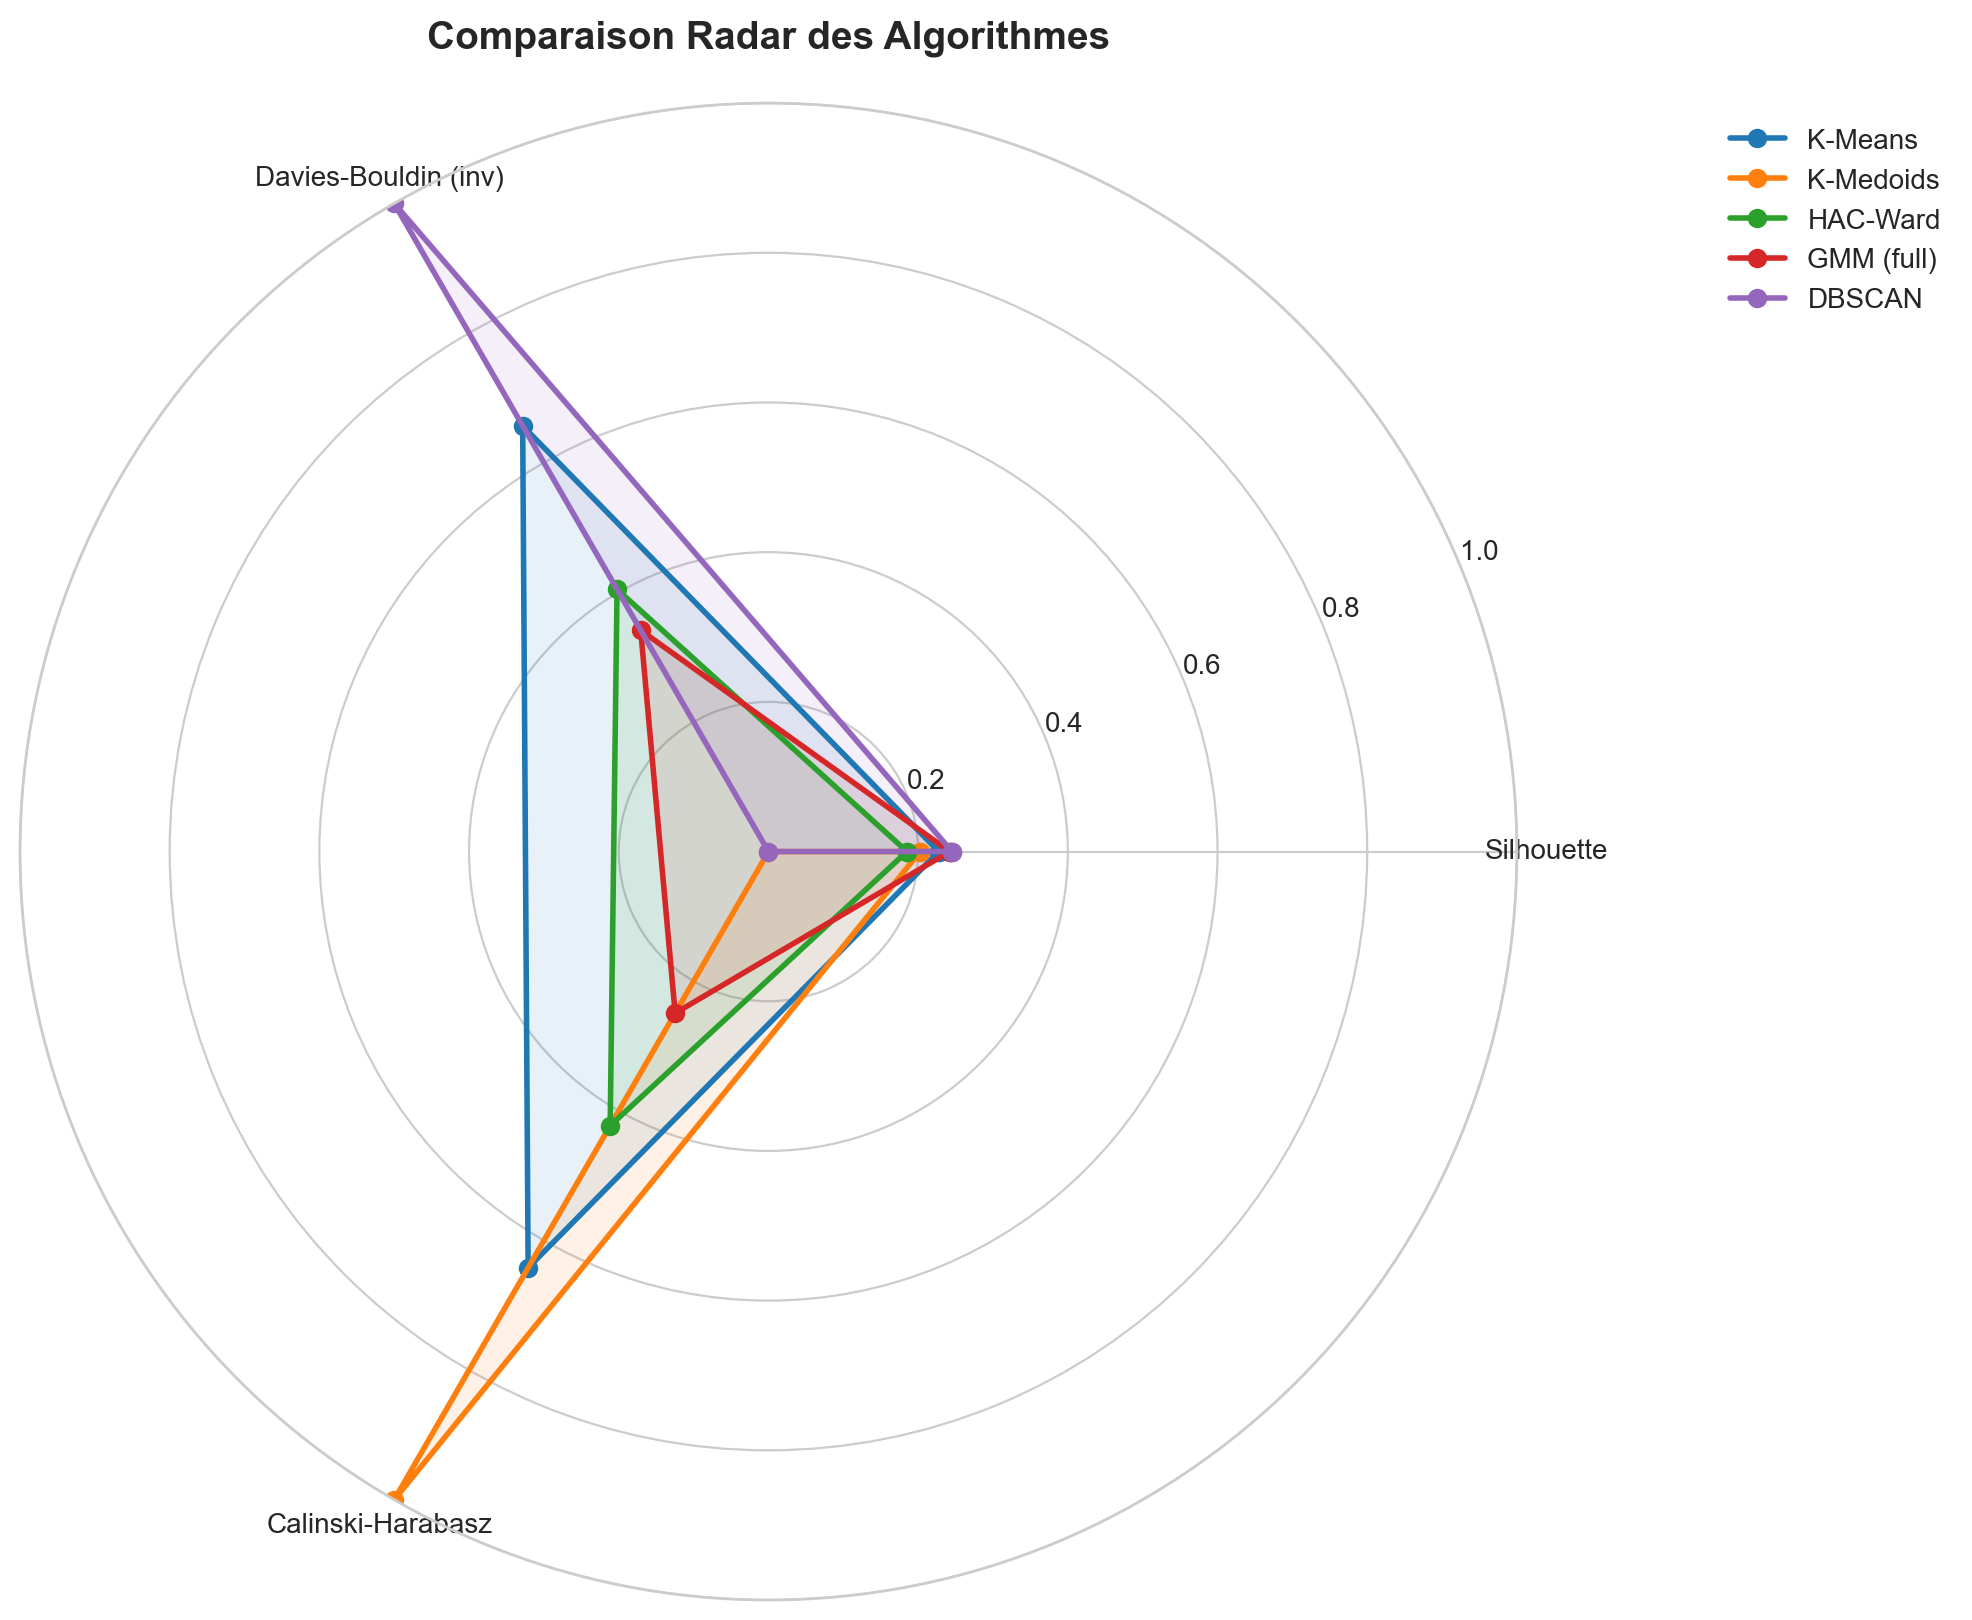


MODÈLE FINAL SÉLECTIONNÉ: GMM (full)
Nombre de clusters: 3
Score global: 0.9476

Distribution finale des clusters:
cluster
0      22
1     402
2    1007
Name: count, dtype: int64


In [17]:
print("=== COMPARAISON FINALE: TOUS LES ALGORITHMES ===")

# Rassembler tous les meilleurs résultats
final_comparison = []

# Cycle 1
final_comparison.append({
    'Cycle': 1,
    'Algorithme': 'K-Means',
    'k': best_k_kmeans,
    'Silhouette': kmeans_df[kmeans_df['k'] == best_k_kmeans]['silhouette'].values[0],
    'Davies_Bouldin': kmeans_df[kmeans_df['k'] == best_k_kmeans]['davies_bouldin'].values[0],
    'Calinski_Harabasz': kmeans_df[kmeans_df['k'] == best_k_kmeans]['calinski_harabasz'].values[0],
    'Score_Global': kmeans_df[kmeans_df['k'] == best_k_kmeans]['score_global'].values[0]
})

final_comparison.append({
    'Cycle': 1,
    'Algorithme': 'K-Medoids',
    'k': best_k_kmedoids,
    'Silhouette': kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['silhouette'].values[0],
    'Davies_Bouldin': kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['davies_bouldin'].values[0],
    'Calinski_Harabasz': kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['calinski_harabasz'].values[0],
    'Score_Global': kmedoids_df[kmedoids_df['k'] == best_k_kmedoids]['score_global'].values[0]
})

final_comparison.append({
    'Cycle': 1,
    'Algorithme': 'HAC-Ward',
    'k': best_k_hac,
    'Silhouette': hac_df[hac_df['k'] == best_k_hac]['silhouette'].values[0],
    'Davies_Bouldin': hac_df[hac_df['k'] == best_k_hac]['davies_bouldin'].values[0],
    'Calinski_Harabasz': hac_df[hac_df['k'] == best_k_hac]['calinski_harabasz'].values[0],
    'Score_Global': hac_df[hac_df['k'] == best_k_hac]['score_global'].values[0]
})

# Cycle 2
final_comparison.append({
    'Cycle': 2,
    'Algorithme': f'GMM ({best_gmm_cov})',
    'k': best_gmm_k,
    'Silhouette': gmm_df.loc[best_gmm_idx, 'silhouette'],
    'Davies_Bouldin': gmm_df.loc[best_gmm_idx, 'davies_bouldin'],
    'Calinski_Harabasz': gmm_df.loc[best_gmm_idx, 'calinski_harabasz'],
    'Score_Global': gmm_df.loc[best_gmm_idx, 'score_global']
})

# DBSCAN
if dbscan_labels is not None:
    final_comparison.append({
        'Cycle': 2,
        'Algorithme': 'DBSCAN',
        'k': n_clusters_dbscan,
        'Silhouette': dbscan_df.loc[best_dbscan_idx, 'silhouette'],
        'Davies_Bouldin': dbscan_df.loc[best_dbscan_idx, 'davies_bouldin'],
        'Calinski_Harabasz': dbscan_df.loc[best_dbscan_idx, 'calinski_harabasz'],
        'Score_Global': dbscan_df.loc[best_dbscan_idx, 'score_global']
    })

final_df = pd.DataFrame(final_comparison)
final_df_sorted = final_df.sort_values('Score_Global', ascending=False)

print("\nTABLEAU COMPARATIF FINAL:")
print(final_df_sorted.to_string(index=False, float_format='%.4f'))

# Visualisation radar chart des métriques
from math import pi

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Normaliser les métriques pour le radar chart
metrics = ['Silhouette', 'Davies_Bouldin_Norm', 'Calinski_Harabasz_Norm']
final_df['Davies_Bouldin_Norm'] = 1 - (final_df['Davies_Bouldin'] - final_df['Davies_Bouldin'].min()) / (final_df['Davies_Bouldin'].max() - final_df['Davies_Bouldin'].min())
final_df['Calinski_Harabasz_Norm'] = (final_df['Calinski_Harabasz'] - final_df['Calinski_Harabasz'].min()) / (final_df['Calinski_Harabasz'].max() - final_df['Calinski_Harabasz'].min())

N = len(metrics)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for idx, row in final_df.iterrows():
    values = [row['Silhouette'], row['Davies_Bouldin_Norm'], row['Calinski_Harabasz_Norm']]
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=row['Algorithme'], color=colors[idx % len(colors)])
    ax.fill(angles, values, alpha=0.1, color=colors[idx % len(colors)])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(['Silhouette', 'Davies-Bouldin (inv)', 'Calinski-Harabasz'])
ax.set_ylim(0, 1)
ax.set_title('Comparaison Radar des Algorithmes', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '17_Comparaison_Radar_des_Algorithmes.png'), dpi=300, bbox_inches='tight')
plt.show()

# Sélection du modèle final
best_model_name = final_df_sorted.iloc[0]['Algorithme']
best_model_k = int(final_df_sorted.iloc[0]['k'])

print(f"\n{'='*60}")
print(f"MODÈLE FINAL SÉLECTIONNÉ: {best_model_name}")
print(f"Nombre de clusters: {best_model_k}")
print(f"Score global: {final_df_sorted.iloc[0]['Score_Global']:.4f}")
print(f"{'='*60}")

# Attribution des labels finaux
if 'K-Means' in best_model_name:
    final_labels = kmeans_labels
    final_model = kmeans_final
elif 'K-Medoids' in best_model_name:
    final_labels = kmedoids_labels
    final_model = kmedoids_final
elif 'HAC' in best_model_name:
    final_labels = hac_labels
    final_model = hac_final
elif 'GMM' in best_model_name:
    final_labels = gmm_labels
    final_model = gmm_final
elif 'DBSCAN' in best_model_name:
    final_labels = dbscan_labels
    final_model = dbscan_final

# Ajout des labels au dataframe
df_scaled['cluster'] = final_labels

print(f"\nDistribution finale des clusters:")
print(df_scaled['cluster'].value_counts().sort_index())

## PROFILS STATISTIQUES DES CLUSTERS
Analyse descriptive des caractéristiques de chaque cluster pour l'interprétation métier.

=== PROFILS STATISTIQUES DES CLUSTERS ===

Statistiques détaillées par cluster:
        mean_load                 load_cv                 load_factor          \
             mean     std  median    mean     std  median        mean     std   
cluster                                                                         
0         -2.1552  0.0357 -2.1634 -0.4419  0.2227 -0.4318     -0.2080  0.3161   
1          0.3570  1.1757  0.2389 -0.0157  0.9552 -0.0315      0.1992  1.1335   
2         -0.0954  0.8425 -0.1210  0.0159  1.0262 -0.0793     -0.0750  0.9412   

                day_night_ratio  ...         max_load                  \
         median            mean  ...  median     mean     std  median   
cluster                          ...                                    
0       -0.1872         -1.1901  ... -1.1855  -2.6082  0.0389 -2.6234   
1        0.0464         -0.0944  ... -0.2027   0.2543  1.1181  0.3740   
2       -0.1523          0.0637  ... -0.0344  -0.0445  0.8646 -0.027

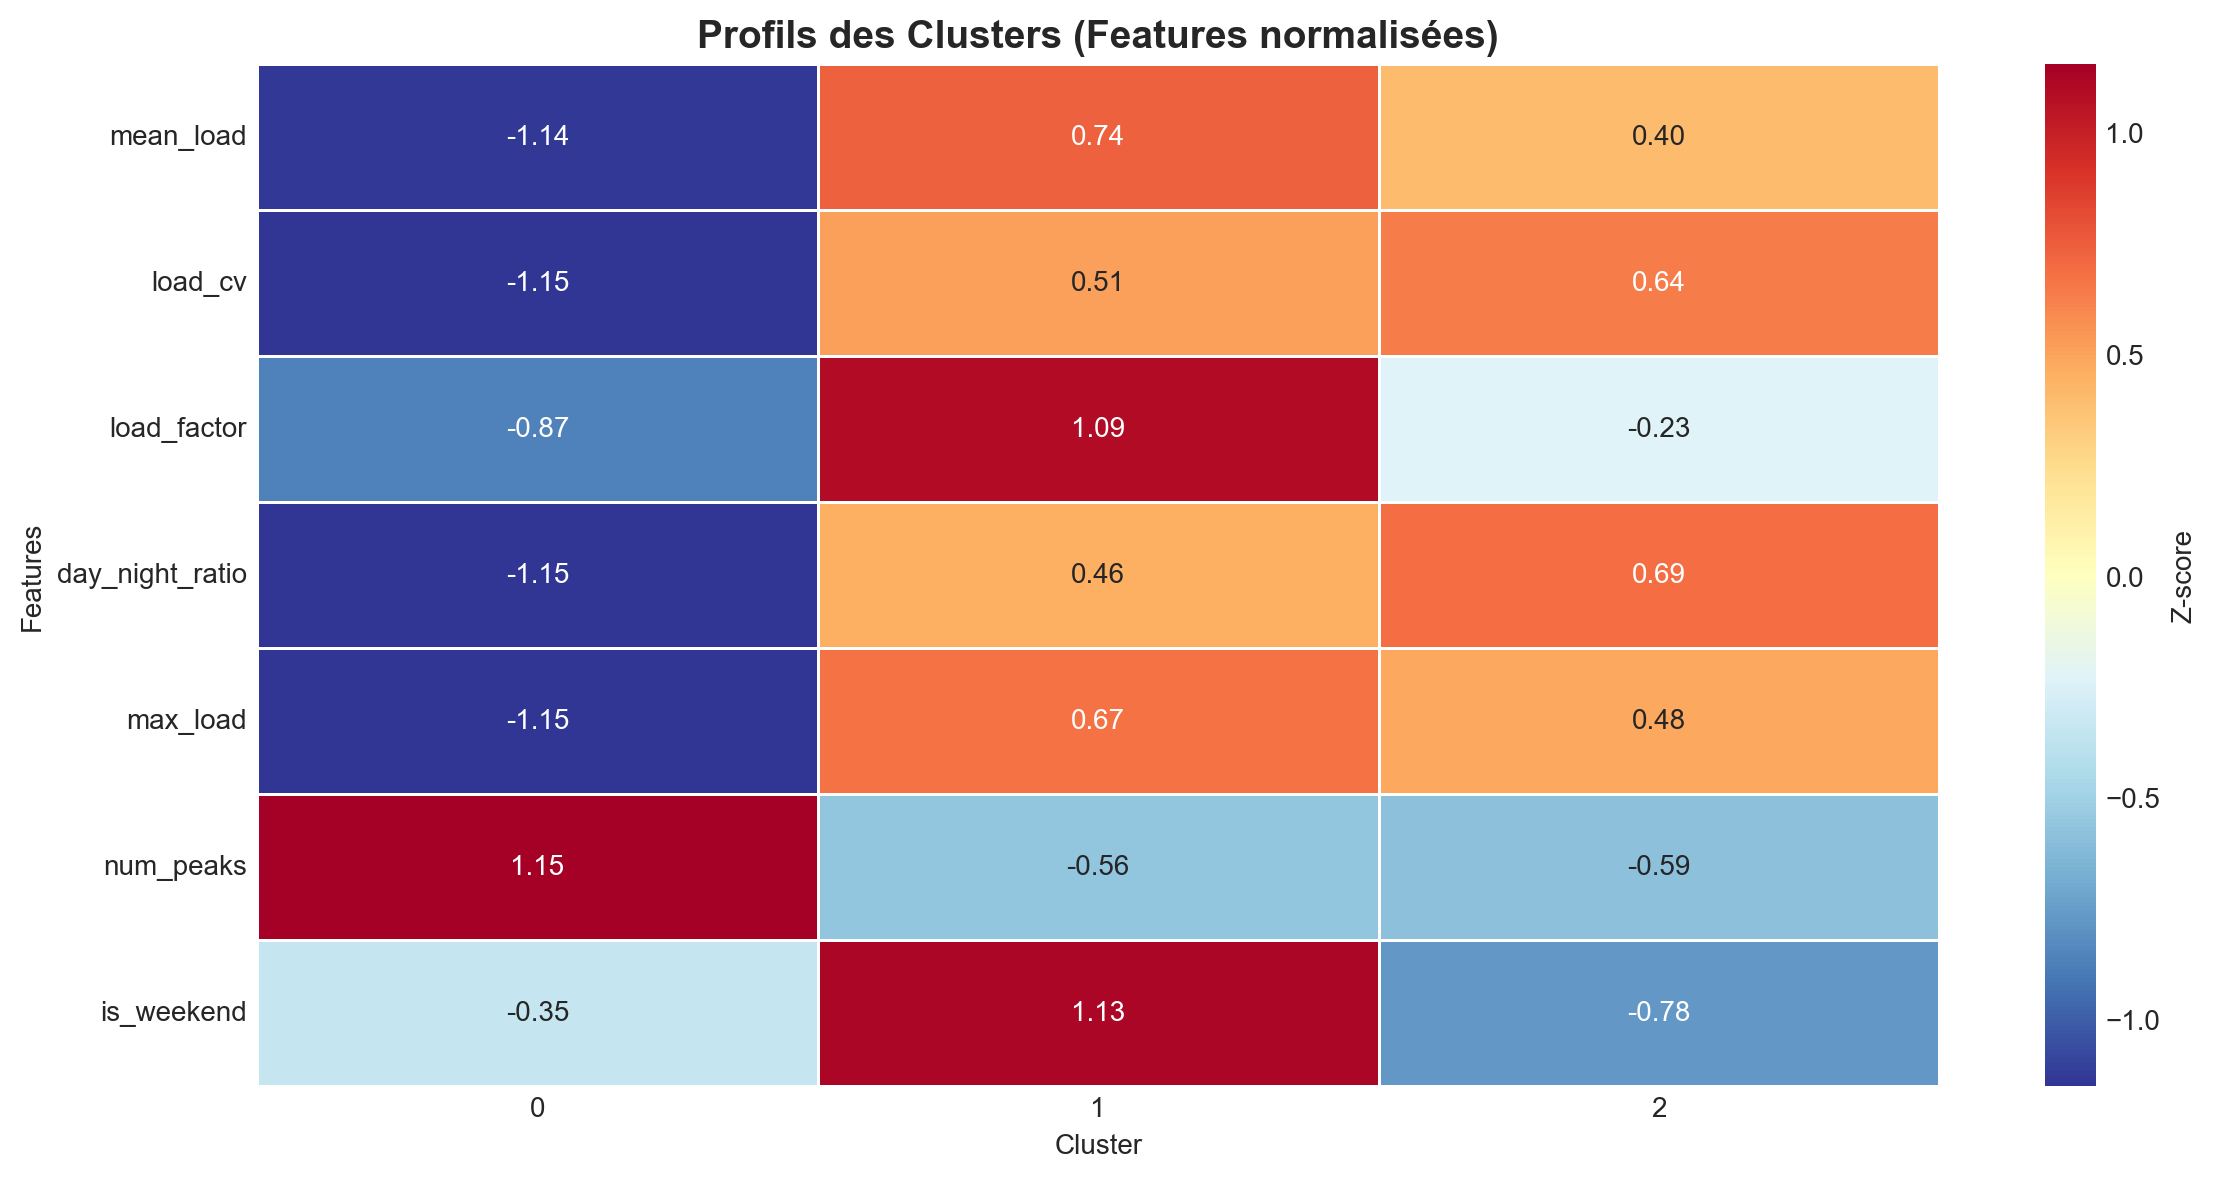

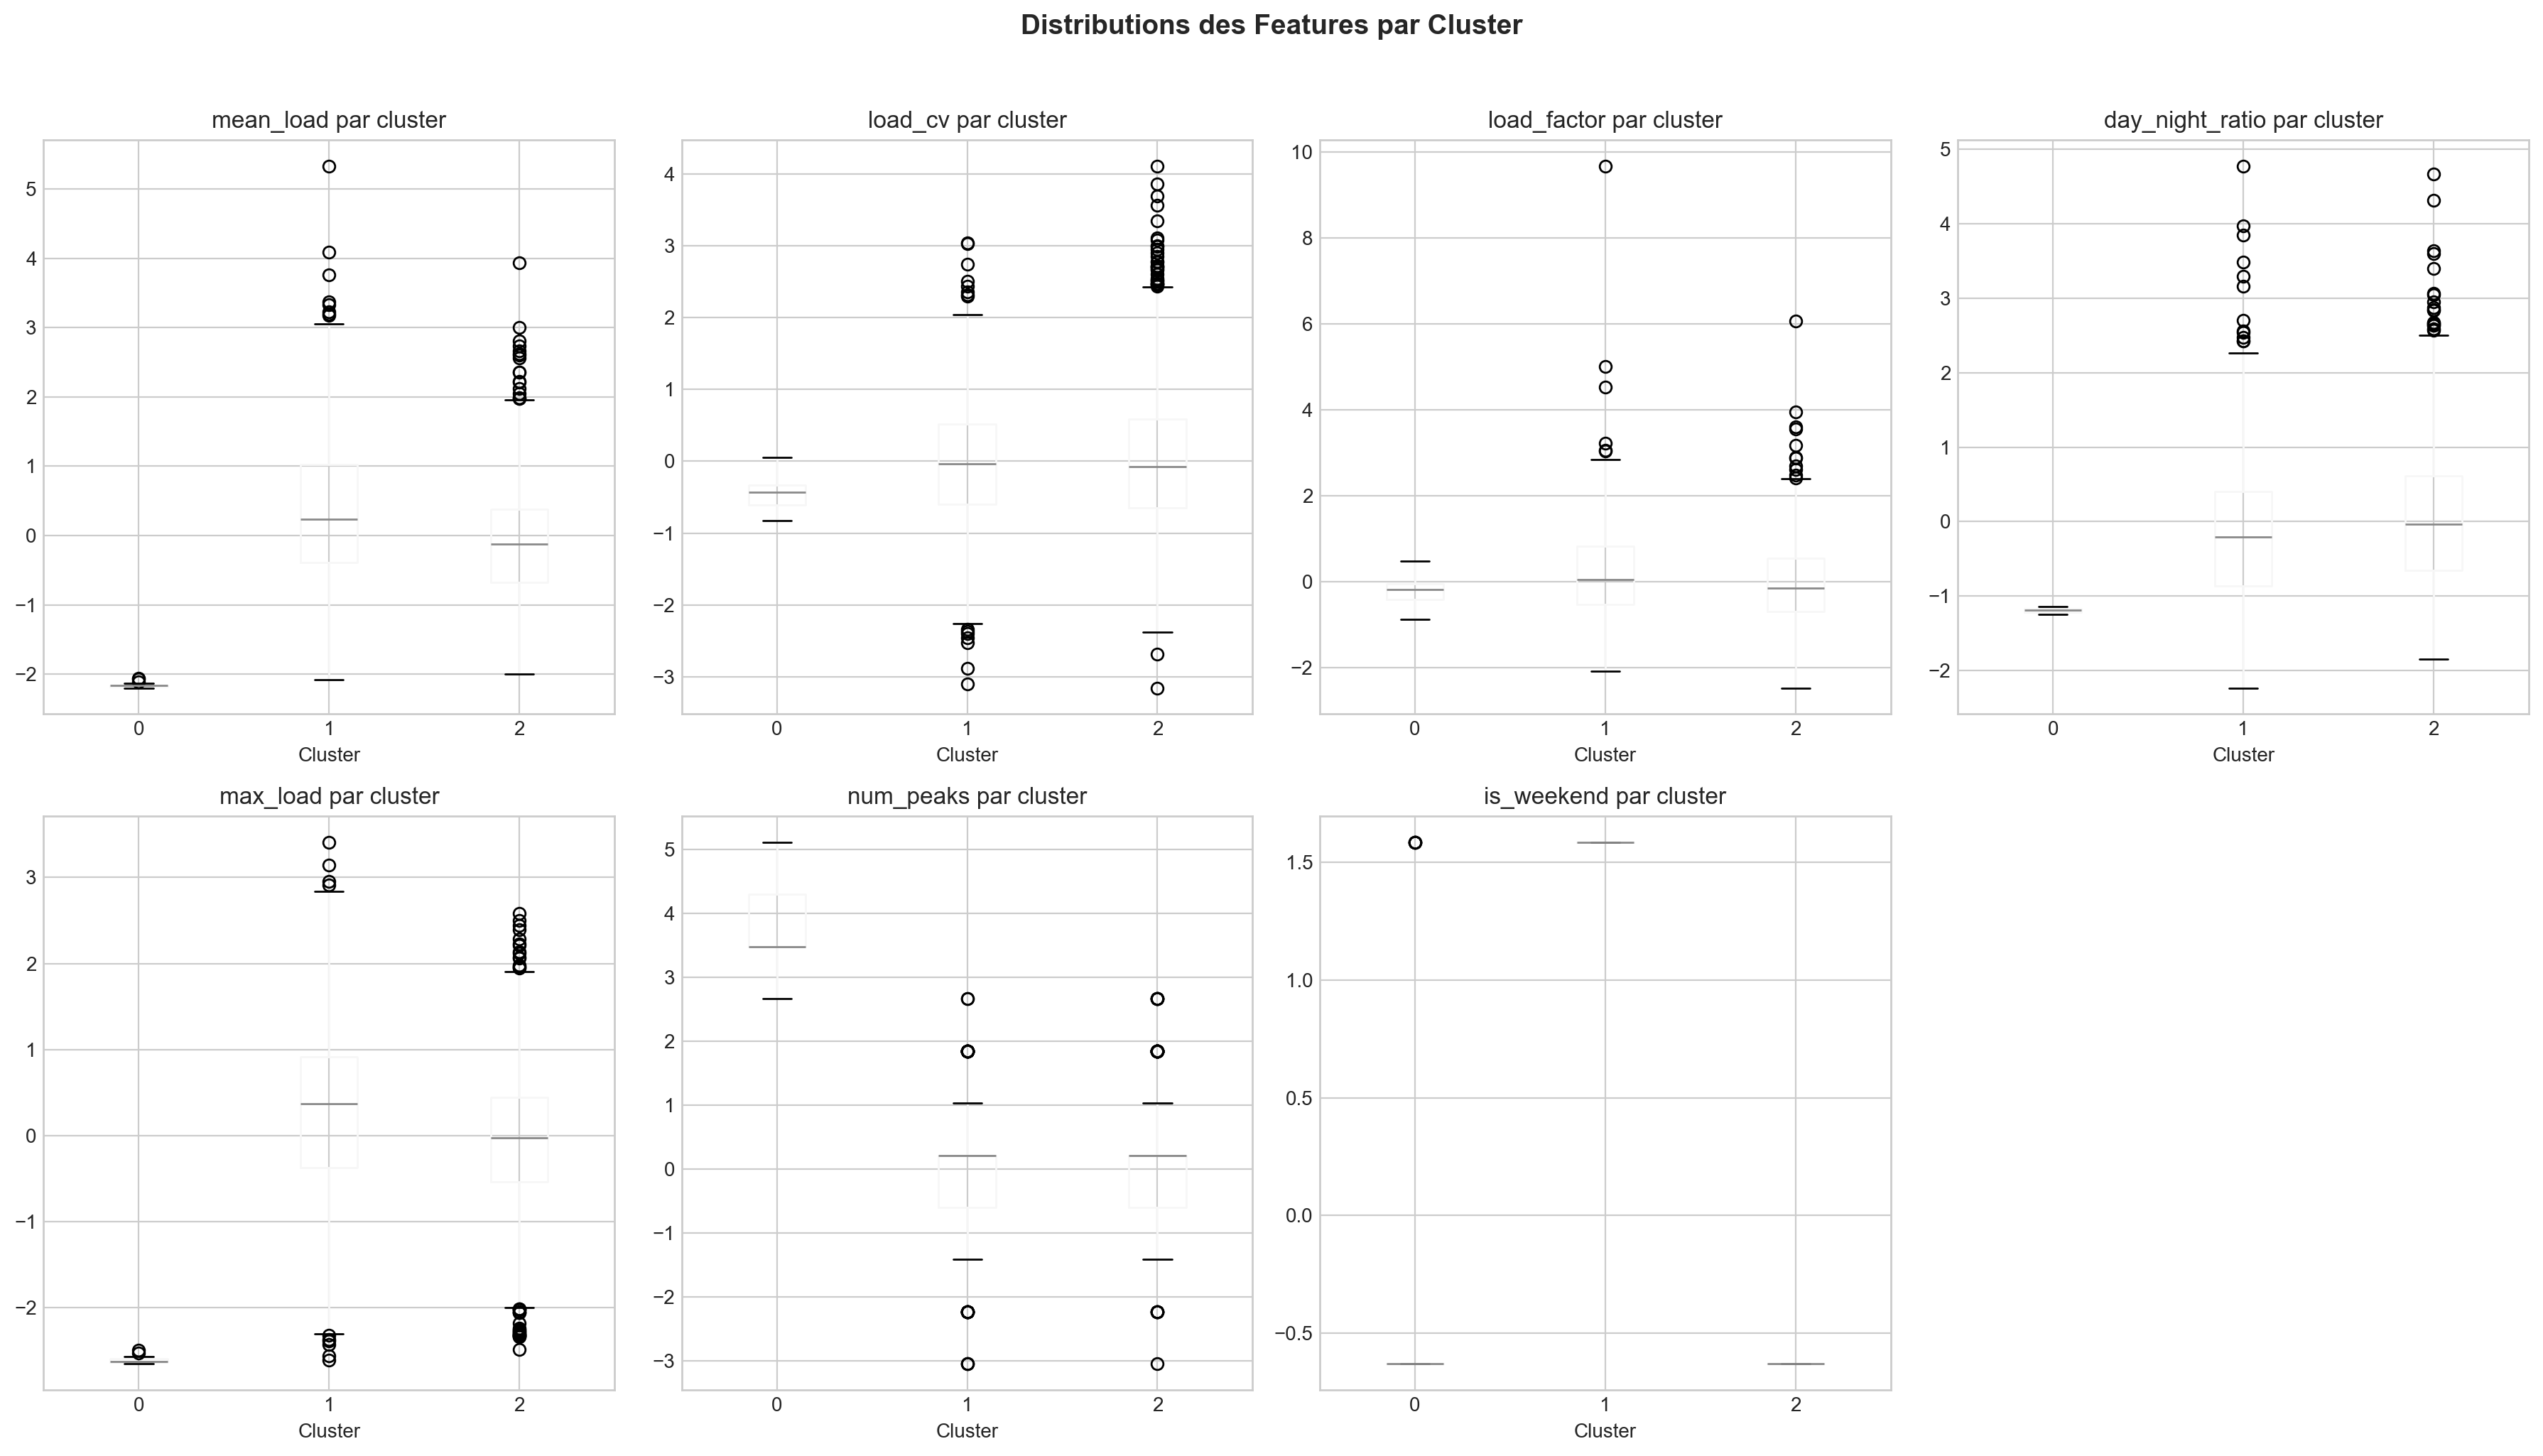

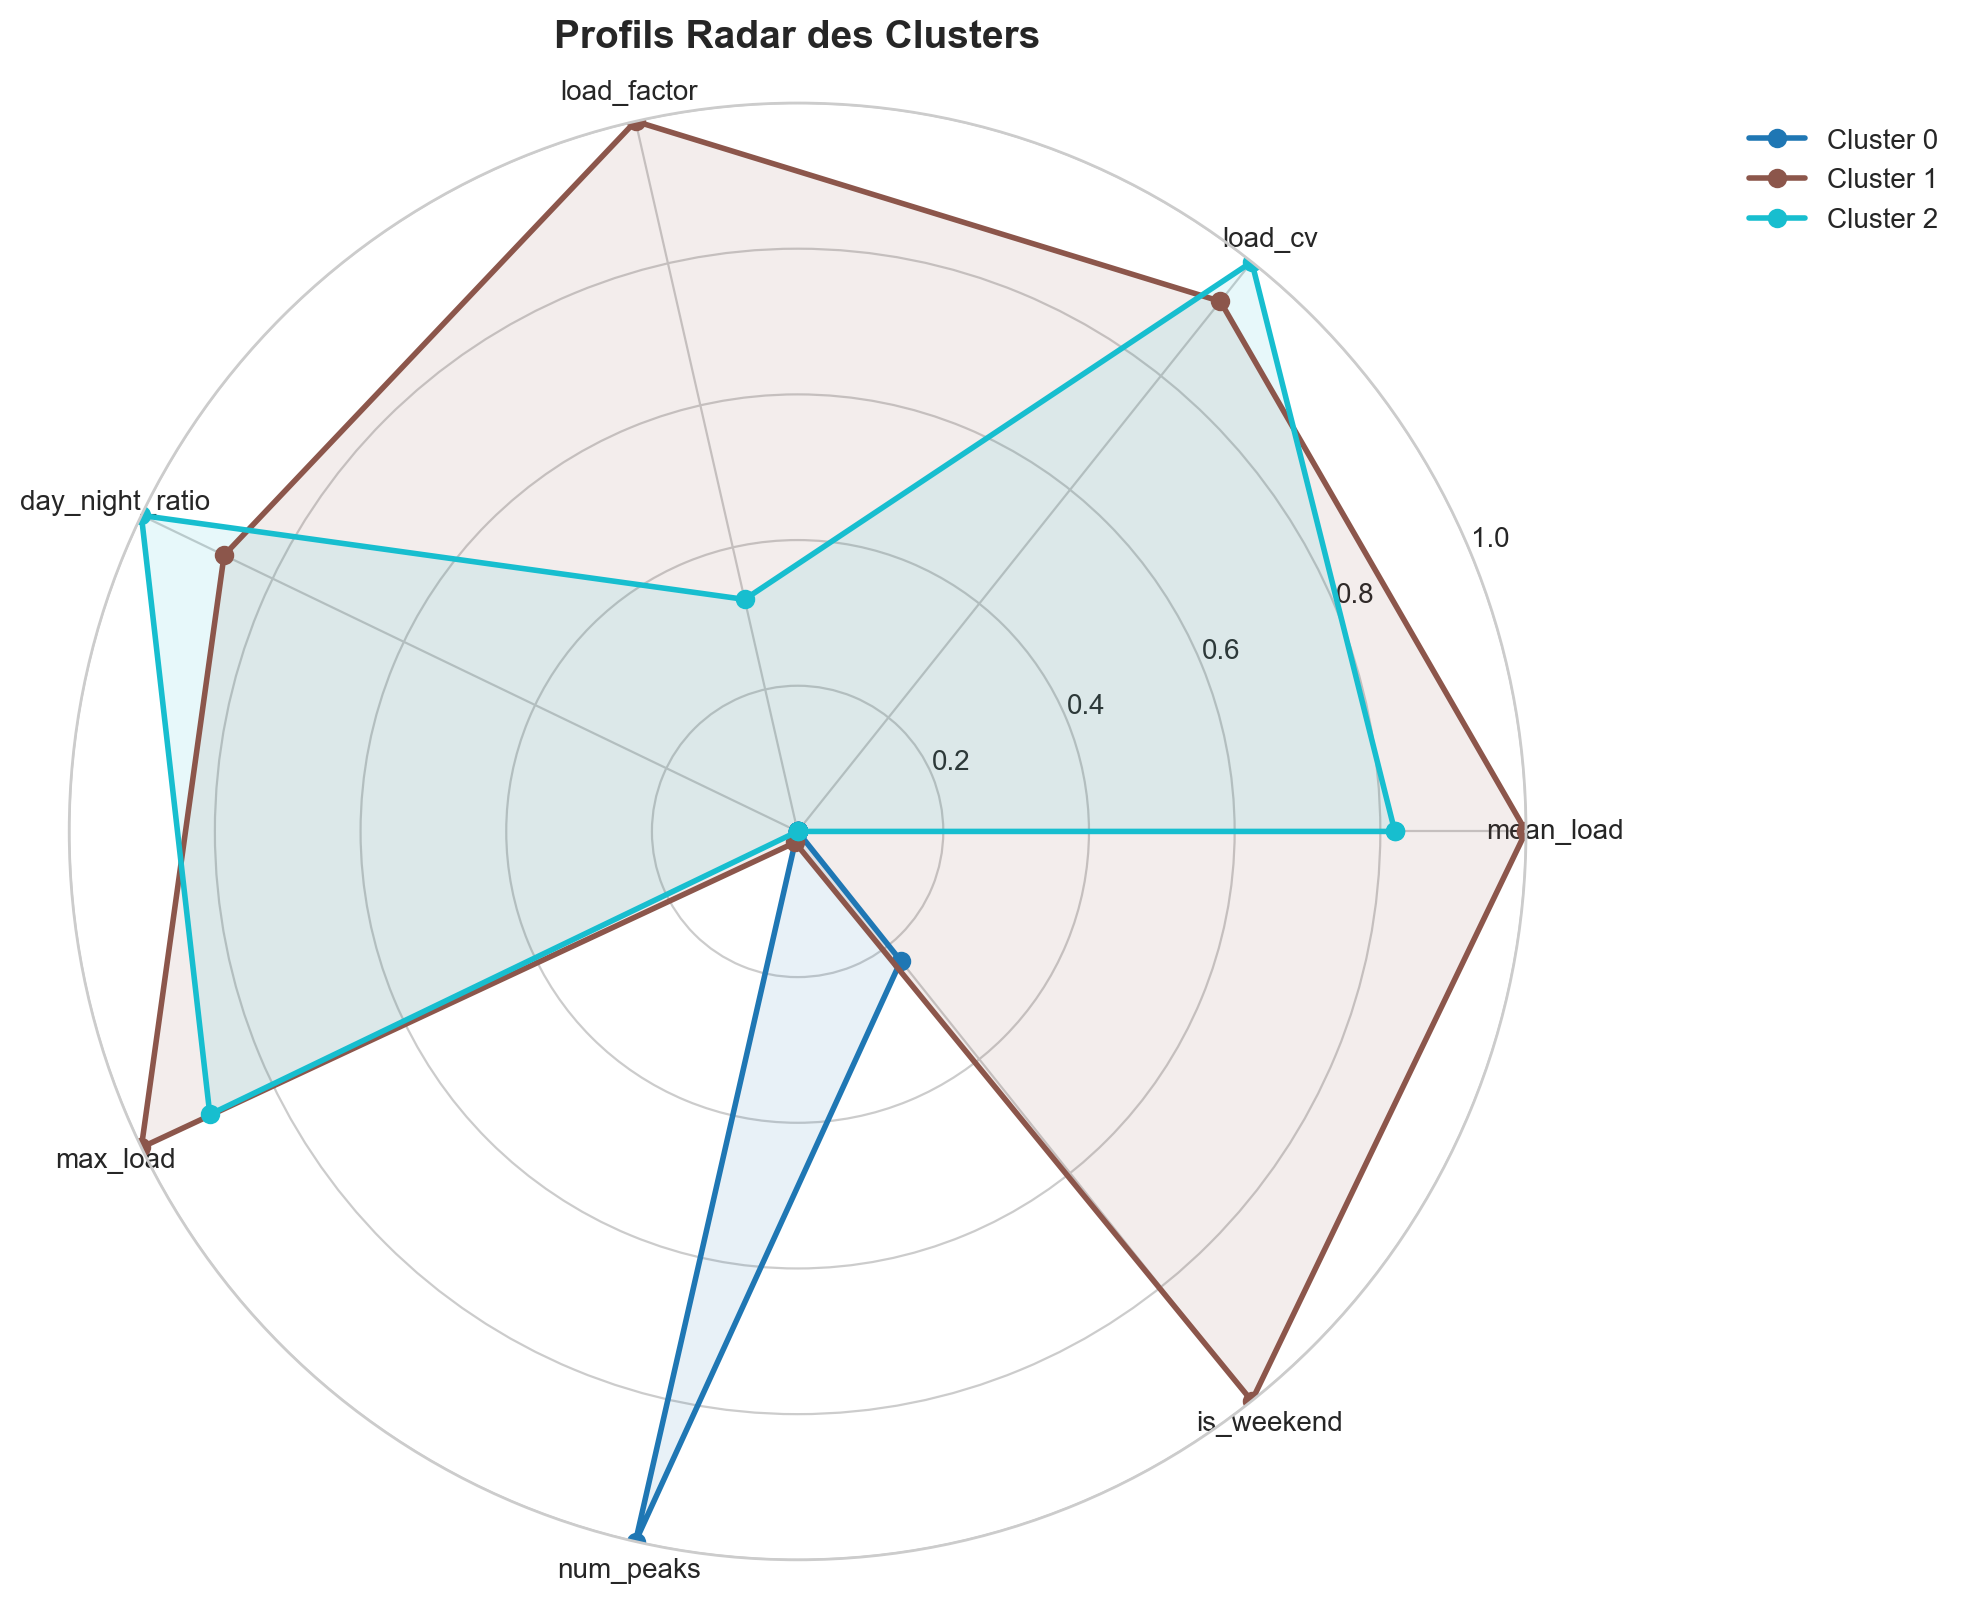

In [18]:
print("=== PROFILS STATISTIQUES DES CLUSTERS ===")

# Statistiques par cluster
cluster_profiles = df_scaled.groupby('cluster')[FEATURES_FINAL].agg(['mean', 'std', 'median'])
print("\nStatistiques détaillées par cluster:")
print(cluster_profiles.round(4))

# Heatmap des profils moyens (centrés pour visualisation)
plt.figure(figsize=(12, 6))
cluster_means = df_scaled.groupby('cluster')[FEATURES_FINAL].mean()

# Normalisation pour la heatmap (z-score par feature)
cluster_means_norm = (cluster_means - cluster_means.mean()) / cluster_means.std()

sns.heatmap(cluster_means_norm.T, annot=True, cmap='RdYlBu_r', center=0,
            fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Z-score'})
plt.title('Profils des Clusters (Features normalisées)', fontsize=14, fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('Features')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '18_Heatmap_des_Profils_des_Clusters.png'), dpi=150, bbox_inches='tight')
plt.show()

# Boxplots par feature et par cluster
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for idx, feature in enumerate(FEATURES_FINAL):
    ax = axes[idx]
    df_scaled.boxplot(column=feature, by='cluster', ax=ax)
    ax.set_title(f'{feature} par cluster')
    ax.set_xlabel('Cluster')

# Supprimer l'axe vide
fig.delaxes(axes[-1])

plt.suptitle('Distributions des Features par Cluster', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '19_Boxplots_des_Features_par_Cluster.png'), dpi=300, bbox_inches='tight')
plt.show()

# Radar chart des profils de clusters
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

N = len(FEATURES_FINAL)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# Normaliser les valeurs moyennes pour le radar
cluster_means_radar = cluster_means.copy()
for col in FEATURES_FINAL:
    cluster_means_radar[col] = (cluster_means_radar[col] - cluster_means_radar[col].min()) / (cluster_means_radar[col].max() - cluster_means_radar[col].min())

colors = plt.cm.tab10(np.linspace(0, 1, len(cluster_means_radar)))

for idx, (cluster_id, row) in enumerate(cluster_means_radar.iterrows()):
    values = row[FEATURES_FINAL].values.tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=f'Cluster {cluster_id}', color=colors[idx])
    ax.fill(angles, values, alpha=0.1, color=colors[idx])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(FEATURES_FINAL, fontsize=10)
ax.set_ylim(0, 1)
ax.set_title('Profils Radar des Clusters', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '20_Profils_Radar_des_Clusters.png'), dpi=300, bbox_inches='tight')
plt.show()

## RECONSTRUCTION COMPLÈTE DES FEATURES JOURNALIÈRES ET PRÉDICTION DES CLUSTERS AVEC GMM

✓ daily_profiles : 1433 jours × 24h
🔧 Reconstruction des features avec dates...
✓ Features construites : 1416 jours
📊 Distribution des clusters :
   Cluster 0 : 24 jours (Faible conso)
   Cluster 1 : 394 jours (Week-end)
   Cluster 2 : 998 jours (Semaine standard)
✓ Profils horaires alignés : 1416 jours
   Répartition :
cluster
0     24
1    394
2    998
Name: count, dtype: int64


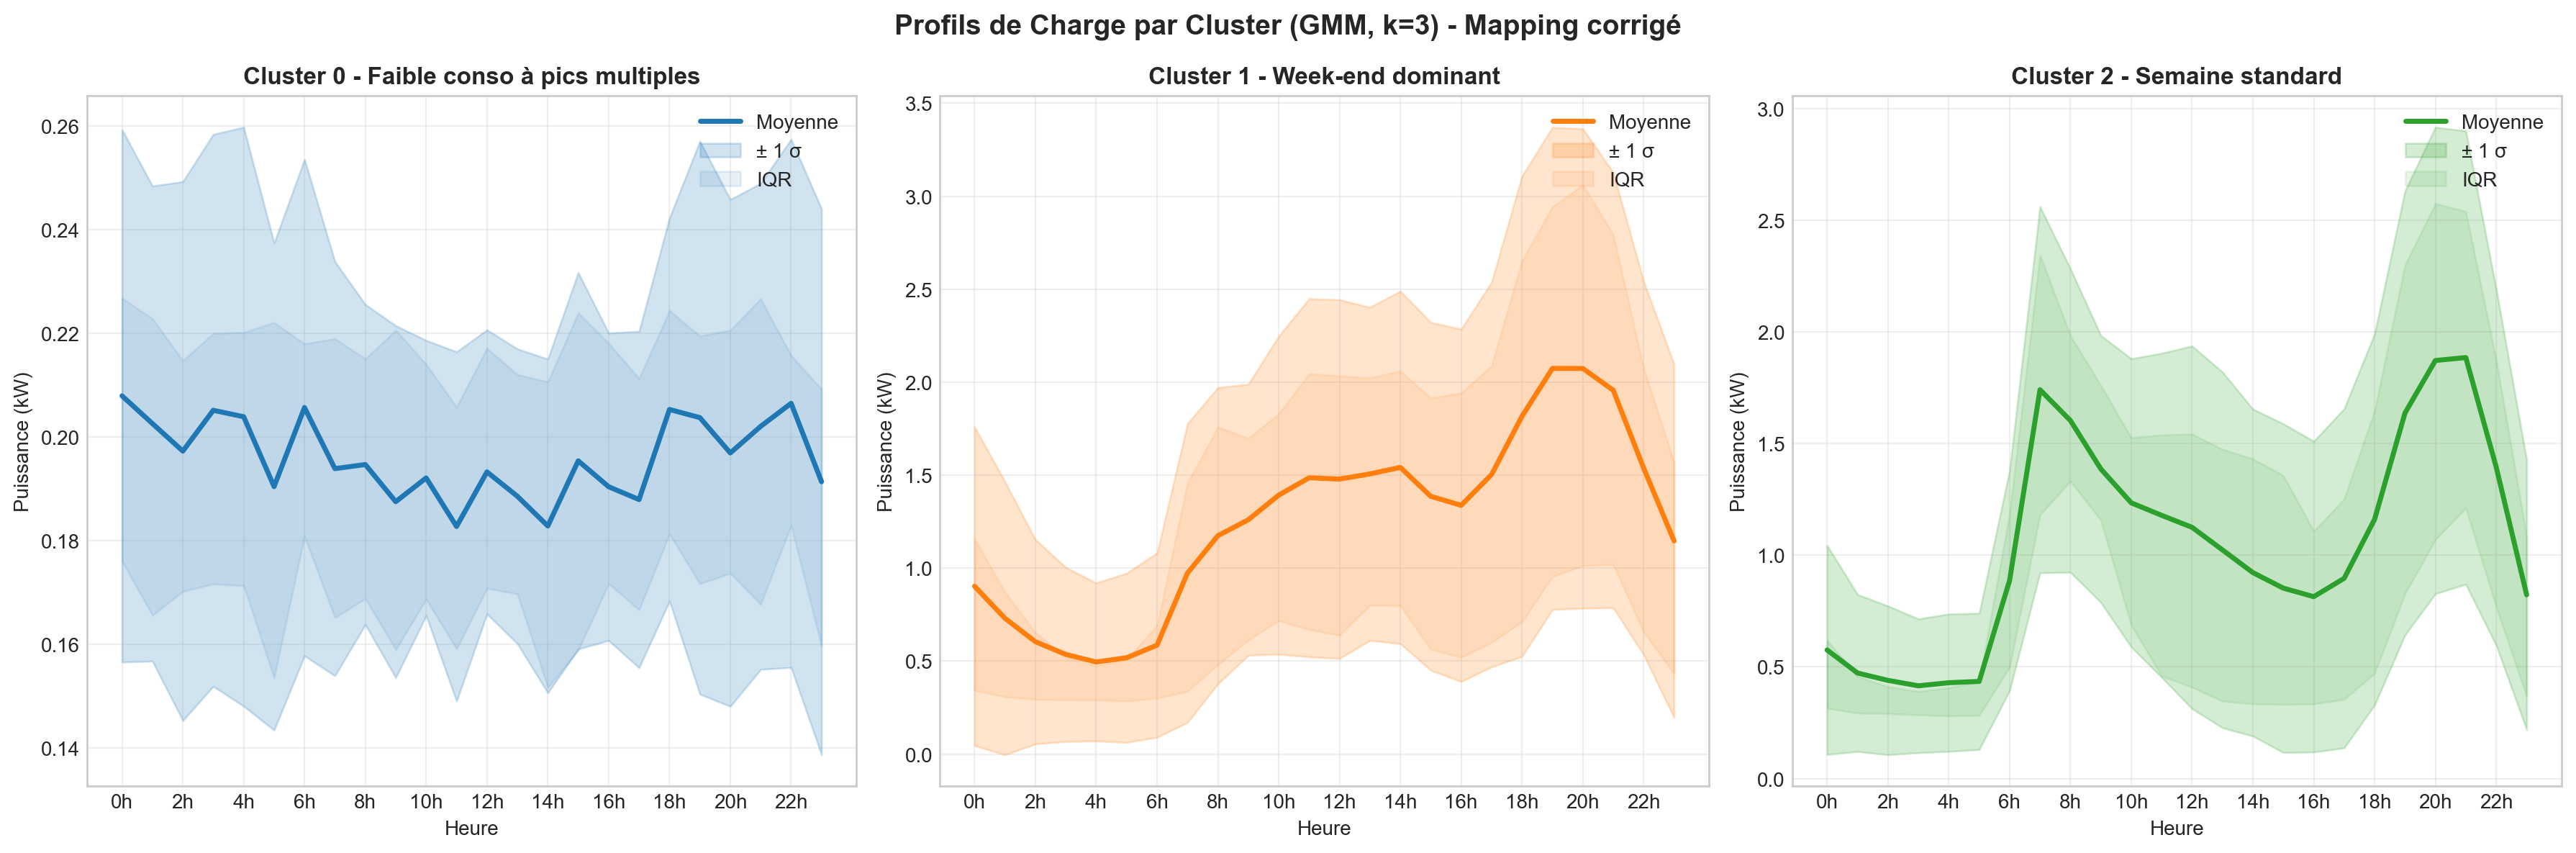


✓ Figure sauvegardée : d:\projet\Projet clustering\Projet household clustering\results\images\21_Load_Curves_per_Cluster_CORRECT.png


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from scipy.signal import find_peaks

# ============================================================
# 1. CHARGEMENT DES DONNÉES BRUTES ET CONSTRUCTION DES PROFILS
# ============================================================

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
DATA_DIR = os.path.join(BASE_DIR, "data", "processed")
CSV_PATH = os.path.join(DATA_DIR, "household_power_consumption_cleaned.csv")

df_clean = pd.read_csv(CSV_PATH)
df_clean['DateTime'] = pd.to_datetime(df_clean['DateTime'])
df_clean['Date_only'] = df_clean['DateTime'].dt.date
df_clean['Hour'] = df_clean['DateTime'].dt.hour

# Créer les profils horaires
daily_profiles = df_clean.pivot_table(
    index='Date_only',
    columns='Hour',
    values='Global_active_power',
    aggfunc='mean'
)
daily_profiles = daily_profiles.fillna(daily_profiles.mean(axis=0))
print(f"✓ daily_profiles : {daily_profiles.shape[0]} jours × 24h")

# ============================================================
# 2. RECONSTRUIRE LES FEATURES DANS UN DATAFRAME AVEC LA DATE
# ============================================================
features_list = []
dates = df_clean['Date_only'].unique()

print("🔧 Reconstruction des features avec dates...")
for day in dates:
    day_data = df_clean[df_clean['Date_only'] == day]
    if len(day_data) < 1380:  # Jours incomplets exclus
        continue
    
    gap = day_data.groupby('Hour')['Global_active_power'].mean()
    grp = day_data.groupby('Hour')['Global_reactive_power'].mean()
    
    mean_load = gap.mean()
    std_load = gap.std()
    load_cv = std_load / mean_load if mean_load > 0 else 0
    max_load = gap.max()
    load_factor = mean_load / max_load if max_load > 0 else 0
    
    day_consum = gap.loc[6:21].sum()
    night_consum = gap.loc[22:23].sum() + gap.loc[0:5].sum()
    day_night_ratio = day_consum / night_consum if night_consum > 0 else 10
    
    # Pics
    if len(gap.dropna()) > 0:
        peaks, _ = find_peaks(gap.values, height=gap.mean(), distance=2)
        num_peaks = len(peaks)
    else:
        num_peaks = 0
    
    # is_weekend (binaire)
    dt = pd.Timestamp(day)
    is_weekend = 1 if dt.dayofweek >= 5 else 0
    
    features_list.append({
        'date': day,
        'mean_load': mean_load,
        'load_cv': load_cv,
        'load_factor': load_factor,
        'day_night_ratio': day_night_ratio,
        'max_load': max_load,
        'num_peaks': num_peaks,
        'is_weekend': is_weekend
    })

df_features = pd.DataFrame(features_list)
print(f"✓ Features construites : {df_features.shape[0]} jours")

# ============================================================
# 3. STANDARDISATION ET GMM
# ============================================================
FEATURES_FINAL = ['mean_load', 'load_cv', 'load_factor', 'day_night_ratio', 'max_load', 'num_peaks', 'is_weekend']
X = df_features[FEATURES_FINAL].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42, max_iter=200, n_init=10)
labels = gmm.fit_predict(X_scaled)

# ============================================================
# 4. RÉORDONNER LES CLUSTERS PAR TAILLE (0 = plus petit)
# ============================================================
unique, counts = np.unique(labels, return_counts=True)
sorted_idx = np.argsort(counts)  # [petit, moyen, grand]
mapping = {old: new for new, old in enumerate(sorted_idx)}
labels_ordered = np.array([mapping[l] for l in labels])

# Ajouter les labels réordonnés AU DATAFRAME (c'est la clé !)
df_features['cluster'] = labels_ordered

# Vérifier les tailles
final_counts = np.bincount(labels_ordered)
print(f"📊 Distribution des clusters :")
print(f"   Cluster 0 : {final_counts[0]} jours (Faible conso)")
print(f"   Cluster 1 : {final_counts[1]} jours (Week-end)")
print(f"   Cluster 2 : {final_counts[2]} jours (Semaine standard)")

# ============================================================
# 5. JOINTURE EXPLICITE SUR LA DATE (PARFAITE ET SÉCURISÉE)
# ============================================================
# On récupère les colonnes date et cluster
date_cluster_mapping = df_features[['date', 'cluster']].copy()

# On fusionne avec daily_profiles (qui a les dates en index)
daily_profiles_with_clusters = daily_profiles.merge(
    date_cluster_mapping,
    left_index=True,  # L'index de daily_profiles (les dates)
    right_on='date',  # La colonne 'date' de date_cluster_mapping
    how='inner'       # On garde uniquement les dates présentes dans les deux
)

# On remet la date comme index pour le confort
daily_profiles_with_clusters = daily_profiles_with_clusters.set_index('date')

print(f"✓ Profils horaires alignés : {daily_profiles_with_clusters.shape[0]} jours")
print(f"   Répartition :\n{daily_profiles_with_clusters['cluster'].value_counts().sort_index()}")

# ============================================================
# 6. VISUALISATION (ENFIN, AVEC LES BONNES DONNÉES !)
# ============================================================
IMAGES_DIR = os.path.join(BASE_DIR, "results", "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
clusters = sorted(daily_profiles_with_clusters['cluster'].unique())

for i, cluster_id in enumerate(clusters):
    ax = axes[i]
    # Filtrer les jours du cluster
    cluster_data = daily_profiles_with_clusters[daily_profiles_with_clusters['cluster'] == cluster_id]
    # Supprimer la colonne cluster pour ne garder que les heures
    cluster_curves = cluster_data.drop(columns='cluster')
    
    mean_curve = cluster_curves.mean(axis=0)
    std_curve = cluster_curves.std(axis=0)
    q25 = cluster_curves.quantile(0.25, axis=0)
    q75 = cluster_curves.quantile(0.75, axis=0)
    
    hours = range(24)
    ax.plot(hours, mean_curve, color=colors[i], linewidth=2.5, label='Moyenne')
    ax.fill_between(hours, mean_curve - std_curve, mean_curve + std_curve, 
                    color=colors[i], alpha=0.2, label='± 1 σ')
    ax.fill_between(hours, q25, q75, color=colors[i], alpha=0.1, label='IQR')
    
    # Nom métier
    if cluster_id == 0:
        name = "Faible conso à pics multiples"
    elif cluster_id == 1:
        name = "Week-end dominant"
    else:
        name = "Semaine standard"
    
    ax.set_title(f'Cluster {cluster_id} - {name}', fontweight='bold')
    ax.set_xlabel('Heure')
    ax.set_ylabel('Puissance (kW)')
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels([f'{h}h' for h in range(0, 24, 2)])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

plt.suptitle('Profils de Charge par Cluster (GMM, k=3) - Mapping corrigé', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '21_Load_Curves_per_Cluster_CORRECT.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Figure sauvegardée : {os.path.join(IMAGES_DIR, '21_Load_Curves_per_Cluster_CORRECT.png')}")

## EXPLICABILITÉ - XGBOOST CLASSIFICATEUR SURROGATE
Entraînement d'un modèle XGBoost pour prédire les clusters (classification supervisée). Les features importance et SHAP values révèlent quelles variables discriminent chaque cluster.

=== EXPLICABILITÉ: XGBOOST CLASSIFICATEUR SURROGATE ===

Taille train: (1001, 7), Taille test: (430, 7)
Distribution des classes (train): [ 15 281 705]
Distribution des classes (test): [  7 121 302]

Entraînement du modèle XGBoost...

PERFORMANCE DU SURROGATE XGBOOST
Accuracy sur test: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         7
           1       1.00      1.00      1.00       121
           2       1.00      1.00      1.00       302

    accuracy                           1.00       430
   macro avg       1.00      1.00      1.00       430
weighted avg       1.00      1.00      1.00       430



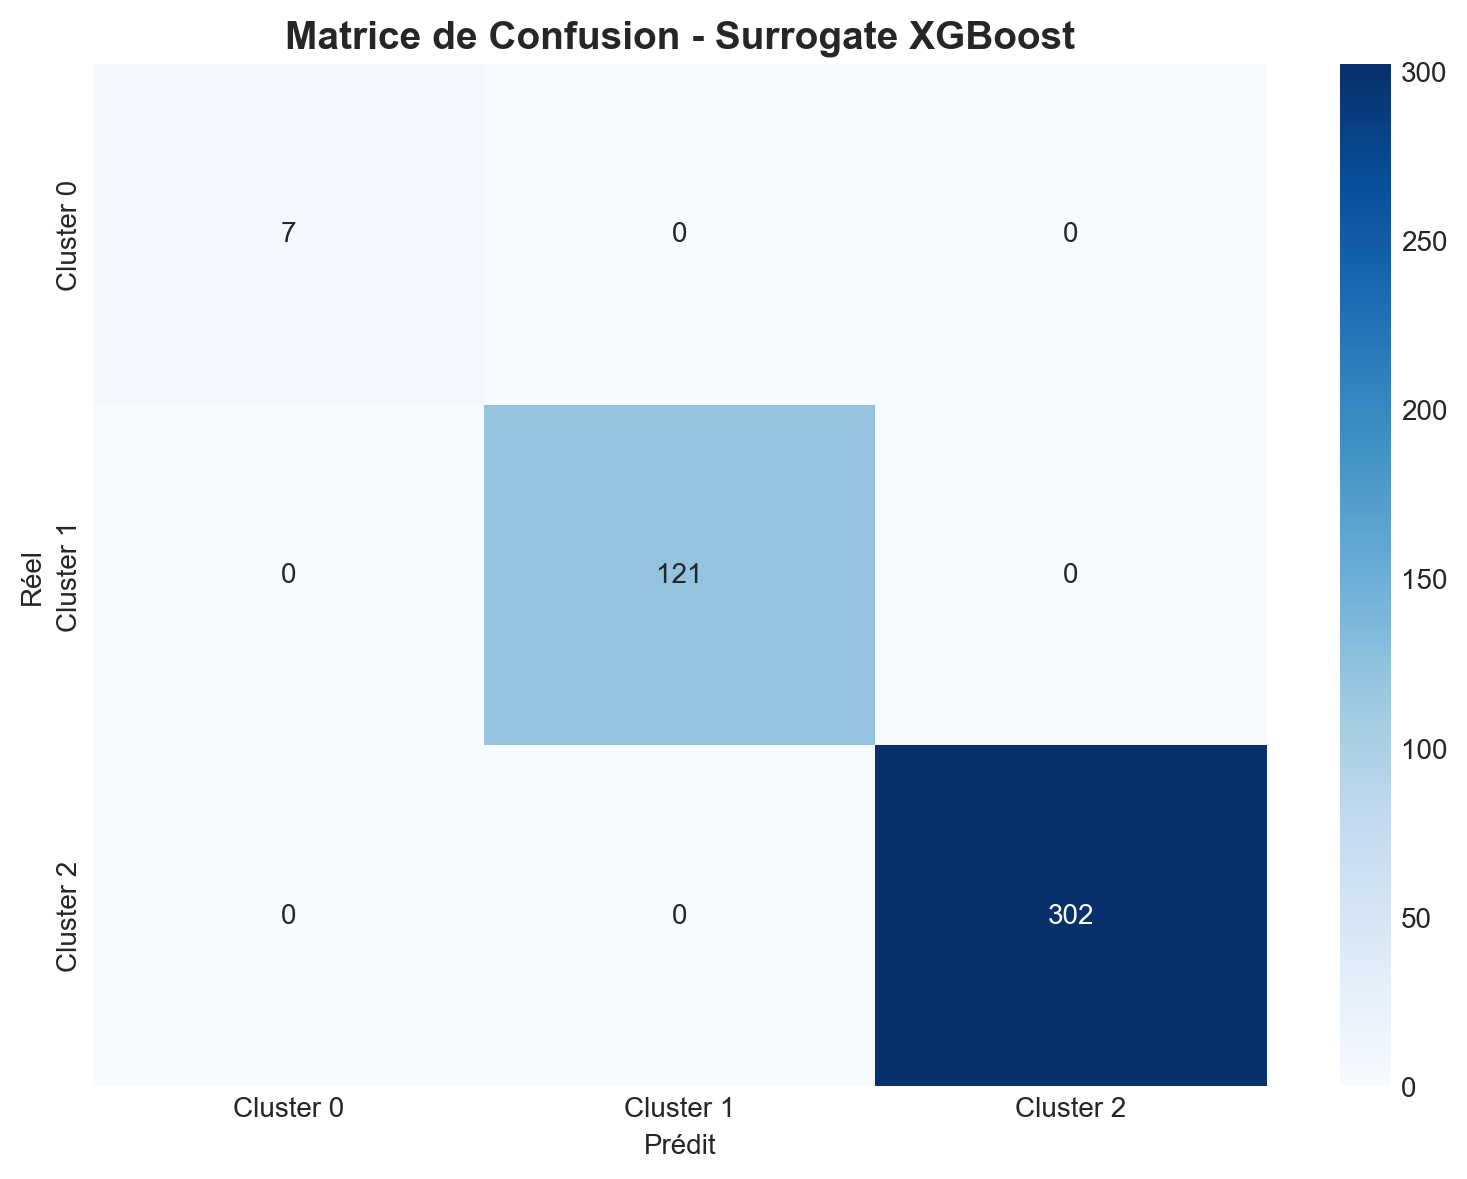

In [20]:
print("=== EXPLICABILITÉ: XGBOOST CLASSIFICATEUR SURROGATE ===")

# Préparation des données pour la classification supervisée
X_features = df_scaled[FEATURES_FINAL].values
y_clusters = df_scaled['cluster'].values

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_clusters, test_size=0.3, random_state=42, stratify=y_clusters
)

print(f"\nTaille train: {X_train.shape}, Taille test: {X_test.shape}")
print(f"Distribution des classes (train): {np.bincount(y_train)}")
print(f"Distribution des classes (test): {np.bincount(y_test)}")

# Entraînement XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss',
    use_label_encoder=False
)

print("\nEntraînement du modèle XGBoost...")
xgb_model.fit(X_train, y_train)

# Évaluation du surrogate
y_pred = xgb_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n{'='*60}")
print(f"PERFORMANCE DU SURROGATE XGBOOST")
print(f"{'='*60}")
print(f"Accuracy sur test: {accuracy:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred))

# Matrice de confusion
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[f'Cluster {i}' for i in sorted(np.unique(y_clusters))],
            yticklabels=[f'Cluster {i}' for i in sorted(np.unique(y_clusters))])
plt.title('Matrice de Confusion - Surrogate XGBoost', fontsize=14, fontweight='bold')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '22_Matrice_de_Confusion_Surrogate XGBoost.png'), dpi=300, bbox_inches='tight')
plt.show()

## FEATURE IMPORTANCE ET SHAP VALUES
Analyse des features les plus discriminantes via l'importance des variables et les SHAP values pour une explicabilité globale et locale.

=== FEATURE IMPORTANCE GLOBALE (XGBoost) ===


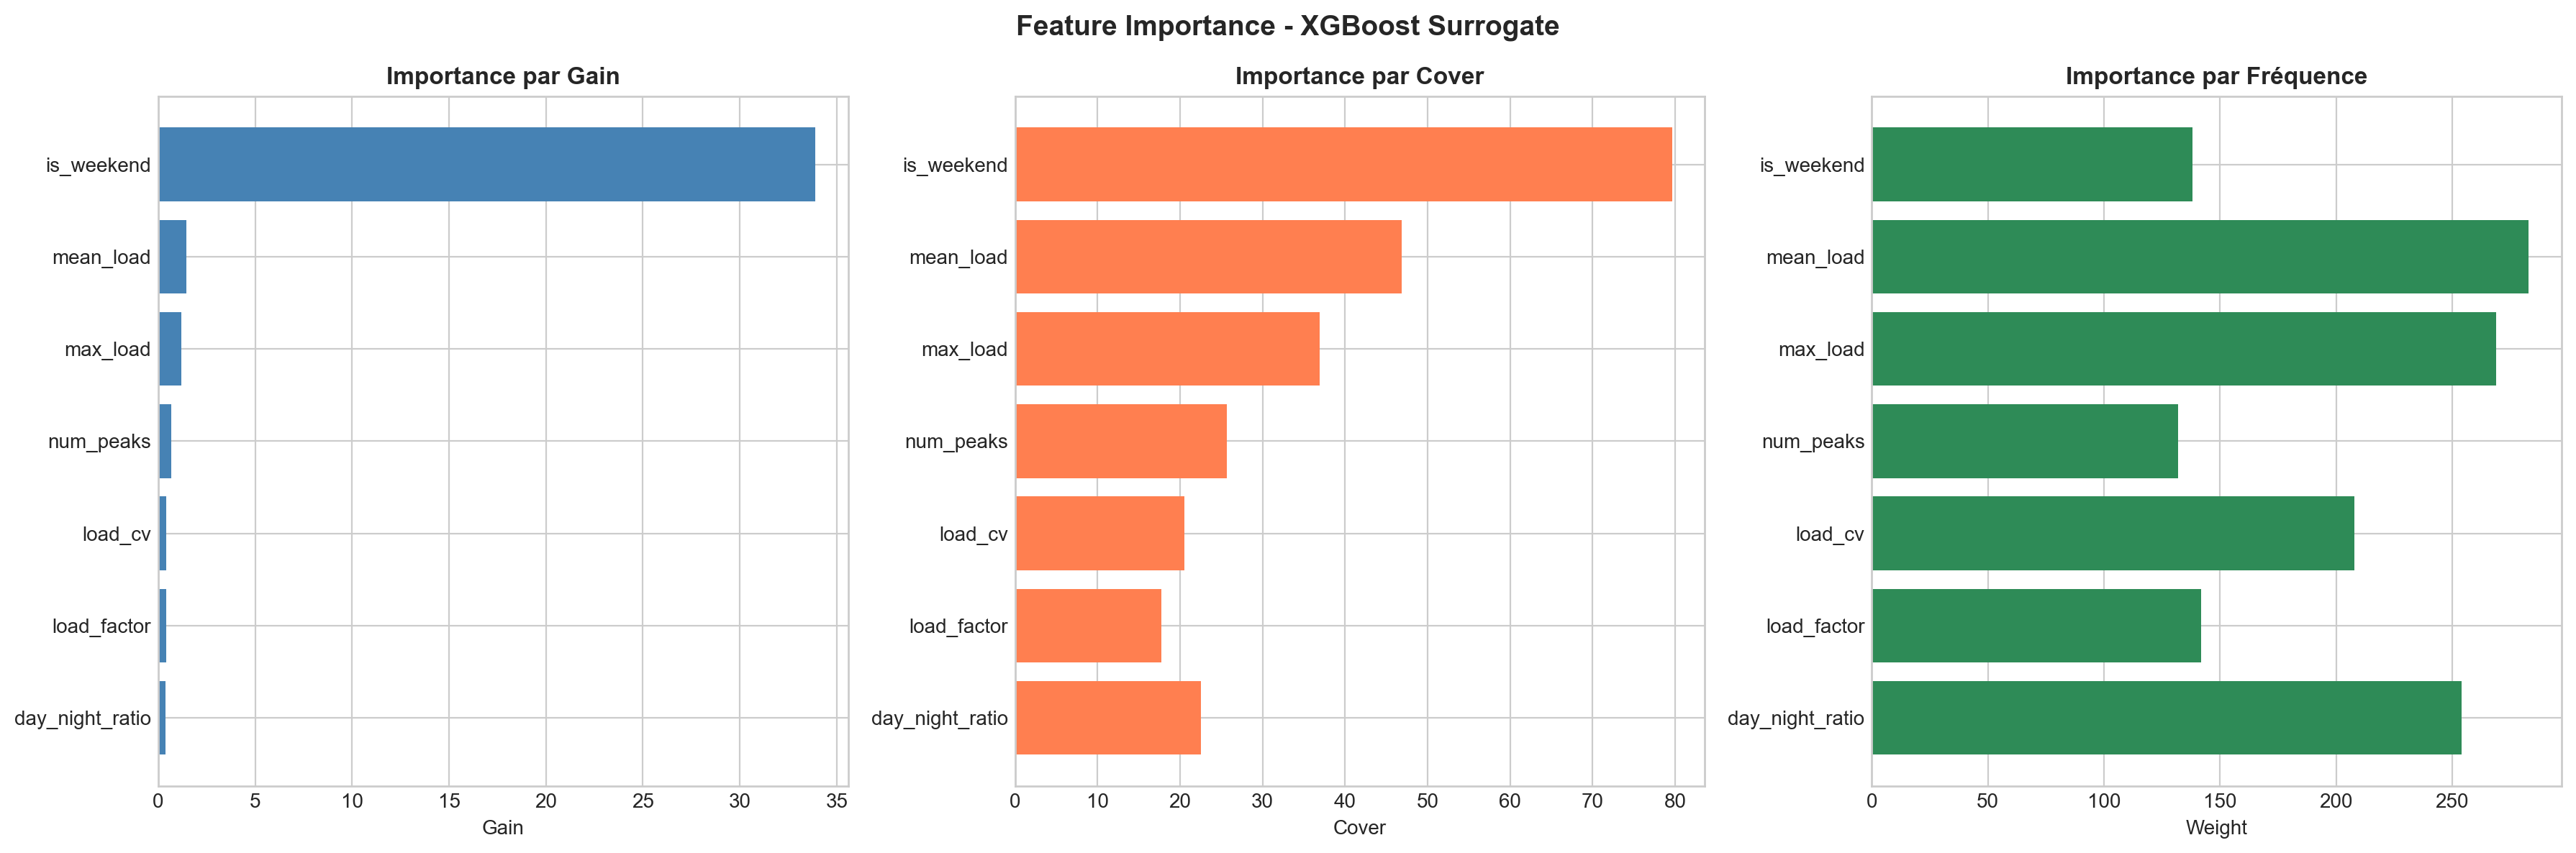


Tableau d'importance:
feature    feature_name      gain     cover  weight
     f6      is_weekend 33.885986 79.618568   138.0
     f0       mean_load  1.455854 46.866314   283.0
     f4        max_load  1.184519 36.938148   269.0
     f5       num_peaks  0.664103 25.647854   132.0
     f1         load_cv  0.421619 20.570095   208.0
     f2     load_factor  0.415164 17.732267   142.0
     f3 day_night_ratio  0.366237 22.555334   254.0

=== ANALYSE SHAP (SHapley Additive explanations) ===

Shape des SHAP values: (1431, 7, 3)


<Figure size 2000x1600 with 0 Axes>

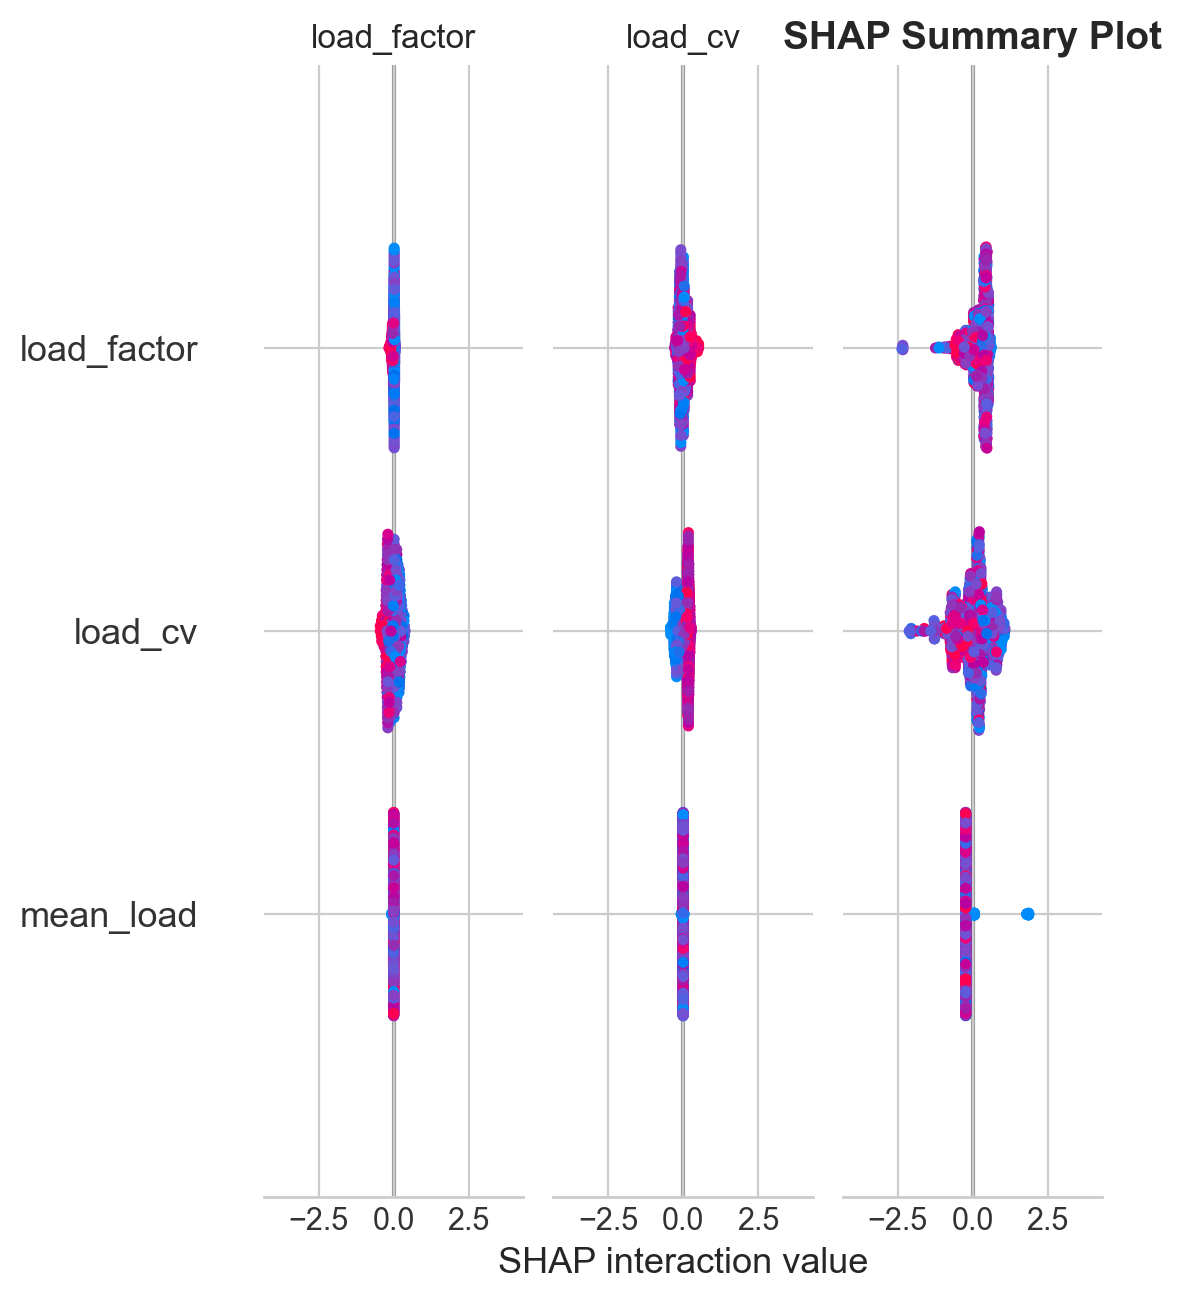

In [21]:
print("=== FEATURE IMPORTANCE GLOBALE (XGBoost) ===")

# Importance par gain
importance_gain = xgb_model.get_booster().get_score(importance_type='gain')
importance_df = pd.DataFrame({
    'feature': [f'f{i}' for i in range(len(FEATURES_FINAL))],
    'feature_name': FEATURES_FINAL,
    'gain': [importance_gain.get(f'f{i}', 0) for i in range(len(FEATURES_FINAL))],
    'cover': [xgb_model.get_booster().get_score(importance_type='cover').get(f'f{i}', 0) for i in range(len(FEATURES_FINAL))],
    'weight': [xgb_model.get_booster().get_score(importance_type='weight').get(f'f{i}', 0) for i in range(len(FEATURES_FINAL))]
})

importance_df = importance_df.sort_values('gain', ascending=True)

# Visualisation de l'importance
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Gain
axes[0].barh(importance_df['feature_name'], importance_df['gain'], color='steelblue')
axes[0].set_title('Importance par Gain', fontweight='bold')
axes[0].set_xlabel('Gain')

# Cover
axes[1].barh(importance_df['feature_name'], importance_df['cover'], color='coral')
axes[1].set_title('Importance par Cover', fontweight='bold')
axes[1].set_xlabel('Cover')

# Weight
axes[2].barh(importance_df['feature_name'], importance_df['weight'], color='seagreen')
axes[2].set_title('Importance par Fréquence', fontweight='bold')
axes[2].set_xlabel('Weight')

plt.suptitle('Feature Importance - XGBoost Surrogate', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nTableau d'importance:")
print(importance_df.sort_values('gain', ascending=False).to_string(index=False))

# =============================================================================
# SHAP VALUES
# =============================================================================
print("\n" + "=" * 60)
print("=== ANALYSE SHAP (SHapley Additive explanations) ===")
print("=" * 60)

# Initialisation du TreeExplainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_features)

print(f"\nShape des SHAP values: {np.array(shap_values).shape}")

# Summary plot global (tous les clusters)
if isinstance(shap_values, list):
    # Multi-classe: moyenne des abs pour visualisation globale
    shap_values_array = np.array(shap_values)
    shap_values_mean = np.mean(np.abs(shap_values_array), axis=0)
    
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_features, feature_names=FEATURES_FINAL, 
                      plot_type="bar", show=False)
    plt.title('Importance Globale des Features (SHAP)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, '22_SHAP_Summary_Plot.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Summary plot par cluster
    for cluster_id in range(len(shap_values)):
        plt.figure(figsize=(10, 8))
        shap.summary_plot(shap_values[cluster_id], X_features, 
                          feature_names=FEATURES_FINAL, show=False)
        plt.title(f'SHAP Summary - Cluster {cluster_id}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(os.path.join(IMAGES_DIR, f'SHAP Summary - Cluster {cluster_id}.png'), dpi=300, bbox_inches='tight')
        plt.show()
else:
    # Binaire
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_features, feature_names=FEATURES_FINAL, show=False)
    plt.title('SHAP Summary Plot', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


## ARBRE DE DÉCISION POUR RÈGLES INTERPRÉTABLES

Entraînement d'un arbre de décision simple pour extraire des règles IF-THEN explicites et interprétables par des non-spécialistes.


=== ARBRE DE DÉCISION - RÈGLES INTERPRÉTABLES ===

Accuracy Arbre de Décision: 0.9837
Profondeur de l'arbre: 2
Nombre de feuilles: 4


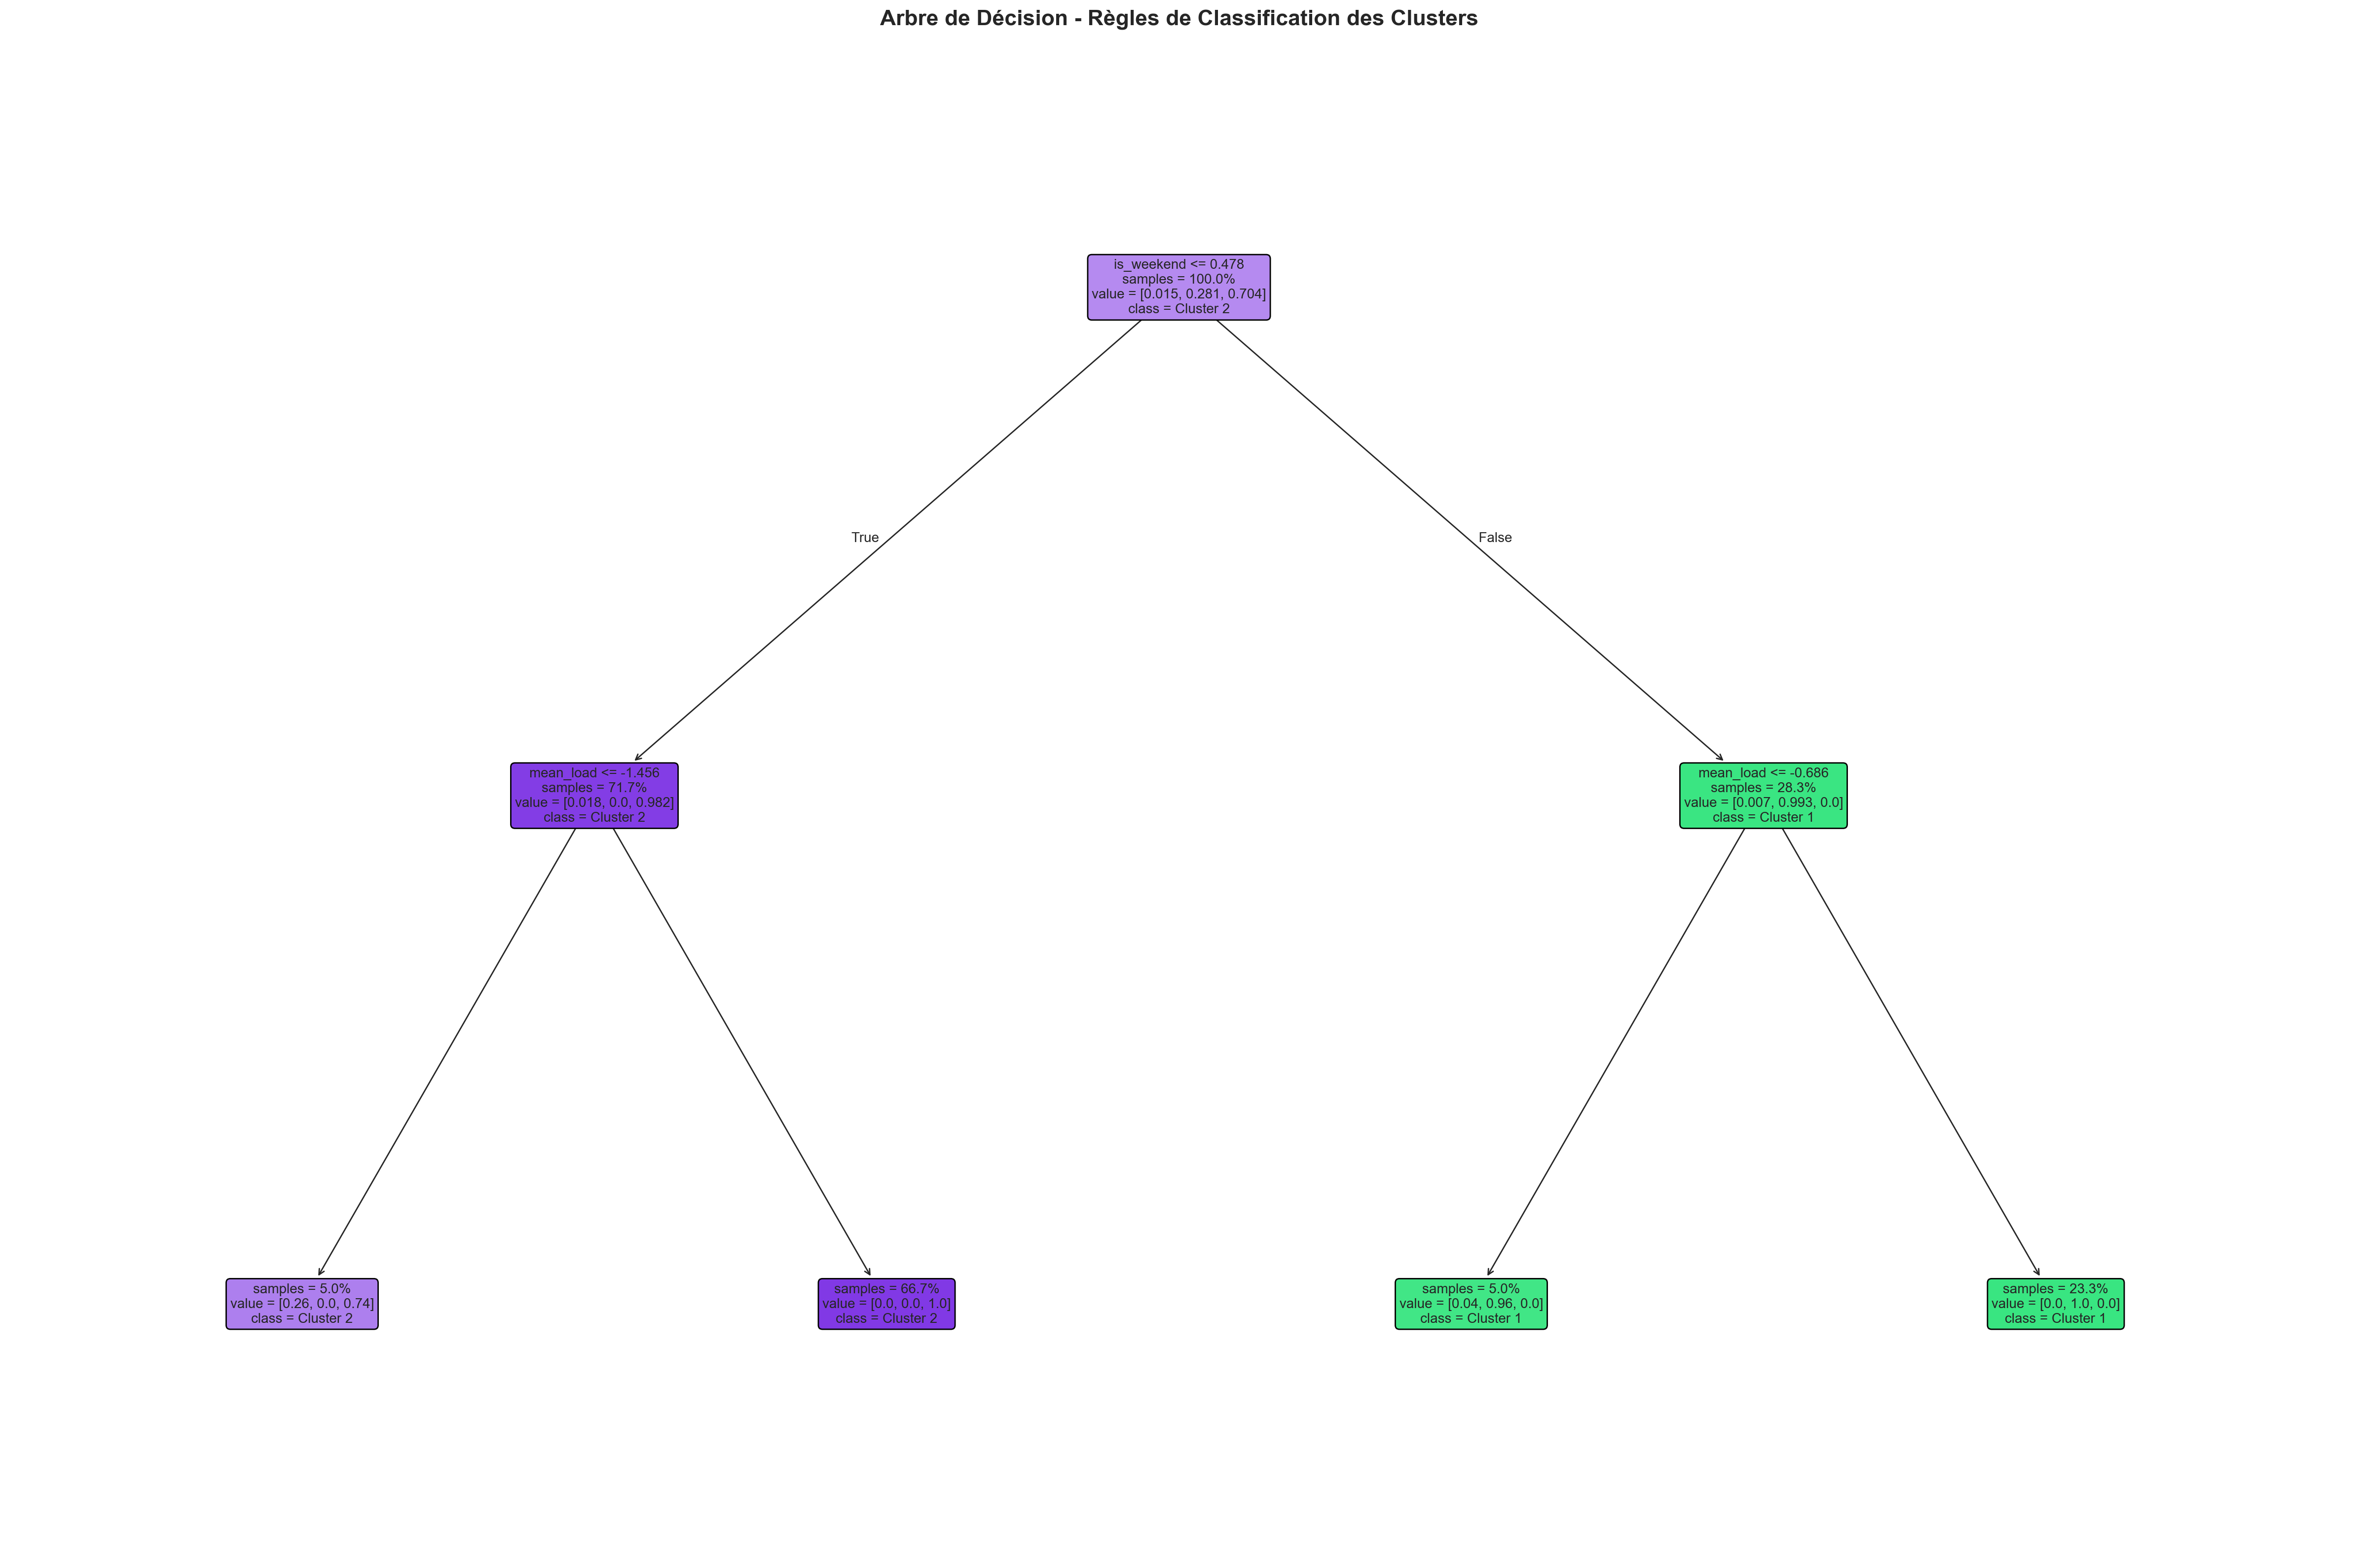


RÈGLES DE DÉCISION (Format Texte)
|--- is_weekend <= 0.48
|   |--- mean_load <= -1.46
|   |   |--- class: 2
|   |--- mean_load >  -1.46
|   |   |--- class: 2
|--- is_weekend >  0.48
|   |--- mean_load <= -0.69
|   |   |--- class: 1
|   |--- mean_load >  -0.69
|   |   |--- class: 1


IMPORTANCE DES FEATURES (Arbre de Décision)
        feature  importance
     is_weekend    0.984039
      mean_load    0.015961
        load_cv    0.000000
    load_factor    0.000000
day_night_ratio    0.000000
       max_load    0.000000
      num_peaks    0.000000


<Figure size 2800x1600 with 0 Axes>

In [22]:

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

print("=== ARBRE DE DÉCISION - RÈGLES INTERPRÉTABLES ===")

# Entraînement d'un arbre de décision (plus simple que XGBoost pour l'interprétation)
dt_model = DecisionTreeClassifier(
    max_depth=4,           # Limiter la profondeur pour l'interprétabilité
    min_samples_leaf=50,   # Éviter le sur-apprentissage
    min_samples_split=100,
    random_state=42,
    criterion='gini'
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

print(f"\nAccuracy Arbre de Décision: {dt_accuracy:.4f}")
print(f"Profondeur de l'arbre: {dt_model.get_depth()}")
print(f"Nombre de feuilles: {dt_model.get_n_leaves()}")

# Visualisation de l'arbre
plt.figure(figsize=(24, 16))
plot_tree(dt_model, 
          feature_names=FEATURES_FINAL,
          class_names=[f'Cluster {i}' for i in sorted(np.unique(y_clusters))],
          filled=True,
          rounded=True,
          fontsize=10,
          impurity=False,
          proportion=True)
plt.title('Arbre de Décision - Règles de Classification des Clusters', 
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '23_Arbre_de_Décision.png'), dpi=300, bbox_inches='tight')
plt.show()

# Extraction des règles en texte
print("\n" + "=" * 60)
print("RÈGLES DE DÉCISION (Format Texte)")
print("=" * 60)
tree_rules = export_text(dt_model, feature_names=FEATURES_FINAL)
print(tree_rules[:3000])  # Afficher les premières règles

# Feature importance de l'arbre
dt_importance = pd.DataFrame({
    'feature': FEATURES_FINAL,
    'importance': dt_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\n" + "=" * 60)
print("IMPORTANCE DES FEATURES (Arbre de Décision)")
print("=" * 60)
print(dt_importance.to_string(index=False))
plt.savefig(os.path.join(IMAGES_DIR, '24_Feature_Importance.png'), dpi=300, bbox_inches='tight')
plt.show()

## VISUALISATIONS FINALES ET INTERPRÉTATION
Visualisations complètes: silhouette, clusters en 2D (UMAP), distributions par feature, et interprétation métier des profils de consommation.

VISUALISATIONS FINALES DES CLUSTERS

Calcul de la projection UMAP 2D...

Projection UMAP 2D calculée
Shape originale: (1431, 7) -> Shape UMAP: (1431, 2)


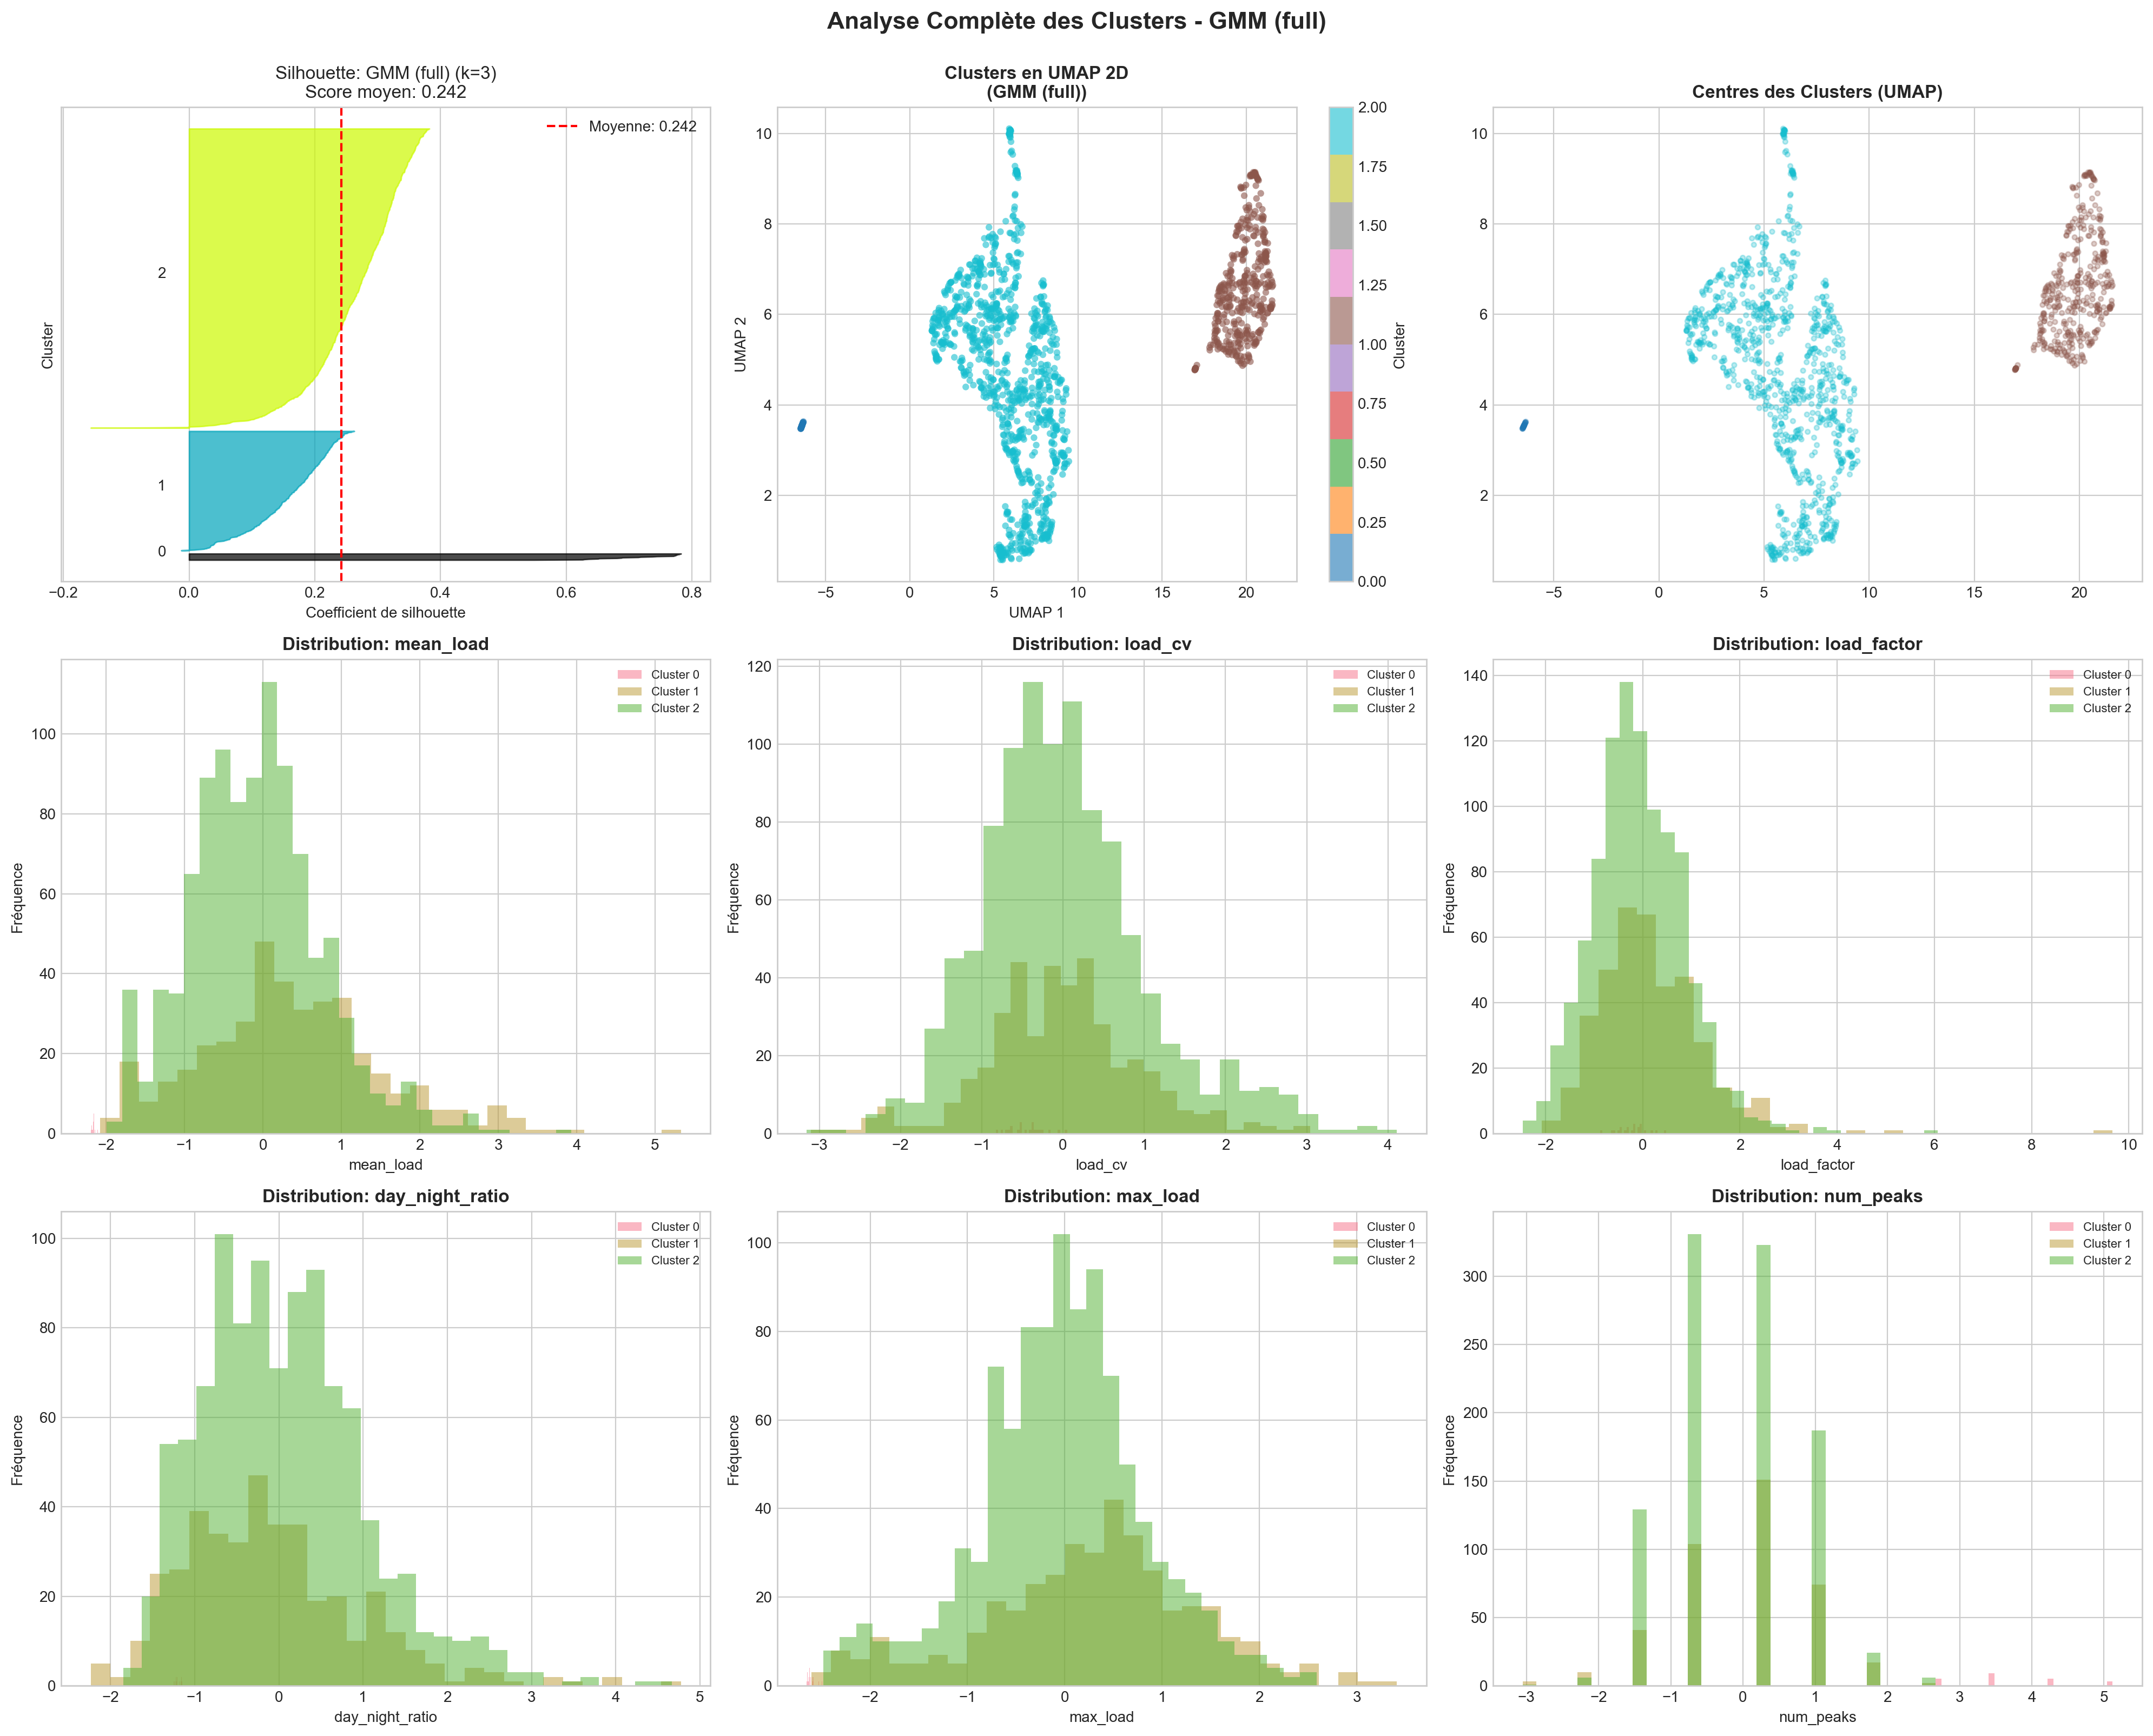

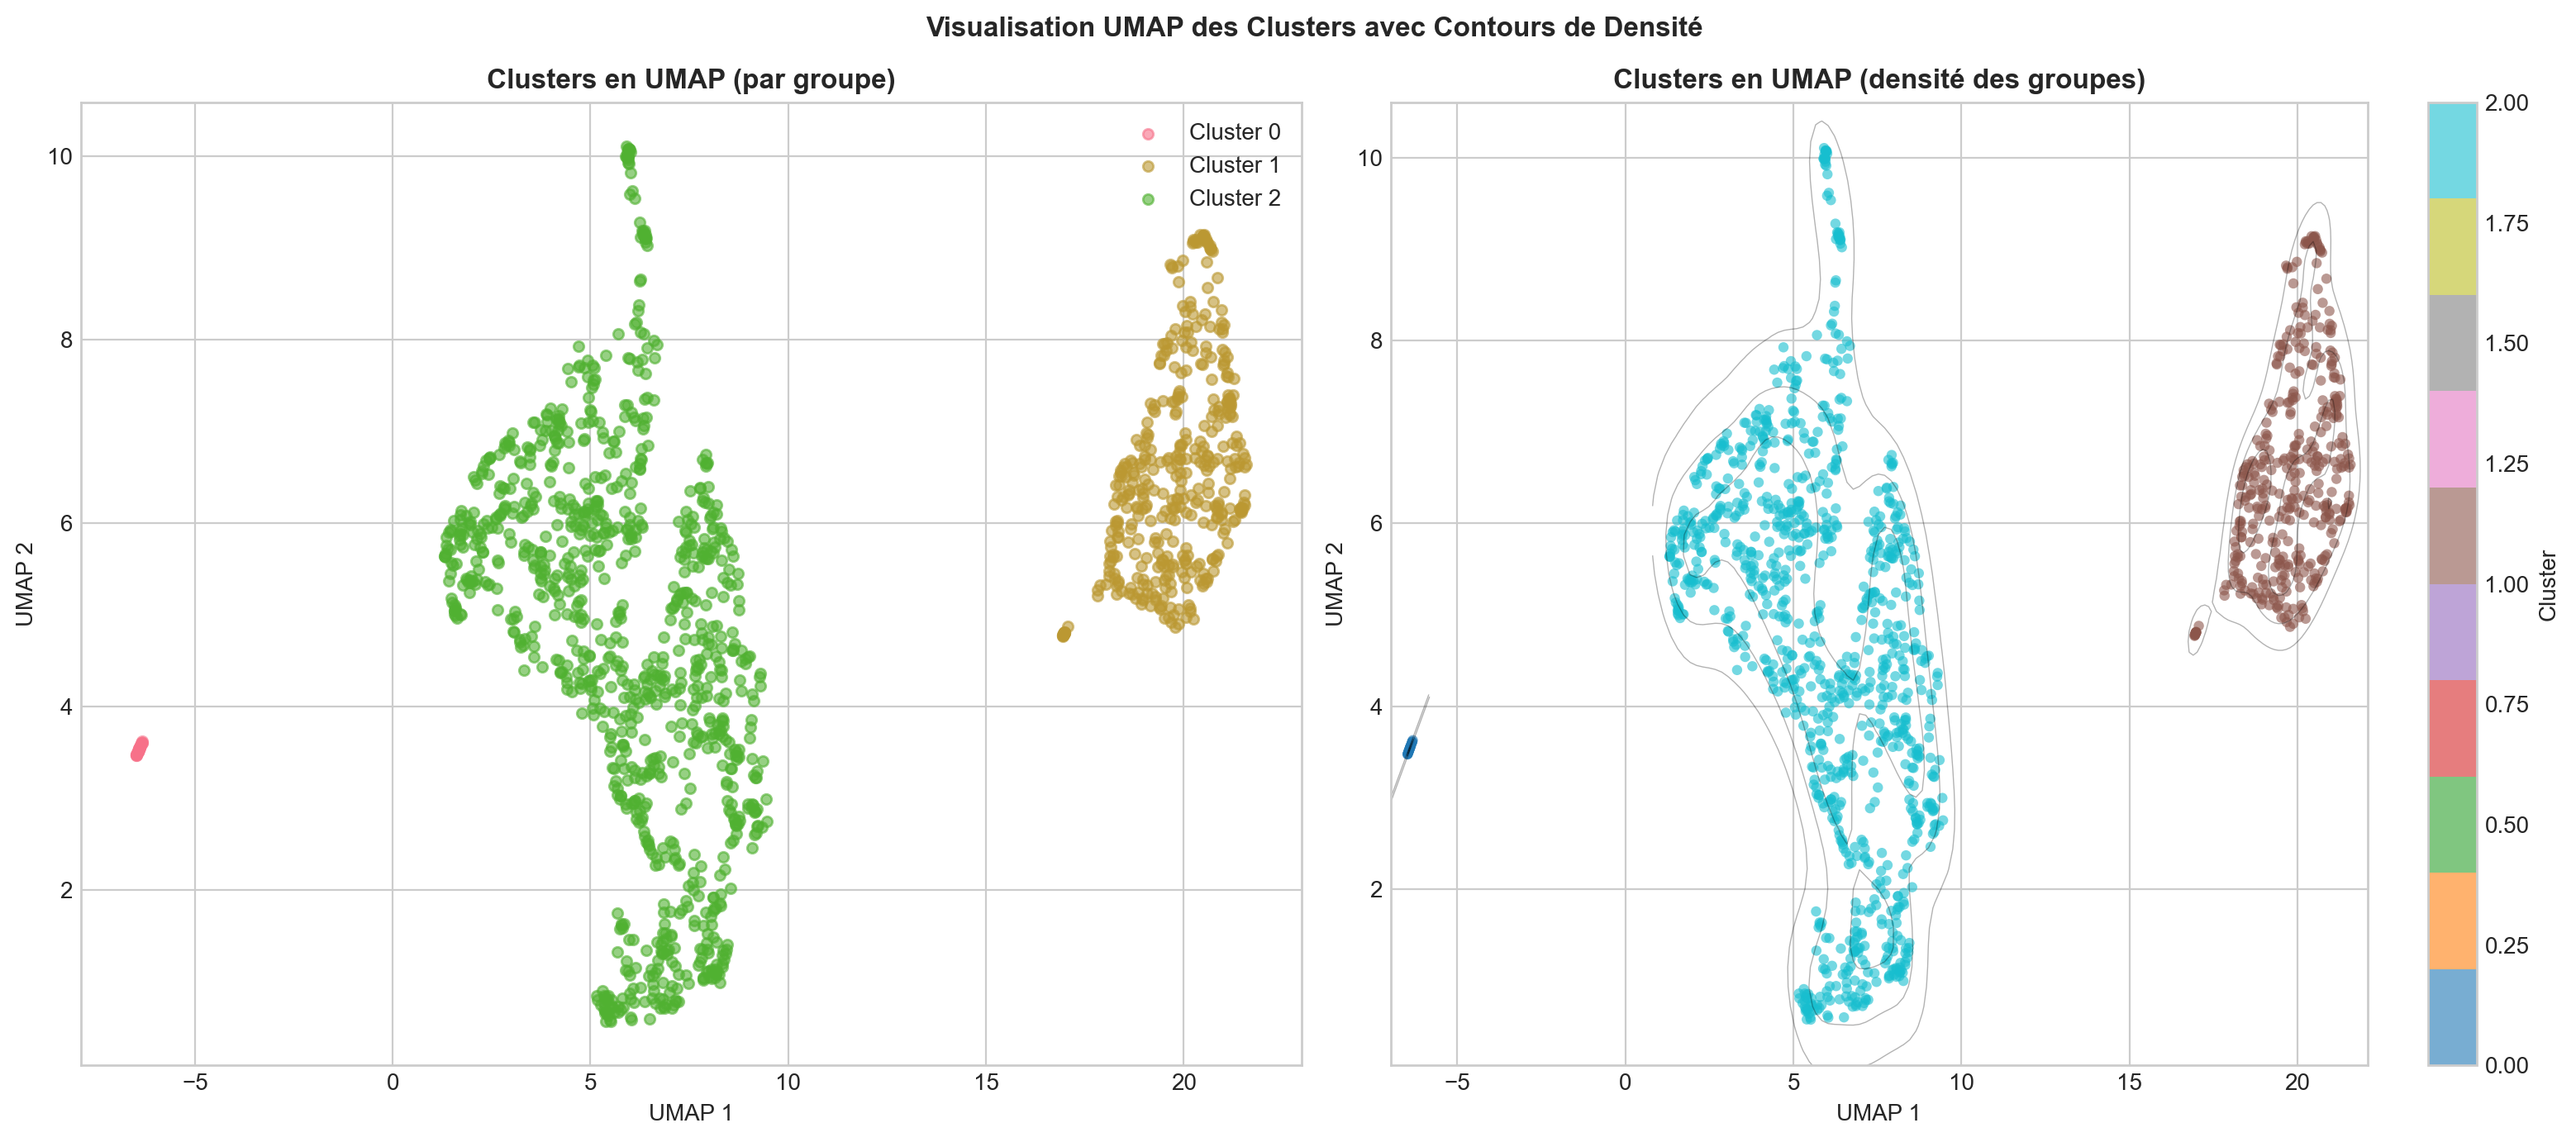

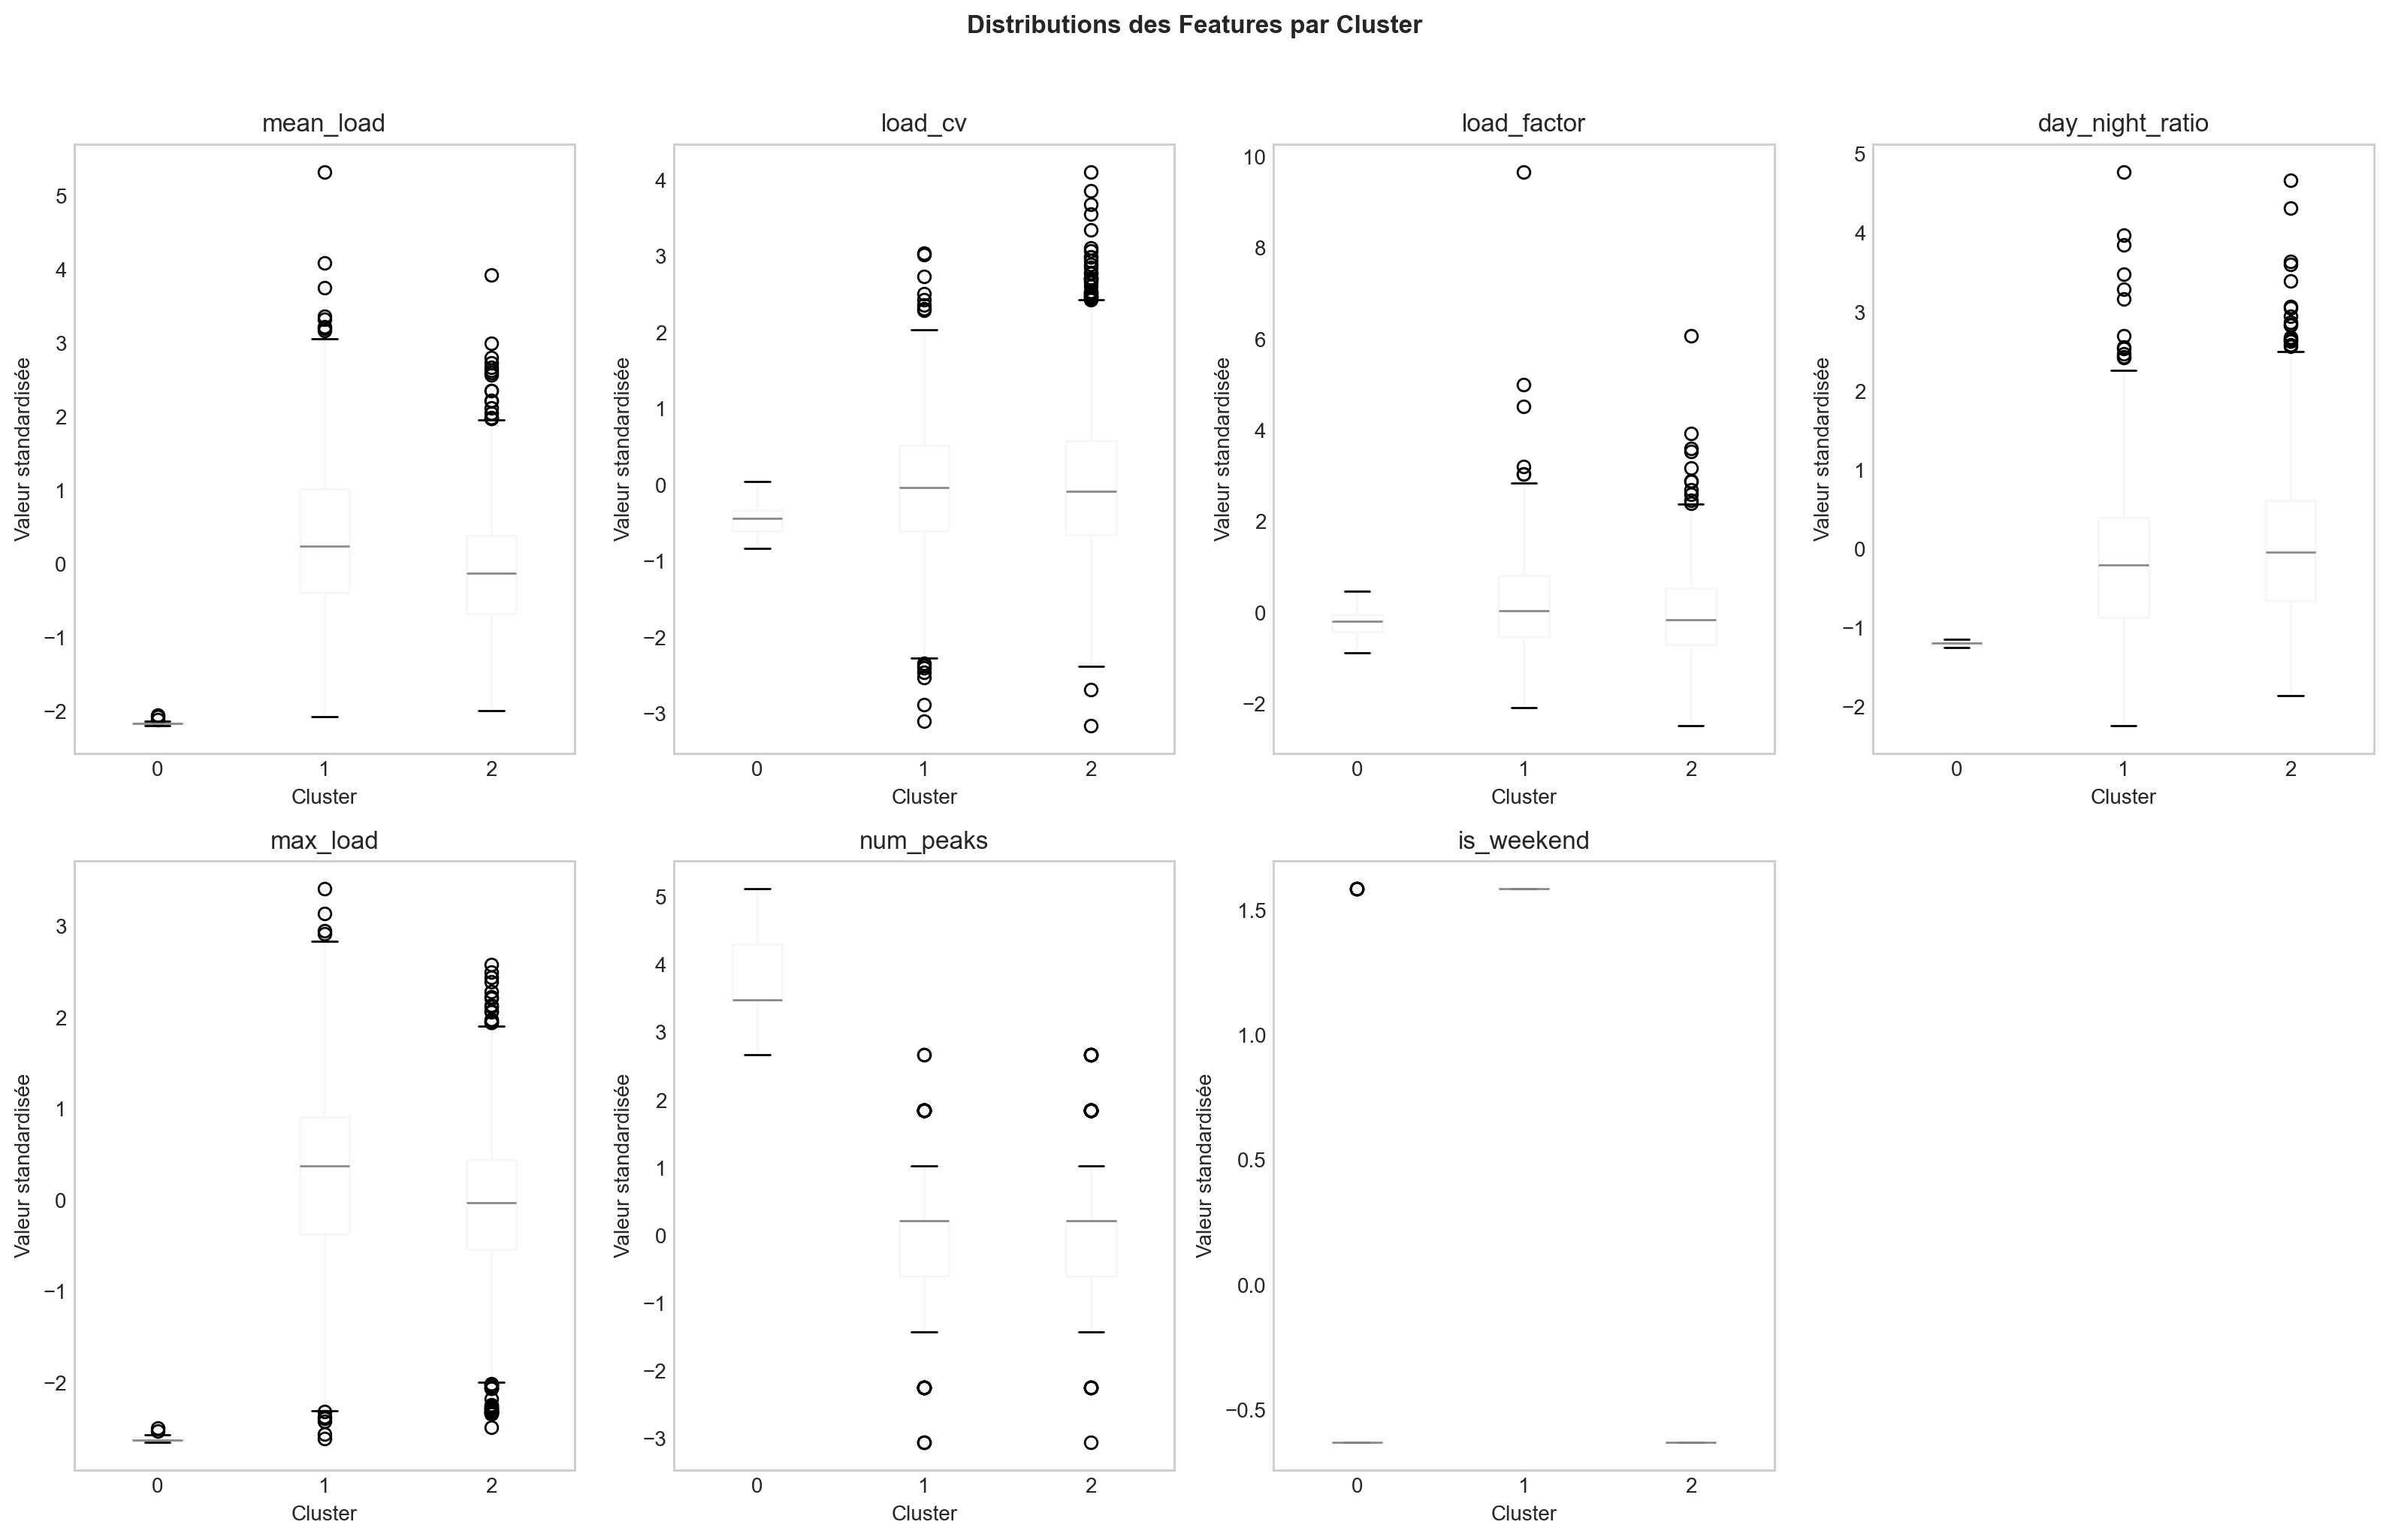


PROFILS MOYENS PAR CLUSTER
         mean_load  load_cv  load_factor  day_night_ratio  max_load  \
cluster                                                               
0           -2.155   -0.442       -0.208           -1.190    -2.608   
1            0.357   -0.016        0.199           -0.094     0.254   
2           -0.095    0.016       -0.075            0.064    -0.045   

         num_peaks  is_weekend  
cluster                         
0            3.708      -0.127  
1           -0.016       1.586  
2           -0.075      -0.630  

INTERPRÉTATION MÉTIER DES CLUSTERS

--- Cluster 0 ---
  Caractéristiques élevées : num_peaks
  Caractéristiques basses : mean_load, day_night_ratio, max_load
  Profil : consommation moyenne basse, nombre de pics élevé

--- Cluster 1 ---
  Caractéristiques élevées : is_weekend
  Profil : forte présence le week-end

--- Cluster 2 ---
  Caractéristiques basses : is_weekend
  Profil : faible activité le week-end

RÉCAPITULATIF FINAL DU CLUSTERING
Mod

In [23]:
# Installer umap-learn si nécessaire: pip install umap-learn
import umap
import os

print("=" * 60)
print("VISUALISATIONS FINALES DES CLUSTERS")
print("=" * 60)

# UMAP pour visualisation 2D (meilleure préservation de la structure locale)
print("\nCalcul de la projection UMAP 2D...")
umap_reducer = umap.UMAP(
    n_neighbors=15,      # Taille du voisinage local
    min_dist=0.1,        # Distance minimale entre points proches
    n_components=2,      # Projection 2D
    random_state=42,
    metric='euclidean'
)
X_umap = umap_reducer.fit_transform(X_features)

print(f"\nProjection UMAP 2D calculée")
print(f"Shape originale: {X_features.shape} -> Shape UMAP: {X_umap.shape}")

# Création d'une grande figure avec plusieurs visualisations
fig = plt.figure(figsize=(20, 16))

# 1. Silhouette plot du modèle final
ax1 = plt.subplot(3, 3, 1)
n_clusters_final = len(np.unique(final_labels[final_labels >= 0]))
if n_clusters_final >= 2:
    plot_silhouette_analysis(X_features, final_labels, 
                             f"{best_model_name} (k={n_clusters_final})", ax=ax1)

# 2. Clusters en UMAP 2D
ax2 = plt.subplot(3, 3, 2)
scatter = ax2.scatter(X_umap[:, 0], X_umap[:, 1], c=final_labels, cmap='tab10', 
                      alpha=0.6, s=20, edgecolors='none')
ax2.set_title(f'Clusters en UMAP 2D\n({best_model_name})', fontweight='bold')
ax2.set_xlabel('UMAP 1')
ax2.set_ylabel('UMAP 2')
plt.colorbar(scatter, ax=ax2, label='Cluster')

# 3. Centroids / Medoids projetés en UMAP
ax3 = plt.subplot(3, 3, 3)
# Pour projeter les centres, on les passe dans le même UMAP
# Note: UMAP n'a pas de transform() comme PCA, on utilise les coordonnées approximatives
if hasattr(final_model, 'cluster_centers_'):
    # Trouver les points les plus proches des centroids pour les projeter
    from sklearn.neighbors import NearestNeighbors
    nn = NearestNeighbors(n_neighbors=1).fit(X_features)
    _, idx = nn.kneighbors(final_model.cluster_centers_)
    centers_umap = X_umap[idx.flatten()]
    ax3.scatter(centers_umap[:, 0], centers_umap[:, 1], c='red', s=200, 
                marker='X', edgecolors='black', linewidths=2, label='Centroids', zorder=5)
elif hasattr(final_model, 'medoids_'):
    # Les medoids sont des points réels du dataset
    medoid_indices = final_model.medoids_indices_
    medoids_umap = X_umap[medoid_indices]
    ax3.scatter(medoids_umap[:, 0], medoids_umap[:, 1], c='red', s=200,
                marker='X', edgecolors='black', linewidths=2, label='Medoids', zorder=5)
ax3.scatter(X_umap[:, 0], X_umap[:, 1], c=final_labels, cmap='tab10', alpha=0.3, s=10)
ax3.set_title('Centres des Clusters (UMAP)', fontweight='bold')
ax3.legend()

# 4-9. Distribution par cluster pour chaque feature
feature_positions = [(3, 3, 4), (3, 3, 5), (3, 3, 6), (3, 3, 7), (3, 3, 8), (3, 3, 9)]
for idx, (feature, pos) in enumerate(zip(FEATURES_FINAL[:6], feature_positions)):
    ax = plt.subplot(*pos)
    for cluster_id in sorted(np.unique(final_labels)):
        if cluster_id == -1:
            continue  # Skip noise (DBSCAN)
        cluster_data = df_scaled[df_scaled['cluster'] == cluster_id][feature]
        ax.hist(cluster_data, bins=30, alpha=0.5, label=f'Cluster {cluster_id}')
    ax.set_title(f'Distribution: {feature}', fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel('Fréquence')
    ax.legend(fontsize=8)

plt.suptitle(f'Analyse Complète des Clusters - {best_model_name}', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '25_Analyse_Complète_des_lusters.png'), dpi=300, bbox_inches='tight')
plt.show()



# =============================================================================
# UMAP avec contours de densité par cluster (suite)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# UMAP avec labels de cluster
ax1 = axes[0]
for cluster_id in sorted(np.unique(final_labels)):
    if cluster_id == -1:
        mask = final_labels == -1
        ax1.scatter(X_umap[mask, 0], X_umap[mask, 1], c='gray', 
                   alpha=0.3, s=10, label='Bruit (DBSCAN)')
    else:
        mask = final_labels == cluster_id
        ax1.scatter(X_umap[mask, 0], X_umap[mask, 1], 
                   alpha=0.6, s=20, label=f'Cluster {cluster_id}')
ax1.set_title('Clusters en UMAP (par groupe)', fontweight='bold')
ax1.set_xlabel('UMAP 1')
ax1.set_ylabel('UMAP 2')
ax1.legend()

# UMAP avec densité (suite)
ax2 = axes[1]
scatter = ax2.scatter(X_umap[:, 0], X_umap[:, 1], c=final_labels, cmap='tab10',
                      alpha=0.6, s=20, edgecolors='none')
ax2.set_title('Clusters en UMAP (densité des groupes)', fontweight='bold')
ax2.set_xlabel('UMAP 1')
ax2.set_ylabel('UMAP 2')

# Ajout des contours de densité par cluster
from scipy.stats import gaussian_kde
for cluster_id in sorted(np.unique(final_labels)):
    if cluster_id == -1:
        continue
    mask = final_labels == cluster_id
    points = X_umap[mask]
    if len(points) > 5:
        try:
            kde = gaussian_kde(points.T)
            xmin, xmax = points[:,0].min() - 0.5, points[:,0].max() + 0.5
            ymin, ymax = points[:,1].min() - 0.5, points[:,1].max() + 0.5
            xx, yy = np.meshgrid(np.linspace(xmin, xmax, 50), np.linspace(ymin, ymax, 50))
            positions = np.vstack([xx.ravel(), yy.ravel()])
            z = kde(positions).reshape(xx.shape)
            ax2.contour(xx, yy, z, levels=3, colors='black', alpha=0.3, linewidths=0.5)
        except:
            pass
plt.colorbar(scatter, ax=ax2, label='Cluster')
plt.suptitle('Visualisation UMAP des Clusters avec Contours de Densité', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '26_Visualisation_UMAP.png'), dpi=300, bbox_inches='tight')
plt.show()

# =============================================================================
# Boxplots des features par cluster
# =============================================================================
fig, axes = plt.subplots(2, 4, figsize=(16, 10))
axes = axes.flatten()
for idx, feature in enumerate(FEATURES_FINAL):
    ax = axes[idx]
    data = df_scaled[[feature, 'cluster']].copy()
    data.boxplot(column=feature, by='cluster', ax=ax, grid=False)
    ax.set_title(f'{feature}')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Valeur standardisée')
# Supprimer les subplots vides (s'il y a moins de 8 features)
for j in range(len(FEATURES_FINAL), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle('Distributions des Features par Cluster', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '27_Distributions_des_Features_par_Cluster.png'), dpi=300, bbox_inches='tight')
plt.show()

# =============================================================================
# PROFILS MOYENS ET INTERPRÉTATION MÉTIER
# =============================================================================
cluster_means = df_scaled.groupby('cluster')[FEATURES_FINAL].mean()
cluster_std = df_scaled.groupby('cluster')[FEATURES_FINAL].std()

print("\n" + "="*70)
print("PROFILS MOYENS PAR CLUSTER")
print("="*70)
print(cluster_means.round(3))

# Interprétation qualitative
print("\n" + "="*70)
print("INTERPRÉTATION MÉTIER DES CLUSTERS")
print("="*70)

for cluster_id in sorted(cluster_means.index):
    if cluster_id == -1:
        print(f"\nCluster Bruit (DBSCAN) : points non assignés")
        continue
    mean = cluster_means.loc[cluster_id]
    print(f"\n--- Cluster {cluster_id} ---")
    # Caractéristiques saillantes
    high_features = mean[mean > 0.5].index.tolist()
    low_features = mean[mean < -0.5].index.tolist()
    if high_features:
        print(f"  Caractéristiques élevées : {', '.join(high_features)}")
    if low_features:
        print(f"  Caractéristiques basses : {', '.join(low_features)}")
    # Description métier
    description = []
    if 'mean_load' in high_features:
        description.append("consommation moyenne élevée")
    elif 'mean_load' in low_features:
        description.append("consommation moyenne basse")
    if 'is_weekend' in high_features:
        description.append("forte présence le week-end")
    elif 'is_weekend' in low_features:
        description.append("faible activité le week-end")
    if 'load_cv' in high_features:
        description.append("forte variabilité de la charge")
    if 'num_peaks' in high_features:
        description.append("nombre de pics élevé")
    if description:
        print(f"  Profil : {', '.join(description)}")
    else:
        print("  Profil modéré, proche de la moyenne générale.")

# =============================================================================
# RÉCAPITULATIF FINAL
# =============================================================================
print("\n" + "="*70)
print("RÉCAPITULATIF FINAL DU CLUSTERING")
print("="*70)
print(f"Modèle sélectionné : {best_model_name}")
print(f"Nombre de clusters : {len(np.unique(final_labels[final_labels >= 0]))}")
print(f"Taille des clusters :")
for cluster_id in sorted(np.unique(final_labels)):
    if cluster_id == -1:
        print(f"  Bruit : {np.sum(final_labels == -1)} points")
    else:
        print(f"  Cluster {cluster_id} : {np.sum(final_labels == cluster_id)} jours")

🧪 RÉSULTATS DU CLUSTERING SANS is_weekend
📊 Distribution des nouveaux clusters :
   Nouveau Cluster 0 : 153 jours
   Nouveau Cluster 1 : 526 jours
   Nouveau Cluster 2 : 737 jours

📈 Indice de Rand Ajusté (ARI) : 0.0612
   (Interprétation : 1.0 = identique, 0.0 = indépendant)


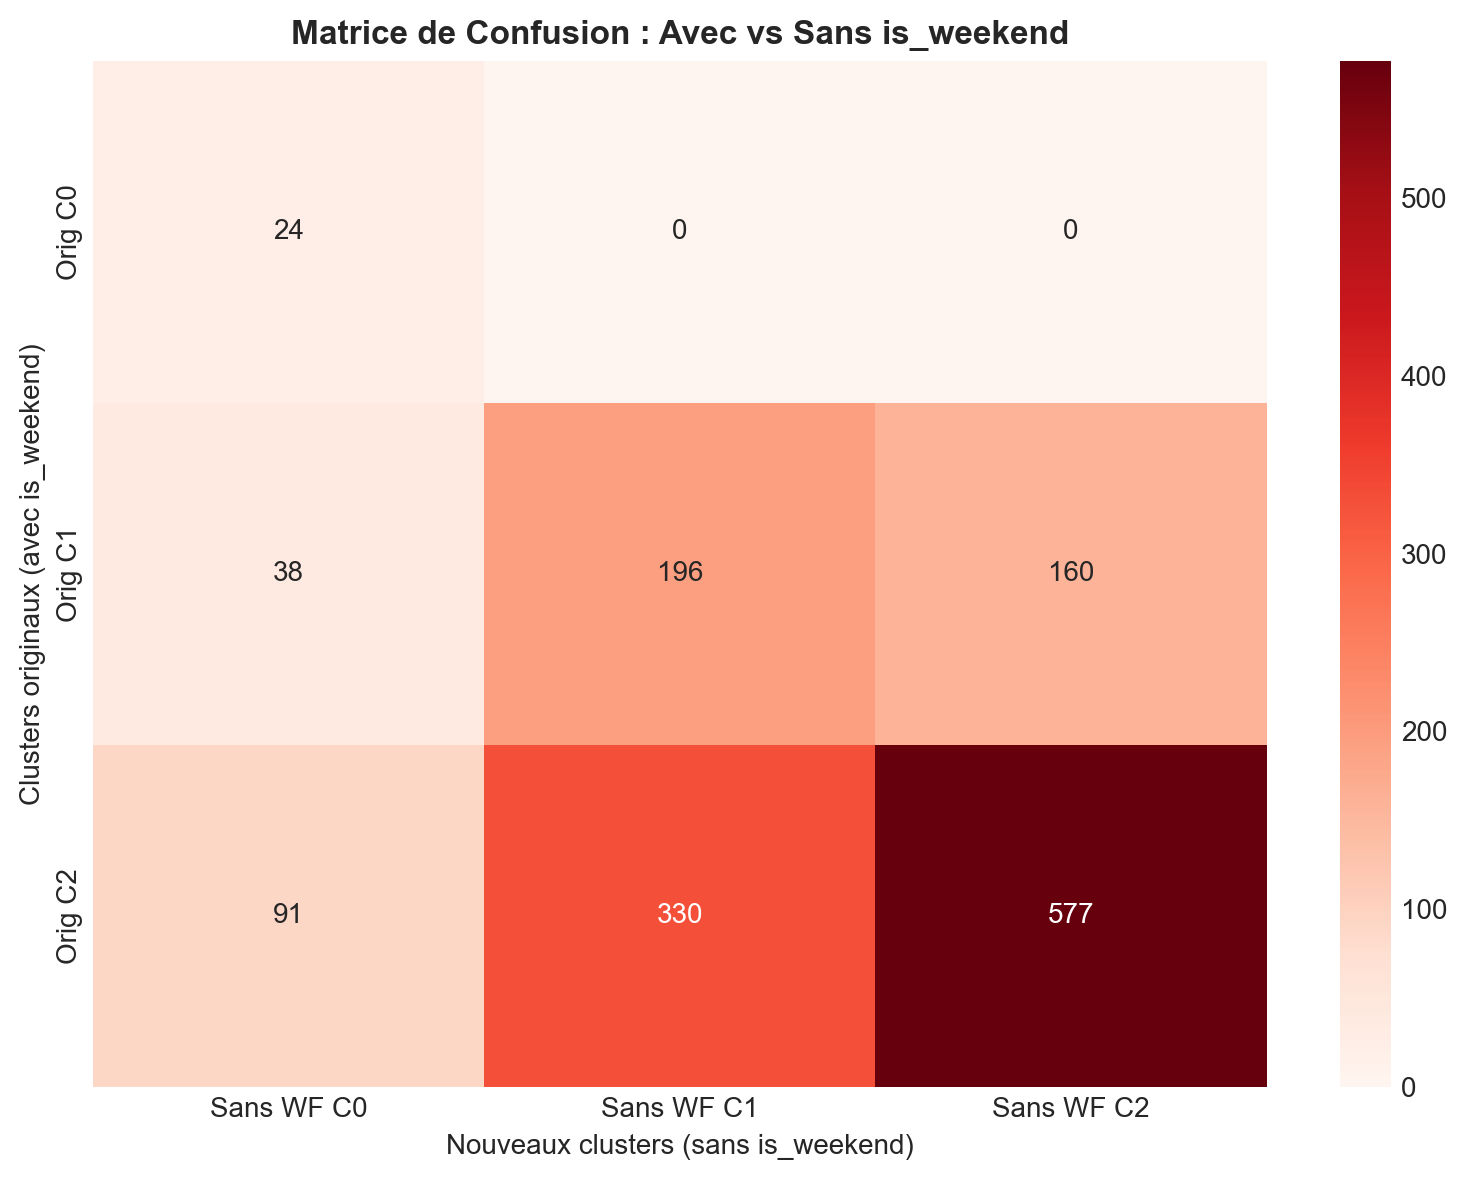


✓ Profils horaires alignés (sans weekend) : 1416 jours


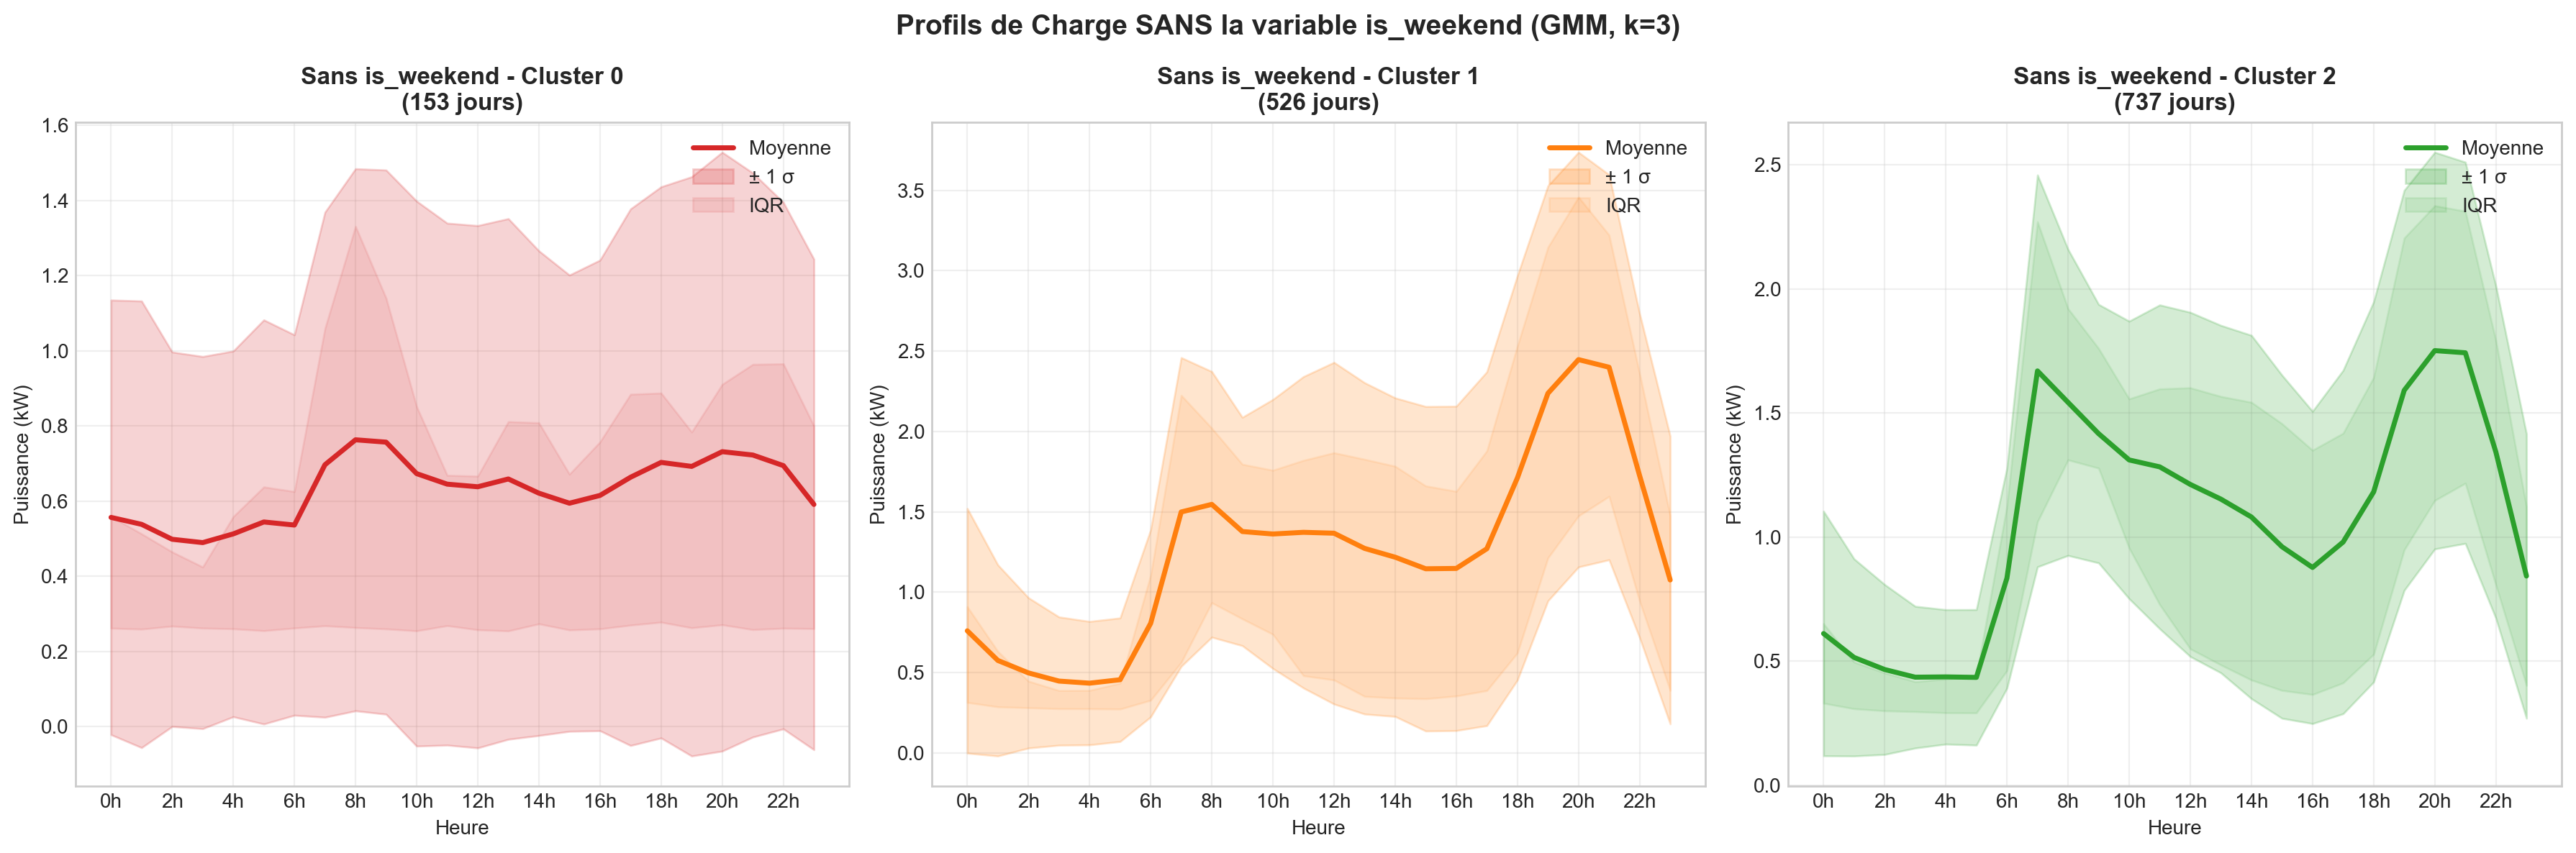


✓ Figure sauvegardée : Load_Curves_Without_Weekend.png
=== INTERPRÉTATION DES NOUVEAUX CLUSTERS (Sans is_weekend) ===

--- Nouveau Cluster 0 (153 jours) ---
  ➜ Niveau de consommation : ÉLEVÉ
  ➜ Activité : TRÈS FRAGMENTÉE (multiples pics)
  ➜ Stabilité : TRÈS VARIABLE
  ➜ Forme : TRÈS PLATE (consommation continue)

--- Nouveau Cluster 1 (526 jours) ---
  ➜ Niveau de consommation : ÉLEVÉ
  ➜ Activité : TRÈS FRAGMENTÉE (multiples pics)
  ➜ Stabilité : TRÈS VARIABLE
  ➜ Forme : TRÈS PLATE (consommation continue)

--- Nouveau Cluster 2 (737 jours) ---
  ➜ Niveau de consommation : ÉLEVÉ
  ➜ Activité : TRÈS FRAGMENTÉE (multiples pics)
  ➜ Stabilité : TRÈS VARIABLE
  ➜ Forme : TRÈS PLATE (consommation continue)


In [ ]:
# ================================================================
# SCÉNARIO : CLUSTERING SANS is_weekend
# (Test de l'influence réelle de la variable)
# ================================================================

# --- 1. Préparation des données sans is_weekend ---
FEATURES_WITHOUT_WEEKEND = ['mean_load', 'load_cv', 'load_factor', 
                            'day_night_ratio', 'max_load', 'num_peaks']

X_without = df_features[FEATURES_WITHOUT_WEEKEND].values

# --- 2. Standardisation (sur ce nouveau sous-ensemble) ---
scaler_without = StandardScaler()
X_scaled_without = scaler_without.fit_transform(X_without)

# --- 3. Entraînement du GMM (k=3, full covariance) ---
gmm_without = GaussianMixture(n_components=3, covariance_type='full', 
                              random_state=42, max_iter=200, n_init=10)
labels_without = gmm_without.fit_predict(X_scaled_without)

# --- 4. Réordonner par taille (pour cohérence visuelle) ---
unique_wout, counts_wout = np.unique(labels_without, return_counts=True)
sorted_idx_wout = np.argsort(counts_wout)  # 0 = plus petit, 2 = plus grand
mapping_wout = {old: new for new, old in enumerate(sorted_idx_wout)}
labels_without_ordered = np.array([mapping_wout[l] for l in labels_without])

# Ajouter ces nouveaux labels au DataFrame (avec la date)
df_features['cluster_without_weekend'] = labels_without_ordered

print("="*60)
print("RÉSULTATS DU CLUSTERING SANS is_weekend")
print("="*60)
print(f"   Distribution des nouveaux clusters :")
print(f"   Nouveau Cluster 0 : {np.sum(labels_without_ordered == 0)} jours")
print(f"   Nouveau Cluster 1 : {np.sum(labels_without_ordered == 1)} jours")
print(f"   Nouveau Cluster 2 : {np.sum(labels_without_ordered == 2)} jours")

# --- 5. Comparaison avec la segmentation originale (ARI) ---
# Récupérer les labels originaux (ceux que vous venez de calculer)
original_labels = df_features['cluster'].values  # Ceux avec is_weekend

ari_score = adjusted_rand_score(original_labels, labels_without_ordered)
print(f"\n Indice de Rand Ajusté (ARI) : {ari_score:.4f}")
print("   (Interprétation : 1.0 = identique, 0.0 = indépendant)")

# --- 6. Matrice de confusion (pour voir le mouvement des jours) ---
cm_without = confusion_matrix(original_labels, labels_without_ordered)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_without, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Sans WF C0', 'Sans WF C1', 'Sans WF C2'],
            yticklabels=['Orig C0', 'Orig C1', 'Orig C2'])
plt.title('Matrice de Confusion : Avec vs Sans is_weekend', fontweight='bold')
plt.xlabel('Nouveaux clusters (sans is_weekend)')
plt.ylabel('Clusters originaux (avec is_weekend)')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '28_Confusion_With_vs_Without_Weekend.png'), dpi=300)
plt.show()

# --- 7. Visualisation des COURBES DE CHARGE sans is_weekend ---
# Fusionner les nouveaux labels avec les profils horaires
date_cluster_mapping_wout = df_features[['date', 'cluster_without_weekend']].copy()
daily_profiles_wout = daily_profiles.merge(
    date_cluster_mapping_wout,
    left_index=True,
    right_on='date',
    how='inner'
).set_index('date')

print(f"\n✓ Profils horaires alignés (sans weekend) : {daily_profiles_wout.shape[0]} jours")

# Tracer les courbes
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors_wout = ['#d62728', '#ff7f0e', '#2ca02c']  # Rouge, Orange, Vert
clusters_wout = sorted(daily_profiles_wout['cluster_without_weekend'].unique())

for i, cluster_id in enumerate(clusters_wout):
    ax = axes[i]
    cluster_data = daily_profiles_wout[daily_profiles_wout['cluster_without_weekend'] == cluster_id]
    cluster_curves = cluster_data.drop(columns='cluster_without_weekend')
    
    mean_curve = cluster_curves.mean(axis=0)
    std_curve = cluster_curves.std(axis=0)
    q25 = cluster_curves.quantile(0.25, axis=0)
    q75 = cluster_curves.quantile(0.75, axis=0)
    
    hours = range(24)
    ax.plot(hours, mean_curve, color=colors_wout[i], linewidth=2.5, label='Moyenne')
    ax.fill_between(hours, mean_curve - std_curve, mean_curve + std_curve, 
                    color=colors_wout[i], alpha=0.2, label='± 1 σ')
    ax.fill_between(hours, q25, q75, color=colors_wout[i], alpha=0.1, label='IQR')
    
    # Interprétation automatique basée sur la taille et la forme
    size = len(cluster_curves)
    if cluster_id == 0:  # Le plus petit
        name = "Très faible conso"
    elif cluster_id == 1:  # Moyen
        name = "Conso moyenne / fragmentée"
    else:  # Le plus grand
        name = "Conso standard"
        
    ax.set_title(f'Sans is_weekend - Cluster {cluster_id}\n({size} jours)', fontweight='bold')
    ax.set_xlabel('Heure')
    ax.set_ylabel('Puissance (kW)')
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels([f'{h}h' for h in range(0, 24, 2)])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

plt.suptitle('Profils de Charge SANS la variable is_weekend (GMM, k=3)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '29_Load_Curves_Without_Weekend.png'), dpi=300)
plt.show()

print("\n✓ Figure sauvegardée : Load_Curves_Without_Weekend.png")

# --- 8. Analyse rapide des caractéristiques des nouveaux clusters ---
print("=== INTERPRÉTATION DES NOUVEAUX CLUSTERS (Sans is_weekend) ===")
# Moyennes des features pour chaque nouveau cluster
new_means = df_features.groupby('cluster_without_weekend')[FEATURES_WITHOUT_WEEKEND].mean()

for c in sorted(new_means.index):
    mean = new_means.loc[c]
    size = np.sum(labels_without_ordered == c)
    print(f"\n--- Nouveau Cluster {c} ({size} jours) ---")
    high = mean[mean > 0.3].index.tolist() if hasattr(mean, 'index') else []
    low = mean[mean < -0.3].index.tolist() if hasattr(mean, 'index') else []
    
    # Utiliser les noms des features brutes pour l'interprétation
    if 'mean_load' in high:
        print("  ➜ Niveau de consommation : ÉLEVÉ")
    elif 'mean_load' in low:
        print("  ➜ Niveau de consommation : FAIBLE")
    else:
        print("  ➜ Niveau de consommation : MOYEN")
        
    if 'num_peaks' in high:
        print("  ➜ Activité : TRÈS FRAGMENTÉE (multiples pics)")
    if 'load_cv' in high:
        print("  ➜ Stabilité : TRÈS VARIABLE")
    if 'load_factor' in high:
        print("  ➜ Forme : TRÈS PLATE (consommation continue)")